In [1]:
# ============================================
# CELL 1 — INSTALL REQUIRED LIBRARIES
# ============================================

!pip -q install xgboost lightgbm catboost shap optuna

print("Required libraries installed successfully.")

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 97.1/97.1 MB 8.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 442.4/442.4 kB 9.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 268.7/268.7 kB 9.1 MB/s eta 0:00:00
Required libraries installed successfully.


In [2]:
# ============================================
# CELL 2 — IMPORT LIBRARIES
# ============================================

import os
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd

import matplotlib.pyplot as plt

from sklearn.model_selection import (
    TimeSeriesSplit,
    GroupKFold
)

from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

from sklearn.impute import SimpleImputer

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

from sklearn.dummy import DummyRegressor
from sklearn.linear_model import Ridge
from sklearn.ensemble import (
    RandomForestRegressor,
    GradientBoostingRegressor
)

from sklearn.svm import SVR

from xgboost import XGBRegressor
from lightgbm import LGBMRegressor
from catboost import CatBoostRegressor

import shap

print("Libraries imported successfully.")

Libraries imported successfully.


In [3]:
# ============================================
# CELL 3 — UPLOAD DATASET
# ============================================

from google.colab import files

uploaded = files.upload()

print("\nUploaded files:")
for filename in uploaded.keys():
    print(filename)

Saving MultiCrop_Carbon_Integrated_v3_Filled_Estimates.csv to MultiCrop_Carbon_Integrated_v3_Filled_Estimates.csv

Uploaded files:
MultiCrop_Carbon_Integrated_v3_Filled_Estimates.csv


In [4]:
# ============================================
# CELL 4 — LOAD DATASET
# ============================================

FILE_NAME = "MultiCrop_Carbon_Integrated_v3_Filled_Estimates.csv"

df = pd.read_csv(FILE_NAME)

print("Dataset loaded successfully.")
print("Shape:", df.shape)

Dataset loaded successfully.
Shape: (9523, 39)


In [5]:
# ============================================
# CELL 5 — FIRST 5 ROWS
# ============================================

pd.set_option("display.max_columns", None)

display(df.head())

,Country,Country_Code,Crop,Year,Area_Harvested_ha_Derived,Production_tonnes,Yield_t_per_ha,National_N_Fertilizer_Use_tonnes,National_P2O5_Fertilizer_Use_tonnes,National_K2O_Fertilizer_Use_tonnes,Annual_Temperature_C_Proxy,Annual_Rainfall_mm_day_Proxy,Annual_Humidity_pct_Proxy,Annual_Solar_Radiation_MJ_m2_day_Proxy,Growing_Season_Temperature_C,Growing_Season_Rainfall_mm,Growing_Season_Humidity_pct,Growing_Season_Solar_Radiation,Temperature_Anomaly,Rainfall_Anomaly,Climate_Proxy_Flag,Crop_GHG_CommonBoundary_kgCO2e,Crop_GHG_ExtendedBoundary_kgCO2e,Carbon_Footprint_kgCO2e_per_tonne,Carbon_Footprint_kgCO2e_per_ha,Emission_Boundary_Code,Target_Status,Area_Method,Climate_Method,Production_Source,Fertilizer_Source,Climate_Source,Climate_Estimation_Method,GHG_Estimate_Flag,GHG_Estimation_Method,Carbon_Reference_Product,Carbon_Reference_Intensity_kgCO2e_per_kg,CommonBoundary_Share_Assumption,Reference_IDs
0,Argentina,ARG,Rice,1990,116619.90,428100.0,3.67,101400,51500,12600.0,16.99,4.10,79.29,17.08,18.99,768.750,83.29,16.226,-0.803,199.500,1,1.552338e+09,1.940423e+09,3626.112,13311.093,MODEL_COMMON_PRODUCTION_STAGE_V1,REFERENCE_ANCHORED_MODEL_ESTIMATE,DERIVED_FROM_PRODUCTION_AND_YIELD,MODELED_CROP_SEASON_FROM_ANNUAL_NASA_POWER_PROXY,FAOSTAT Crops and livestock products (working ...,FAOSTAT Fertilizers by Nutrient (national agri...,NASA POWER annual representative-point proxy,Annual NASA POWER proxy transformed with crop-...,1,Reference-anchored predictive estimate. Global...,Rice,4.45,0.8,R1;R2;R3;R4
1,Argentina,ARG,Rice,1991,86265.95,347600.0,4.03,95700,54500,17100.0,17.37,3.45,78.14,16.52,19.37,646.875,82.14,15.694,-0.423,77.625,1,1.224925e+09,1.531156e+09,3523.950,14199.404,MODEL_COMMON_PRODUCTION_STAGE_V1,REFERENCE_ANCHORED_MODEL_ESTIMATE,DERIVED_FROM_PRODUCTION_AND_YIELD,MODELED_CROP_SEASON_FROM_ANNUAL_NASA_POWER_PROXY,FAOSTAT Crops and livestock products (working ...,FAOSTAT Fertilizers by Nutrient (national agri...,NASA POWER annual representative-point proxy,Annual NASA POWER proxy transformed with crop-...,1,Reference-anchored predictive estimate. Global...,Rice,4.45,0.8,R1;R2;R3;R4
2,Argentina,ARG,Rice,1992,140700.90,732700.0,5.21,146600,83600,18000.0,16.75,3.18,77.93,17.77,18.75,596.250,81.93,16.881,-1.043,27.000,1,2.412624e+09,3.015780e+09,3292.786,17147.184,MODEL_COMMON_PRODUCTION_STAGE_V1,REFERENCE_ANCHORED_MODEL_ESTIMATE,DERIVED_FROM_PRODUCTION_AND_YIELD,MODELED_CROP_SEASON_FROM_ANNUAL_NASA_POWER_PROXY,FAOSTAT Crops and livestock products (working ...,FAOSTAT Fertilizers by Nutrient (national agri...,NASA POWER annual representative-point proxy,Annual NASA POWER proxy transformed with crop-...,1,Reference-anchored predictive estimate. Global...,Rice,4.45,0.8,R1;R2;R3;R4
3,Argentina,ARG,Rice,1993,139649.66,608300.0,4.36,167700,106400,19800.0,16.82,4.20,79.11,16.47,18.82,787.500,83.11,15.646,-0.973,218.250,1,2.116060e+09,2.645075e+09,3478.646,15152.636,MODEL_COMMON_PRODUCTION_STAGE_V1,REFERENCE_ANCHORED_MODEL_ESTIMATE,DERIVED_FROM_PRODUCTION_AND_YIELD,MODELED_CROP_SEASON_FROM_ANNUAL_NASA_POWER_PROXY,FAOSTAT Crops and livestock products (working ...,FAOSTAT Fertilizers by Nutrient (national agri...,NASA POWER annual representative-point proxy,Annual NASA POWER proxy transformed with crop-...,1,Reference-anchored predictive estimate. Global...,Rice,4.45,0.8,R1;R2;R3;R4
4,Argentina,ARG,Rice,1994,141338.48,607600.0,4.30,281800,153800,26400.0,17.43,2.77,77.13,17.23,19.43,519.375,81.13,16.369,-0.363,-49.875,1,2.127688e+09,2.659610e+09,3501.791,15053.848,MODEL_COMMON_PRODUCTION_STAGE_V1,REFERENCE_ANCHORED_MODEL_ESTIMATE,DERIVED_FROM_PRODUCTION_AND_YIELD,MODELED_CROP_SEASON_FROM_ANNUAL_NASA_POWER_PROXY,FAOSTAT Crops and livestock products (working ...,FAOSTAT Fertilizers by Nutrient (national agri...,NASA POWER annual representative-point proxy,Annual NASA POWER proxy transformed with crop-...,1,Reference-anchored predictive estimate. Global...,Rice,4.45,0.8,R1;R2;R3;R4


In [6]:
# ============================================
# CELL 6 — COLUMN LIST
# ============================================

print("Number of columns:", len(df.columns))
print("\nColumns:\n")

for i, col in enumerate(df.columns, start=1):
    print(f"{i:02d}. {col}")

Number of columns: 39

Columns:

01. Country
02. Country_Code
03. Crop
04. Year
05. Area_Harvested_ha_Derived
06. Production_tonnes
07. Yield_t_per_ha
08. National_N_Fertilizer_Use_tonnes
09. National_P2O5_Fertilizer_Use_tonnes
10. National_K2O_Fertilizer_Use_tonnes
11. Annual_Temperature_C_Proxy
12. Annual_Rainfall_mm_day_Proxy
13. Annual_Humidity_pct_Proxy
14. Annual_Solar_Radiation_MJ_m2_day_Proxy
15. Growing_Season_Temperature_C
16. Growing_Season_Rainfall_mm
17. Growing_Season_Humidity_pct
18. Growing_Season_Solar_Radiation
19. Temperature_Anomaly
20. Rainfall_Anomaly
21. Climate_Proxy_Flag
22. Crop_GHG_CommonBoundary_kgCO2e
23. Crop_GHG_ExtendedBoundary_kgCO2e
24. Carbon_Footprint_kgCO2e_per_tonne
25. Carbon_Footprint_kgCO2e_per_ha
26. Emission_Boundary_Code
27. Target_Status
28. Area_Method
29. Climate_Method
30. Production_Source
31. Fertilizer_Source
32. Climate_Source
33. Climate_Estimation_Method
34. GHG_Estimate_Flag
35. GHG_Estimation_Method
36. Carbon_Reference_Product
37

In [7]:
# ============================================
# CELL 7 — DATASET INFORMATION
# ============================================

print("Dataset shape:")
print(df.shape)

print("\nData types:")
display(df.dtypes.to_frame("Data_Type"))

print("\nMemory usage:")
df.info()

Dataset shape:
(9523, 39)

Data types:


,Data_Type
Country,object
Country_Code,object
Crop,object
Year,int64
Area_Harvested_ha_Derived,float64
Production_tonnes,float64
Yield_t_per_ha,float64
National_N_Fertilizer_Use_tonnes,int64
National_P2O5_Fertilizer_Use_tonnes,int64
National_K2O_Fertilizer_Use_tonnes,float64



Memory usage:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 9523 entries, 0 to 9522
Data columns (total 39 columns):
 #   Column                                    Non-Null Count  Dtype  
---  ------                                    --------------  -----  
 0   Country                                   9523 non-null   object 
 1   Country_Code                              9523 non-null   object 
 2   Crop                                      9523 non-null   object 
 3   Year                                      9523 non-null   int64  
 4   Area_Harvested_ha_Derived                 9516 non-null   float64
 5   Production_tonnes                         9523 non-null   float64
 6   Yield_t_per_ha                            9516 non-null   float64
 7   National_N_Fertilizer_Use_tonnes          9523 non-null   int64  
 8   National_P2O5_Fertilizer_Use_tonnes       9523 non-null   int64  
 9   National_K2O_Fertilizer_Use_tonnes        9365 non-null   float64
 10  Annual_Temperature_C_

In [8]:
# ============================================
# CELL 8 — BASIC DATASET COVERAGE
# ============================================

print("Number of countries:", df["Country"].nunique())
print("Number of crops:", df["Crop"].nunique())

print("\nCountries:")
print(sorted(df["Country"].dropna().unique()))

print("\nCrops:")
print(sorted(df["Crop"].dropna().unique()))

print("\nYear range:")
print(df["Year"].min(), "to", df["Year"].max())

print("\nNumber of unique years:")
print(df["Year"].nunique())

Number of countries: 30
Number of crops: 11

Countries:
['Argentina', 'Australia', 'Bangladesh', 'Brazil', 'Canada', 'China', 'Egypt', 'Ethiopia', 'France', 'India', 'Indonesia', 'Iran', 'Italy', 'Kenya', 'Mexico', 'Myanmar', 'Nepal', 'Nigeria', 'Pakistan', 'Philippines', 'Russia', 'South Africa', 'Spain', 'Sri Lanka', 'Tanzania', 'Thailand', 'Turkey', 'Ukraine', 'United States', 'Vietnam']

Crops:
['Bananas', 'Barley', 'Cassava', 'Maize', 'Oranges', 'Potatoes', 'Rice', 'Soybeans', 'Sugar cane', 'Tomatoes', 'Wheat']

Year range:
1990 to 2023

Number of unique years:
34


In [9]:
# ============================================
# CELL 9 — CHECK OBSERVATION UNIQUENESS
# ============================================

key_columns = ["Country", "Crop", "Year"]

duplicate_mask = df.duplicated(
    subset=key_columns,
    keep=False
)

duplicate_count = duplicate_mask.sum()

print("Duplicate Country-Crop-Year rows:", duplicate_count)

if duplicate_count == 0:
    print("✓ Every Country-Crop-Year combination is unique.")
else:
    print("⚠ Duplicate Country-Crop-Year combinations found.")
    display(
        df.loc[duplicate_mask, key_columns]
        .sort_values(key_columns)
        .head(50)
    )

Duplicate Country-Crop-Year rows: 0
✓ Every Country-Crop-Year combination is unique.


In [10]:
# ============================================
# CELL 10 — MISSING VALUE AUDIT
# ============================================

missing_summary = pd.DataFrame({
    "Missing_Count": df.isna().sum(),
    "Missing_Percent": df.isna().mean() * 100
})

missing_summary = missing_summary.sort_values(
    "Missing_Count",
    ascending=False
)

display(missing_summary)

,Missing_Count,Missing_Percent
National_K2O_Fertilizer_Use_tonnes,158,1.659141
Yield_t_per_ha,7,0.073506
Area_Harvested_ha_Derived,7,0.073506
Crop,0,0.000000
Country_Code,0,0.000000
Year,0,0.000000
Country,0,0.000000
Production_tonnes,0,0.000000
National_N_Fertilizer_Use_tonnes,0,0.000000
National_P2O5_Fertilizer_Use_tonnes,0,0.000000


In [11]:
# ============================================
# CELL 11 — MISSINGNESS IN KEY VARIABLES
# ============================================

important_columns = [
    "Country",
    "Country_Code",
    "Crop",
    "Year",
    "Area_Harvested_ha",
    "Production_tonnes",
    "Yield_t_per_ha",
    "National_N_Fertilizer_Use_tonnes",
    "National_P2O5_Fertilizer_Use_tonnes",
    "National_K2O_Fertilizer_Use_tonnes",
    "Growing_Season_Temperature_C",
    "Growing_Season_Rainfall_mm",
    "Growing_Season_Humidity_pct",
    "Growing_Season_Solar_Radiation",
    "Temperature_Anomaly",
    "Rainfall_Anomaly",
    "Carbon_Footprint_kgCO2e_per_tonne",
    "Carbon_Footprint_kgCO2e_per_ha"
]

available_important = [
    col for col in important_columns
    if col in df.columns
]

missing_key = pd.DataFrame({
    "Missing_Count": df[available_important].isna().sum(),
    "Missing_Percent": df[available_important].isna().mean() * 100
})

display(
    missing_key.sort_values(
        "Missing_Count",
        ascending=False
    )
)

,Missing_Count,Missing_Percent
National_K2O_Fertilizer_Use_tonnes,158,1.659141
Yield_t_per_ha,7,0.073506
Country,0,0.000000
Country_Code,0,0.000000
Crop,0,0.000000
Production_tonnes,0,0.000000
Year,0,0.000000
National_N_Fertilizer_Use_tonnes,0,0.000000
National_P2O5_Fertilizer_Use_tonnes,0,0.000000
Growing_Season_Temperature_C,0,0.000000


In [12]:
# ============================================
# CELL 12 — DETAILED MISSING-VALUE INSPECTION
# ============================================

missing_k2o = df[df["National_K2O_Fertilizer_Use_tonnes"].isna()].copy()
missing_yield = df[df["Yield_t_per_ha"].isna()].copy()

print("Missing K2O rows:", len(missing_k2o))
print("Missing Yield rows:", len(missing_yield))

print("\n" + "="*70)
print("MISSING K2O — BY COUNTRY")
print("="*70)

print(
    missing_k2o["Country"]
    .value_counts()
    .sort_values(ascending=False)
)

print("\n" + "="*70)
print("MISSING K2O — BY YEAR")
print("="*70)

print(
    missing_k2o["Year"]
    .value_counts()
    .sort_index()
)

print("\n" + "="*70)
print("MISSING K2O — BY CROP")
print("="*70)

print(
    missing_k2o["Crop"]
    .value_counts()
)

print("\n" + "="*70)
print("MISSING YIELD ROWS")
print("="*70)

display(
    missing_yield[
        [
            "Country",
            "Country_Code",
            "Crop",
            "Year",
            "Area_Harvested_ha",
            "Production_tonnes",
            "Yield_t_per_ha"
        ]
    ]
)

Missing K2O rows: 158
Missing Yield rows: 7

MISSING K2O — BY COUNTRY
Country
Ethiopia    149
Nepal         9
Name: count, dtype: int64

MISSING K2O — BY YEAR
Year
1995     9
1996     9
1997     9
1998     9
1999     9
2000     9
2001     9
2002     9
2003     9
2004     9
2006    18
2007    10
2008    10
2009    10
2010    10
2011    10
Name: count, dtype: int64

MISSING K2O — BY CROP
Crop
Wheat         17
Maize         17
Sugar cane    17
Barley        17
Potatoes      17
Soybeans      17
Oranges       17
Bananas       17
Tomatoes      16
Rice           6
Name: count, dtype: int64

MISSING YIELD ROWS


KeyError: "['Area_Harvested_ha'] not in index"

In [13]:
# ============================================
# CELL 12A — CHECK EXACT PRODUCTION/YIELD COLUMNS
# ============================================

print("Columns related to production, area and yield:\n")

for col in df.columns:
    if any(word in col.lower() for word in ["area", "production", "yield"]):
        print(col)

Columns related to production, area and yield:

Area_Harvested_ha_Derived
Production_tonnes
Yield_t_per_ha
Area_Method
Production_Source


In [14]:
# ============================================
# CELL 12B — SHOW THE 7 MISSING YIELD ROWS
# ============================================

missing_yield = df[df["Yield_t_per_ha"].isna()].copy()

print("Number of missing Yield rows:", len(missing_yield))

display(missing_yield)

Number of missing Yield rows: 7


,Country,Country_Code,Crop,Year,Area_Harvested_ha_Derived,Production_tonnes,Yield_t_per_ha,National_N_Fertilizer_Use_tonnes,National_P2O5_Fertilizer_Use_tonnes,National_K2O_Fertilizer_Use_tonnes,Annual_Temperature_C_Proxy,Annual_Rainfall_mm_day_Proxy,Annual_Humidity_pct_Proxy,Annual_Solar_Radiation_MJ_m2_day_Proxy,Growing_Season_Temperature_C,Growing_Season_Rainfall_mm,Growing_Season_Humidity_pct,Growing_Season_Solar_Radiation,Temperature_Anomaly,Rainfall_Anomaly,Climate_Proxy_Flag,Crop_GHG_CommonBoundary_kgCO2e,Crop_GHG_ExtendedBoundary_kgCO2e,Carbon_Footprint_kgCO2e_per_tonne,Carbon_Footprint_kgCO2e_per_ha,Emission_Boundary_Code,Target_Status,Area_Method,Climate_Method,Production_Source,Fertilizer_Source,Climate_Source,Climate_Estimation_Method,GHG_Estimate_Flag,GHG_Estimation_Method,Carbon_Reference_Product,Carbon_Reference_Intensity_kgCO2e_per_kg,CommonBoundary_Share_Assumption,Reference_IDs
6778,Spain,ESP,Sugar cane,2008,NaN,0.0,NaN,739757,271578,319194.0,12.79,1.44,64.42,16.49,14.79,498.96,67.42,16.490,-0.431,86.882,1,0.0,0.0,2266.432,139952.176,MODEL_COMMON_PRODUCTION_STAGE_V1,REFERENCE_ANCHORED_MODEL_ESTIMATE,MISSING,MODELED_CROP_SEASON_FROM_ANNUAL_NASA_POWER_PROXY,FAOSTAT Crops and livestock products (working ...,FAOSTAT Fertilizers by Nutrient (national agri...,NASA POWER annual representative-point proxy,Annual NASA POWER proxy transformed with crop-...,1,Reference-anchored predictive estimate. Global...,Cane Sugar,3.20,0.70,R1;R2;R3;R4
7329,Italy,ITA,Bananas,2018,NaN,0.0,NaN,594767,163786,114341.0,16.48,2.26,71.17,15.88,17.98,857.67,76.17,15.086,0.698,81.213,1,0.0,0.0,388.644,9247.784,MODEL_COMMON_PRODUCTION_STAGE_V1,REFERENCE_ANCHORED_MODEL_ESTIMATE,MISSING,MODELED_CROP_SEASON_FROM_ANNUAL_NASA_POWER_PROXY,FAOSTAT Crops and livestock products (working ...,FAOSTAT Fertilizers by Nutrient (national agri...,NASA POWER annual representative-point proxy,Annual NASA POWER proxy transformed with crop-...,1,Reference-anchored predictive estimate. Global...,Bananas,0.86,0.45,R1;R2;R3;R4
7330,Italy,ITA,Bananas,2019,NaN,0.0,NaN,598544,175991,110516.0,16.38,2.30,69.90,16.53,17.88,872.85,74.90,15.704,0.598,96.393,1,0.0,0.0,388.742,9250.116,MODEL_COMMON_PRODUCTION_STAGE_V1,REFERENCE_ANCHORED_MODEL_ESTIMATE,MISSING,MODELED_CROP_SEASON_FROM_ANNUAL_NASA_POWER_PROXY,FAOSTAT Crops and livestock products (working ...,FAOSTAT Fertilizers by Nutrient (national agri...,NASA POWER annual representative-point proxy,Annual NASA POWER proxy transformed with crop-...,1,Reference-anchored predictive estimate. Global...,Bananas,0.86,0.45,R1;R2;R3;R4
7331,Italy,ITA,Bananas,2020,NaN,0.0,NaN,574530,224973,131262.0,16.42,2.08,68.97,16.94,17.92,789.36,73.97,16.093,0.638,12.903,1,0.0,0.0,387.858,9229.081,MODEL_COMMON_PRODUCTION_STAGE_V1,REFERENCE_ANCHORED_MODEL_ESTIMATE,MISSING,MODELED_CROP_SEASON_FROM_ANNUAL_NASA_POWER_PROXY,FAOSTAT Crops and livestock products (working ...,FAOSTAT Fertilizers by Nutrient (national agri...,NASA POWER annual representative-point proxy,Annual NASA POWER proxy transformed with crop-...,1,Reference-anchored predictive estimate. Global...,Bananas,0.86,0.45,R1;R2;R3;R4
7332,Italy,ITA,Bananas,2021,NaN,0.0,NaN,572105,100310,138935.0,16.08,2.16,69.70,15.93,17.58,819.72,74.70,15.133,0.298,43.263,1,0.0,0.0,387.716,9225.702,MODEL_COMMON_PRODUCTION_STAGE_V1,REFERENCE_ANCHORED_MODEL_ESTIMATE,MISSING,MODELED_CROP_SEASON_FROM_ANNUAL_NASA_POWER_PROXY,FAOSTAT Crops and livestock products (working ...,FAOSTAT Fertilizers by Nutrient (national agri...,NASA POWER annual representative-point proxy,Annual NASA POWER proxy transformed with crop-...,1,Reference-anchored predictive estimate. Global...,Bananas,0.86,0.45,R1;R2;R3;R4
7333,Italy,ITA,Bananas,2022,NaN,0.0,NaN,570504,97634,138935.0,17.34,1.42,65.04,16.81,18.84,538.89,70.04,15.969,1.558,-237.567,1,0.0,0.0,390.248,9285.951,MODEL_COMMON_PRODUCTION_STAGE_V1,REFERENCE_ANCHORED_MODEL_ESTIMATE,MISSING,MODELED_CROP_SEASON_FROM_ANNUAL_NASA_POWER_PROXY,FAOSTAT Crops and livestock products (w

In [15]:
df["National_K2O_Fertilizer_Use_tonnes"].fillna(
    df["National_K2O_Fertilizer_Use_tonnes"].median()
)

,National_K2O_Fertilizer_Use_tonnes
0,12600.0
1,17100.0
2,18000.0
3,19800.0
4,26400.0
...,...
9518,612283.0
9519,777678.0
9520,802037.0
9521,415373.0


In [16]:
# ============================================
# CELL 12C — K2O MISSING ROW DETAILS
# ============================================

missing_k2o = df[df["National_K2O_Fertilizer_Use_tonnes"].isna()].copy()

display(
    missing_k2o[
        [
            "Country",
            "Country_Code",
            "Crop",
            "Year",
            "National_N_Fertilizer_Use_tonnes",
            "National_P2O5_Fertilizer_Use_tonnes",
            "National_K2O_Fertilizer_Use_tonnes"
        ]
    ].sort_values(["Country", "Year", "Crop"])
)

,Country,Country_Code,Crop,Year,National_N_Fertilizer_Use_tonnes,National_P2O5_Fertilizer_Use_tonnes,National_K2O_Fertilizer_Use_tonnes
7164,Ethiopia,ETH,Bananas,1995,45500,88800,NaN
3095,Ethiopia,ETH,Barley,1995,45500,88800,NaN
2082,Ethiopia,ETH,Maize,1995,45500,88800,NaN
8893,Ethiopia,ETH,Oranges,1995,45500,88800,NaN
3904,Ethiopia,ETH,Potatoes,1995,45500,88800,NaN
...,...,...,...,...,...,...,...
4221,Nepal,NPL,Potatoes,2006,8781,3970,NaN
509,Nepal,NPL,Rice,2006,8781,3970,NaN
5219,Nepal,NPL,Soybeans,2006,8781,3970,NaN
6606,Nepal,NPL,Sugar cane,2006,8781,3970,NaN


In [17]:
# ============================================
# CELL 13 — INSPECT ALL 7 MISSING YIELD ROWS
# ============================================

missing_yield = df[df["Yield_t_per_ha"].isna()].copy()

print("Missing Yield rows:", len(missing_yield))

display(
    missing_yield[
        [
            "Country",
            "Country_Code",
            "Crop",
            "Year",
            "Area_Harvested_ha_Derived",
            "Production_tonnes",
            "Yield_t_per_ha",
            "National_N_Fertilizer_Use_tonnes",
            "National_P2O5_Fertilizer_Use_tonnes",
            "National_K2O_Fertilizer_Use_tonnes",
            "Carbon_Footprint_kgCO2e_per_tonne"
        ]
    ].sort_values(["Country", "Year", "Crop"])
)

Missing Yield rows: 7


,Country,Country_Code,Crop,Year,Area_Harvested_ha_Derived,Production_tonnes,Yield_t_per_ha,National_N_Fertilizer_Use_tonnes,National_P2O5_Fertilizer_Use_tonnes,National_K2O_Fertilizer_Use_tonnes,Carbon_Footprint_kgCO2e_per_tonne
7329,Italy,ITA,Bananas,2018,NaN,0.0,NaN,594767,163786,114341.0,388.644
7330,Italy,ITA,Bananas,2019,NaN,0.0,NaN,598544,175991,110516.0,388.742
7331,Italy,ITA,Bananas,2020,NaN,0.0,NaN,574530,224973,131262.0,387.858
7332,Italy,ITA,Bananas,2021,NaN,0.0,NaN,572105,100310,138935.0,387.716
7333,Italy,ITA,Bananas,2022,NaN,0.0,NaN,570504,97634,138935.0,390.248
7334,Italy,ITA,Bananas,2023,NaN,0.0,NaN,569434,100021,138935.0,388.677
6778,Spain,ESP,Sugar cane,2008,NaN,0.0,NaN,739757,271578,319194.0,2266.432


In [18]:
# ============================================
# CELL 14 — CHECK K2O TIME SERIES BY COUNTRY
# ============================================

k2o_country_year = (
    df[
        [
            "Country",
            "Year",
            "National_K2O_Fertilizer_Use_tonnes"
        ]
    ]
    .drop_duplicates()
    .sort_values(["Country", "Year"])
)

for country in ["Ethiopia", "Nepal"]:

    print("\n" + "="*70)
    print(f"{country} — K2O TIME SERIES")
    print("="*70)

    temp = k2o_country_year[
        k2o_country_year["Country"] == country
    ]

    display(temp.to_string(index=False))


Ethiopia — K2O TIME SERIES


' Country  Year  National_K2O_Fertilizer_Use_tonnes\nEthiopia  1993                               400.0\nEthiopia  1994                               400.0\nEthiopia  1995                                 NaN\nEthiopia  1996                                 NaN\nEthiopia  1997                                 NaN\nEthiopia  1998                                 NaN\nEthiopia  1999                                 NaN\nEthiopia  2000                                 NaN\nEthiopia  2001                                 NaN\nEthiopia  2002                                 NaN\nEthiopia  2003                                 NaN\nEthiopia  2004                                 NaN\nEthiopia  2005                                 0.0\nEthiopia  2006                                 NaN\nEthiopia  2007                                 NaN\nEthiopia  2008                                 NaN\nEthiopia  2009                                 NaN\nEthiopia  2010                                 NaN\nEthiopia  2


Nepal — K2O TIME SERIES


'Country  Year  National_K2O_Fertilizer_Use_tonnes\n  Nepal  1990                              1570.0\n  Nepal  1991                              1400.0\n  Nepal  1992                              1203.0\n  Nepal  1993                              1277.0\n  Nepal  1994                              1700.0\n  Nepal  1995                              2399.0\n  Nepal  1996                              3000.0\n  Nepal  1997                              1600.0\n  Nepal  1998                              1800.0\n  Nepal  1999                              2000.0\n  Nepal  2000                              3082.0\n  Nepal  2001                               809.0\n  Nepal  2002                              1780.0\n  Nepal  2003                              1013.0\n  Nepal  2004                              1399.0\n  Nepal  2005                               287.0\n  Nepal  2006                                 NaN\n  Nepal  2007                               323.0\n  Nepal  2008                 

In [19]:
# ============================================
# CELL 15 — CHECK NATIONAL K2O CONSISTENCY
# ============================================

k2o_consistency = (
    df.groupby(["Country", "Year"])["National_K2O_Fertilizer_Use_tonnes"]
      .nunique(dropna=True)
      .reset_index(name="Unique_K2O_Values")
)

print("Country-Year combinations with more than one K2O value:")

display(
    k2o_consistency[
        k2o_consistency["Unique_K2O_Values"] > 1
    ]
)

print(
    "Number of inconsistent Country-Year combinations:",
    (k2o_consistency["Unique_K2O_Values"] > 1).sum()
)

Country-Year combinations with more than one K2O value:


,Country,Year,Unique_K2O_Values


Number of inconsistent Country-Year combinations: 0


In [20]:
# ============================================
# CELL 16 — EXACT K2O MISSING YEARS
# ============================================

for country in ["Ethiopia", "Nepal"]:

    print("\n" + "="*70)
    print(f"{country} — MISSING K2O YEARS")
    print("="*70)

    missing_years = (
        df.loc[
            (df["Country"] == country) &
            (df["National_K2O_Fertilizer_Use_tonnes"].isna()),
            "Year"
        ]
        .drop_duplicates()
        .sort_values()
        .tolist()
    )

    print(missing_years)


Ethiopia — MISSING K2O YEARS
[1995, 1996, 1997, 1998, 1999, 2000, 2001, 2002, 2003, 2004, 2006, 2007, 2008, 2009, 2010, 2011]

Nepal — MISSING K2O YEARS
[2006]


In [21]:
# ============================================
# CELL 17 — K2O NEIGHBORING VALUES
# ============================================

for country in ["Ethiopia", "Nepal"]:

    print("\n" + "="*70)
    print(f"{country} — K2O VALUES AROUND MISSING PERIODS")
    print("="*70)

    temp = (
        df[df["Country"] == country]
        [
            [
                "Country",
                "Year",
                "National_K2O_Fertilizer_Use_tonnes"
            ]
        ]
        .drop_duplicates()
        .sort_values("Year")
    )

    display(temp.to_string(index=False))


Ethiopia — K2O VALUES AROUND MISSING PERIODS


' Country  Year  National_K2O_Fertilizer_Use_tonnes\nEthiopia  1993                               400.0\nEthiopia  1994                               400.0\nEthiopia  1995                                 NaN\nEthiopia  1996                                 NaN\nEthiopia  1997                                 NaN\nEthiopia  1998                                 NaN\nEthiopia  1999                                 NaN\nEthiopia  2000                                 NaN\nEthiopia  2001                                 NaN\nEthiopia  2002                                 NaN\nEthiopia  2003                                 NaN\nEthiopia  2004                                 NaN\nEthiopia  2005                                 0.0\nEthiopia  2006                                 NaN\nEthiopia  2007                                 NaN\nEthiopia  2008                                 NaN\nEthiopia  2009                                 NaN\nEthiopia  2010                                 NaN\nEthiopia  2


Nepal — K2O VALUES AROUND MISSING PERIODS


'Country  Year  National_K2O_Fertilizer_Use_tonnes\n  Nepal  1990                              1570.0\n  Nepal  1991                              1400.0\n  Nepal  1992                              1203.0\n  Nepal  1993                              1277.0\n  Nepal  1994                              1700.0\n  Nepal  1995                              2399.0\n  Nepal  1996                              3000.0\n  Nepal  1997                              1600.0\n  Nepal  1998                              1800.0\n  Nepal  1999                              2000.0\n  Nepal  2000                              3082.0\n  Nepal  2001                               809.0\n  Nepal  2002                              1780.0\n  Nepal  2003                              1013.0\n  Nepal  2004                              1399.0\n  Nepal  2005                               287.0\n  Nepal  2006                                 NaN\n  Nepal  2007                               323.0\n  Nepal  2008                 

In [22]:
# ============================================
# CELL 18 — CREATE CLEAN MODELING DATASETS
# ============================================

# Keep original dataset untouched
model_df = df.copy()

# ------------------------------------------------
# STEP 1: Exclude the 7 rows where Yield is missing
# ------------------------------------------------

yield_missing_mask = model_df["Yield_t_per_ha"].isna()

print("Rows with missing Yield:", yield_missing_mask.sum())

model_df = model_df.loc[~yield_missing_mask].copy()

print("Rows after removing missing-Yield observations:", len(model_df))


# ------------------------------------------------
# STEP 2: Create a K2O-complete dataset
# ------------------------------------------------

model_df_k2o = model_df[
    model_df["National_K2O_Fertilizer_Use_tonnes"].notna()
].copy()

print("\nRows with complete K2O:", len(model_df_k2o))

print(
    "Rows excluded because K2O is missing:",
    model_df["National_K2O_Fertilizer_Use_tonnes"].isna().sum()
)


# ------------------------------------------------
# STEP 3: Summary
# ------------------------------------------------

print("\n" + "="*60)
print("FINAL DATASET SUMMARY")
print("="*60)

print("Original dataset:", len(df))
print("Missing Yield removed:", yield_missing_mask.sum())
print("Model dataset:", len(model_df))
print("K2O-complete model dataset:", len(model_df_k2o))

print("\nK2O missing in model_df:",
      model_df["National_K2O_Fertilizer_Use_tonnes"].isna().sum())

print("Target missing in model_df:",
      model_df["Carbon_Footprint_kgCO2e_per_tonne"].isna().sum())

Rows with missing Yield: 7
Rows after removing missing-Yield observations: 9516

Rows with complete K2O: 9358
Rows excluded because K2O is missing: 158

FINAL DATASET SUMMARY
Original dataset: 9523
Missing Yield removed: 7
Model dataset: 9516
K2O-complete model dataset: 9358

K2O missing in model_df: 158
Target missing in model_df: 0


In [23]:
# ============================================
# CELL 19 — VERIFY CLEAN MODELING DATASETS
# ============================================

print("="*70)
print("MODEL_DF — MISSING VALUES")
print("="*70)

display(
    model_df[
        [
            "Country",
            "Crop",
            "Year",
            "Yield_t_per_ha",
            "National_K2O_Fertilizer_Use_tonnes",
            "Carbon_Footprint_kgCO2e_per_tonne"
        ]
    ].isna().sum().sort_values(ascending=False)
)


print("\n" + "="*70)
print("MODEL_DF_K2O — MISSING VALUES")
print("="*70)

display(
    model_df_k2o[
        [
            "Country",
            "Crop",
            "Year",
            "Yield_t_per_ha",
            "National_K2O_Fertilizer_Use_tonnes",
            "Carbon_Footprint_kgCO2e_per_tonne"
        ]
    ].isna().sum().sort_values(ascending=False)
)

MODEL_DF — MISSING VALUES


,0
National_K2O_Fertilizer_Use_tonnes,158
Country,0
Crop,0
Year,0
Yield_t_per_ha,0
Carbon_Footprint_kgCO2e_per_tonne,0



MODEL_DF_K2O — MISSING VALUES


,0
Country,0
Crop,0
Year,0
Yield_t_per_ha,0
National_K2O_Fertilizer_Use_tonnes,0
Carbon_Footprint_kgCO2e_per_tonne,0


In [24]:
# ============================================
# CELL 20 — TARGET CONSTRUCTION / LEAKAGE AUDIT
# ============================================

target = "Carbon_Footprint_kgCO2e_per_tonne"

audit_features = [
    "Production_tonnes",
    "Yield_t_per_ha",
    "National_N_Fertilizer_Use_tonnes",
    "National_P2O5_Fertilizer_Use_tonnes",
    "National_K2O_Fertilizer_Use_tonnes",
    "Growing_Season_Temperature_C",
    "Growing_Season_Rainfall_mm",
    "Growing_Season_Humidity_pct",
    "Growing_Season_Solar_Radiation",
    "Temperature_Anomaly",
    "Rainfall_Anomaly"
]

print("="*75)
print("TARGET vs POTENTIAL PREDICTOR CORRELATIONS")
print("="*75)

correlation_results = []

for feature in audit_features:

    temp = model_df[[feature, target]].dropna()

    if len(temp) > 1:
        corr = temp[feature].corr(temp[target])
    else:
        corr = np.nan

    correlation_results.append({
        "Feature": feature,
        "Pearson_Correlation": corr,
        "Absolute_Correlation": abs(corr),
        "N_Observations": len(temp)
    })

correlation_df = (
    pd.DataFrame(correlation_results)
    .sort_values("Absolute_Correlation", ascending=False)
)

display(correlation_df)

TARGET vs POTENTIAL PREDICTOR CORRELATIONS


,Feature,Pearson_Correlation,Absolute_Correlation,N_Observations
5,Growing_Season_Temperature_C,0.215262,0.215262,9516
0,Production_tonnes,0.149434,0.149434,9516
6,Growing_Season_Rainfall_mm,0.081653,0.081653,9516
1,Yield_t_per_ha,0.069904,0.069904,9516
7,Growing_Season_Humidity_pct,0.057052,0.057052,9516
4,National_K2O_Fertilizer_Use_tonnes,-0.045468,0.045468,9358
3,National_P2O5_Fertilizer_Use_tonnes,-0.039579,0.039579,9516
2,National_N_Fertilizer_Use_tonnes,-0.035834,0.035834,9516
8,Growing_Season_Solar_Radiation,0.023994,0.023994,9516
9,Temperature_Anomaly,-0.015436,0.015436,9516


In [25]:
# ============================================
# CELL 21 — TARGET-CONSTRUCTION / AUDIT COLUMNS
# ============================================

audit_columns = [
    "Carbon_Footprint_kgCO2e_per_tonne",
    "Carbon_Footprint_kgCO2e_per_ha",
    "Crop_GHG_CommonBoundary_kgCO2e",
    "Crop_GHG_ExtendedBoundary_kgCO2e",
    "Carbon_Reference_Intensity_kgCO2e_per_kg",
    "CommonBoundary_Share_Assumption",
    "Target_Status",
    "GHG_Estimate_Flag",
    "GHG_Estimation_Method",
    "Carbon_Reference_Product",
    "Emission_Boundary_Code"
]

existing_audit_columns = [
    col for col in audit_columns
    if col in model_df.columns
]

display(
    model_df[existing_audit_columns].head(10)
)

,Carbon_Footprint_kgCO2e_per_tonne,Carbon_Footprint_kgCO2e_per_ha,Crop_GHG_CommonBoundary_kgCO2e,Crop_GHG_ExtendedBoundary_kgCO2e,Carbon_Reference_Intensity_kgCO2e_per_kg,CommonBoundary_Share_Assumption,Target_Status,GHG_Estimate_Flag,GHG_Estimation_Method,Carbon_Reference_Product,Emission_Boundary_Code
0,3626.112,13311.093,1.552338e+09,1.940423e+09,4.45,0.8,REFERENCE_ANCHORED_MODEL_ESTIMATE,1,Reference-anchored predictive estimate. Global...,Rice,MODEL_COMMON_PRODUCTION_STAGE_V1
1,3523.950,14199.404,1.224925e+09,1.531156e+09,4.45,0.8,REFERENCE_ANCHORED_MODEL_ESTIMATE,1,Reference-anchored predictive estimate. Global...,Rice,MODEL_COMMON_PRODUCTION_STAGE_V1
2,3292.786,17147.184,2.412624e+09,3.015780e+09,4.45,0.8,REFERENCE_ANCHORED_MODEL_ESTIMATE,1,Reference-anchored predictive estimate. Global...,Rice,MODEL_COMMON_PRODUCTION_STAGE_V1
3,3478.646,15152.636,2.116060e+09,2.645075e+09,4.45,0.8,REFERENCE_ANCHORED_MODEL_ESTIMATE,1,Reference-anchored predictive estimate. Global...,Rice,MODEL_COMMON_PRODUCTION_STAGE_V1
4,3501.791,15053.848,2.127688e+09,2.659610e+09,4.45,0.8,REFERENCE_ANCHORED_MODEL_ESTIMATE,1,Reference-anchored predictive estimate. Global...,Rice,MODEL_COMMON_PRODUCTION_STAGE_V1
5,3366.168,16933.849,3.117745e+09,3.897182e+09,4.45,0.8,REFERENCE_ANCHORED_MODEL_ESTIMATE,1,Reference-anchored predictive estimate. Global...,Rice,MODEL_COMMON_PRODUCTION_STAGE_V1
6,3366.159,17177.847,3.319033e+09,4.148791e+09,4.45,0.8,REFERENCE_ANCHORED_MODEL_ESTIMATE,1,Reference-anchored predictive estimate. Global...,Rice,MODEL_COMMON_PRODUCTION_STAGE_V1
7,3307.178,17760.539,3.985613e+09,4.982016e+09,4.45,0.8,REFERENCE_ANCHORED_MODEL_ESTIMATE,1,Reference-anchored predictive estimate. Global...,Rice,MODEL_COMMON_PRODUCTION_STAGE_V1
8,3404.018,16258.270,3.441921e+09,4.302402e+09,4.45,0.8,REFERENCE_ANCHORED_MODEL_ESTIMATE,1,Reference-anchored predictive estimate. Global...,Rice,MODEL_COMMON_PRODUCTION_STAGE_V1
9,3245.638,18609.516,5.381917e+09,6.727396e+09,4.45,0.8,REFERENCE_ANCHORED_MODEL_ESTIMATE,1,Reference-anchored predictive estimate. Global...,Rice,MODEL_COMMON_PRODUCTION_STAGE_V1


In [26]:
# ============================================
# CELL 22 — TARGET STATUS DISTRIBUTION
# ============================================

print("="*70)
print("TARGET STATUS")
print("="*70)

display(
    model_df["Target_Status"]
    .value_counts(dropna=False)
    .to_frame("Count")
)

print("\nPercentage:")
display(
    (
        model_df["Target_Status"]
        .value_counts(normalize=True, dropna=False)
        .mul(100)
        .round(3)
        .to_frame("Percent")
    )
)

TARGET STATUS


,Count
Target_Status,
REFERENCE_ANCHORED_MODEL_ESTIMATE,9516



Percentage:


,Percent
Target_Status,
REFERENCE_ANCHORED_MODEL_ESTIMATE,100.0


In [27]:
# ============================================
# CELL 23 — TARGET DISTRIBUTION BY CROP
# ============================================

target = "Carbon_Footprint_kgCO2e_per_tonne"

crop_target_summary = (
    model_df
    .groupby("Crop")[target]
    .agg(
        Count="count",
        Mean="mean",
        Median="median",
        Std="std",
        Min="min",
        Max="max"
    )
    .sort_values("Mean", ascending=False)
)

display(crop_target_summary.round(3))

,Count,Mean,Median,Std,Min,Max
Crop,,,,,,
Rice,965,3586.719,3560.000,420.030,2768.031,4715.415
Sugar cane,806,2289.902,2239.914,214.992,1859.472,3001.969
Tomatoes,911,1391.589,1358.500,282.947,1015.704,1843.749
Maize,1013,1239.032,1207.000,209.318,917.975,1646.272
Cassava,476,858.472,858.000,88.027,656.956,1140.411
Wheat,877,826.254,816.400,109.170,620.477,1089.624
Soybeans,998,772.169,770.000,101.845,585.437,1038.520
Barley,809,723.229,708.000,97.472,540.500,963.806
Bananas,812,394.850,385.251,63.544,289.503,530.167


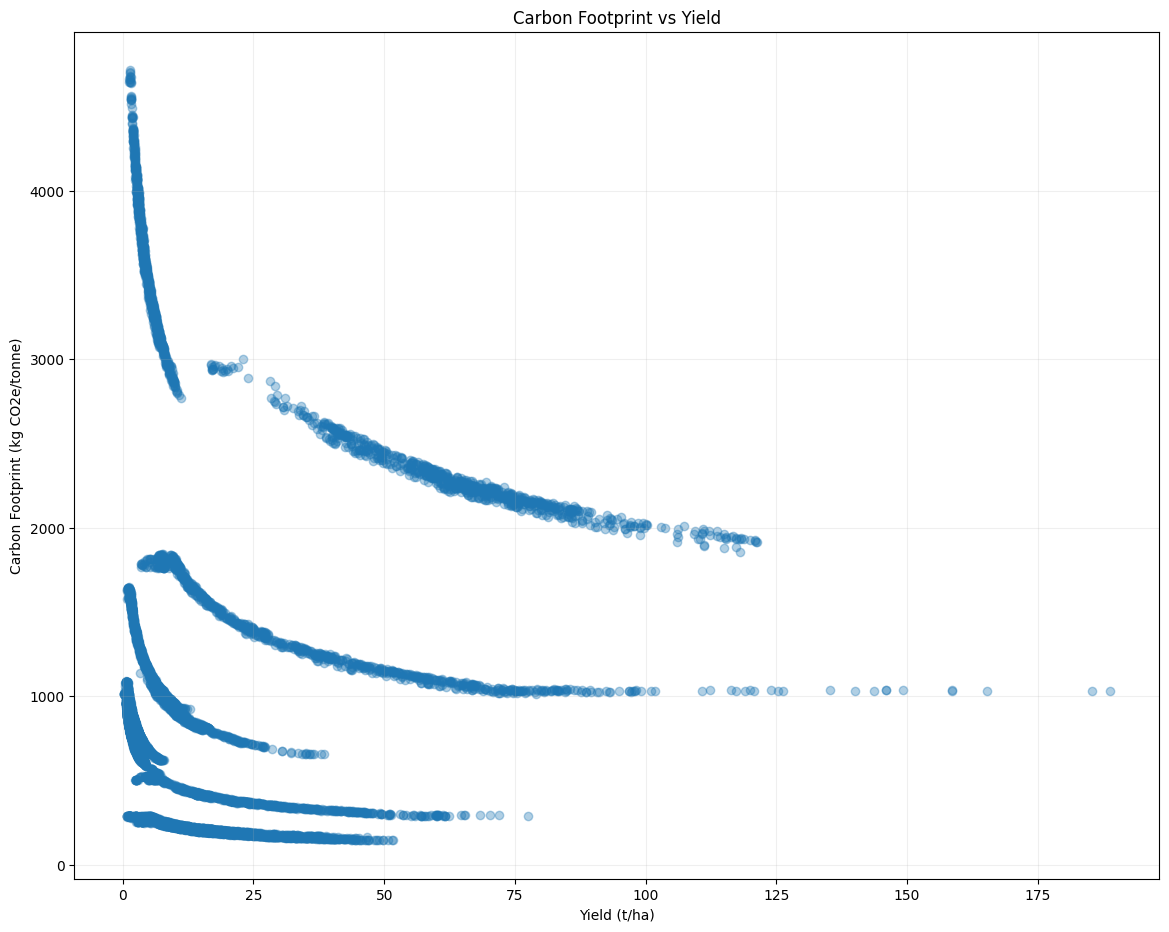

In [28]:
# ============================================
# CELL 24 — TARGET VS YIELD
# ============================================

plt.figure(figsize=(14, 11))

plt.scatter(
    model_df["Yield_t_per_ha"],
    model_df["Carbon_Footprint_kgCO2e_per_tonne"],
    alpha=0.35
)

plt.xlabel("Yield (t/ha)")
plt.ylabel("Carbon Footprint (kg CO2e/tonne)")
plt.title("Carbon Footprint vs Yield")

plt.grid(alpha=0.2)
plt.show()

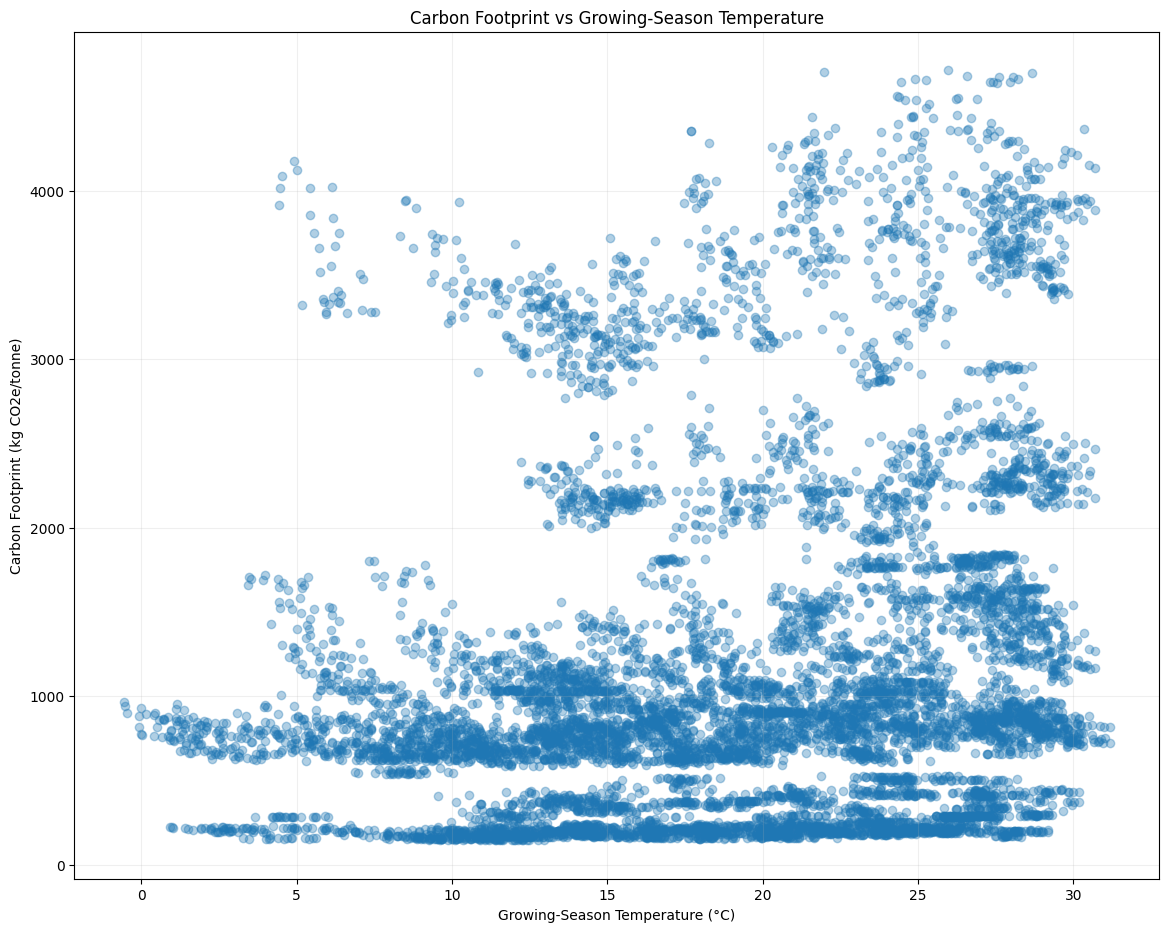

In [29]:
# ============================================
# CELL 25 — TARGET VS GROWING-SEASON TEMPERATURE
# ============================================

plt.figure(figsize=(14, 11))

plt.scatter(
    model_df["Growing_Season_Temperature_C"],
    model_df["Carbon_Footprint_kgCO2e_per_tonne"],
    alpha=0.35
)

plt.xlabel("Growing-Season Temperature (°C)")
plt.ylabel("Carbon Footprint (kg CO2e/tonne)")
plt.title("Carbon Footprint vs Growing-Season Temperature")

plt.grid(alpha=0.2)
plt.show()

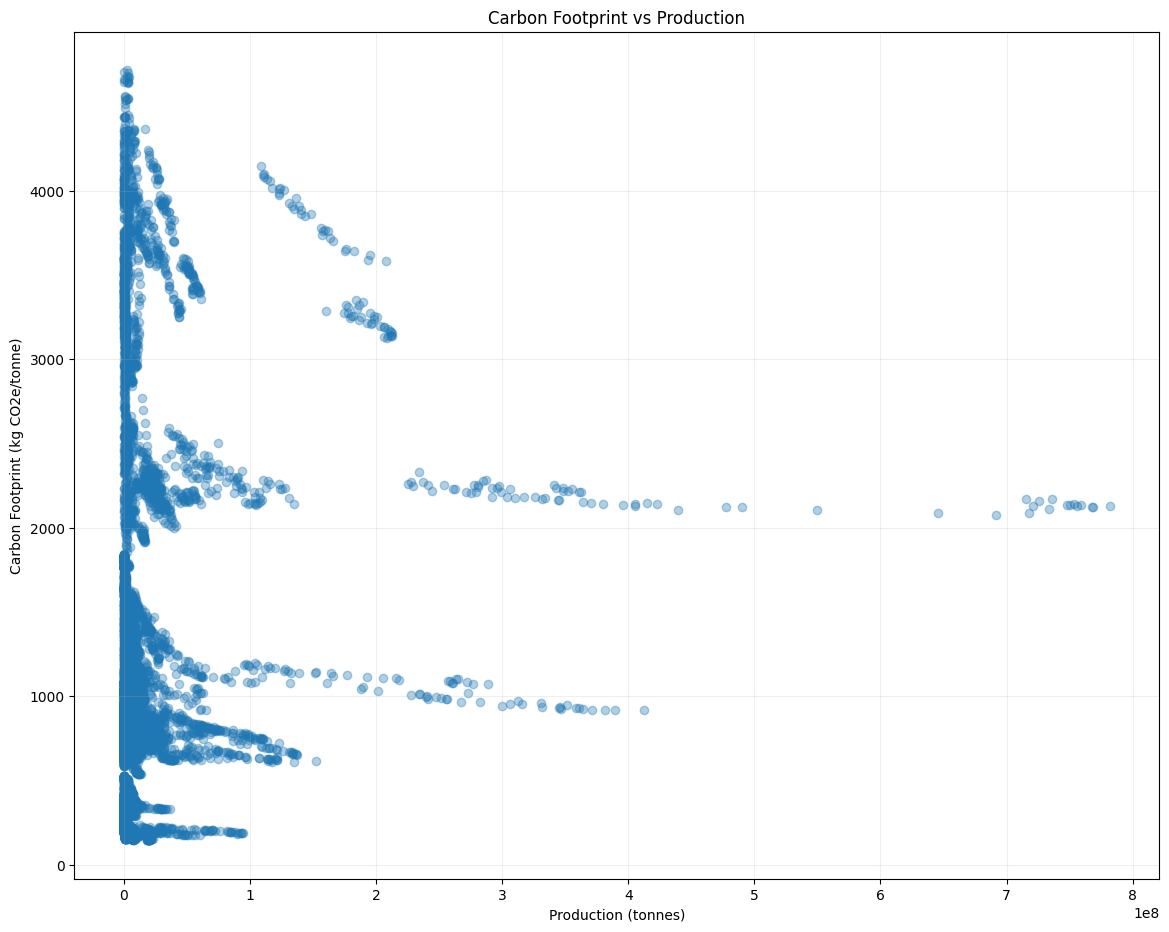

In [30]:
# ============================================
# CELL 26 — TARGET VS PRODUCTION
# ============================================

plt.figure(figsize=(14, 11))

plt.scatter(
    model_df["Production_tonnes"],
    model_df["Carbon_Footprint_kgCO2e_per_tonne"],
    alpha=0.35
)

plt.xlabel("Production (tonnes)")
plt.ylabel("Carbon Footprint (kg CO2e/tonne)")
plt.title("Carbon Footprint vs Production")

plt.grid(alpha=0.2)
plt.show()

In [31]:
# ============================================
# CELL 27 — CROP-ONLY TARGET VARIATION
# ============================================

crop_stats = (
    model_df
    .groupby("Crop")[target]
    .agg(["count", "mean", "std", "min", "max"])
    .sort_values("mean", ascending=False)
)

display(crop_stats.round(3))

overall_mean = model_df[target].mean()

between_crop_variance = (
    model_df.groupby("Crop")[target]
    .mean()
    .var()
)

within_crop_variance = (
    model_df.groupby("Crop")[target]
    .var()
    .mean()
)

print("Overall target mean:", round(overall_mean, 3))
print("Between-crop variance:", round(between_crop_variance, 3))
print("Mean within-crop variance:", round(within_crop_variance, 3))

,count,mean,std,min,max
Crop,,,,,
Rice,965,3586.719,420.030,2768.031,4715.415
Sugar cane,806,2289.902,214.992,1859.472,3001.969
Tomatoes,911,1391.589,282.947,1015.704,1843.749
Maize,1013,1239.032,209.318,917.975,1646.272
Cassava,476,858.472,88.027,656.956,1140.411
Wheat,877,826.254,109.170,620.477,1089.624
Soybeans,998,772.169,101.845,585.437,1038.520
Barley,809,723.229,97.472,540.500,963.806
Bananas,812,394.850,63.544,289.503,530.167


Overall target mean: 1158.324
Between-crop variance: 1015832.673
Mean within-crop variance: 35659.443


In [32]:
# ============================================
# CELL 28 — CHECK YEAR DISTRIBUTION
# ============================================

print("Minimum year:", model_df["Year"].min())
print("Maximum year:", model_df["Year"].max())

print("\nObservations by year:")
display(
    model_df["Year"]
    .value_counts()
    .sort_index()
)

Minimum year: 1990
Maximum year: 2023

Observations by year:


,count
Year,
1990,256
1991,256
1992,270
1993,279
1994,279
1995,279
1996,280
1997,280
1998,280


In [33]:
# ============================================
# CELL 29 — CHRONOLOGICAL TRAIN / VALIDATION / TEST SPLIT
# ============================================

TRAIN_END = 2016
VALIDATION_START = 2017
VALIDATION_END = 2020
TEST_START = 2021
TEST_END = 2023

train_df = model_df[
    model_df["Year"] <= TRAIN_END
].copy()

validation_df = model_df[
    (model_df["Year"] >= VALIDATION_START) &
    (model_df["Year"] <= VALIDATION_END)
].copy()

test_df = model_df[
    (model_df["Year"] >= TEST_START) &
    (model_df["Year"] <= TEST_END)
].copy()

print("="*70)
print("CHRONOLOGICAL SPLIT")
print("="*70)

print(f"Training:   {train_df['Year'].min()}–{train_df['Year'].max()}")
print(f"Validation: {validation_df['Year'].min()}–{validation_df['Year'].max()}")
print(f"Test:       {test_df['Year'].min()}–{test_df['Year'].max()}")

print("\nRows:")
print("Training:", len(train_df))
print("Validation:", len(validation_df))
print("Test:", len(test_df))
print("Total:", len(train_df) + len(validation_df) + len(test_df))

CHRONOLOGICAL SPLIT
Training:   1990–2016
Validation: 2017–2020
Test:       2021–2023

Rows:
Training: 7534
Validation: 1133
Test: 849
Total: 9516


In [34]:
# ============================================
# CELL 30 — BASELINE MODEL RESULTS
# ============================================

from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np
import pandas as pd

TARGET = "Carbon_Footprint_kgCO2e_per_tonne"


# ------------------------------------------------
# Evaluation function
# ------------------------------------------------

def calculate_metrics(y_true, y_pred):

    mae = mean_absolute_error(y_true, y_pred)
    rmse = np.sqrt(mean_squared_error(y_true, y_pred))
    r2 = r2_score(y_true, y_pred)

    return {
        "MAE": mae,
        "RMSE": rmse,
        "R2": r2
    }


# ------------------------------------------------
# Actual target values
# ------------------------------------------------

y_train = train_df[TARGET]
y_validation = validation_df[TARGET]
y_test = test_df[TARGET]


# =================================================
# BASELINE 1 — OVERALL TRAINING MEAN
# =================================================

overall_mean = y_train.mean()

pred_overall = np.full(
    len(test_df),
    overall_mean
)

overall_metrics = calculate_metrics(
    y_test,
    pred_overall
)


# =================================================
# BASELINE 2 — CROP-SPECIFIC TRAINING MEAN
# =================================================

crop_means = (
    train_df
    .groupby("Crop")[TARGET]
    .mean()
)

# Map each test crop to its TRAINING-period mean
pred_crop = test_df["Crop"].map(crop_means)

# Check that every test crop has a training mean
print("Missing crop baseline predictions:",
      pred_crop.isna().sum())

crop_metrics = calculate_metrics(
    y_test,
    pred_crop
)


# =================================================
# RESULTS TABLE
# =================================================

baseline_results = pd.DataFrame(
    [
        {
            "Model": "Overall Mean Baseline",
            **overall_metrics
        },
        {
            "Model": "Crop Mean Baseline",
            **crop_metrics
        }
    ]
)

print("="*70)
print("BASELINE PERFORMANCE — TEST SET (2021–2023)")
print("="*70)

display(
    baseline_results.round(4)
)

Missing crop baseline predictions: 0
BASELINE PERFORMANCE — TEST SET (2021–2023)


,Model,MAE,RMSE,R2
0,Overall Mean Baseline,760.7947,980.6459,-0.0048
1,Crop Mean Baseline,129.9528,191.4705,0.9617


In [35]:
# ============================================
# CELL 31 — BASELINE PERFORMANCE ON VALIDATION
# ============================================

# Overall mean baseline
pred_val_overall = np.full(
    len(validation_df),
    overall_mean
)

val_overall_metrics = calculate_metrics(
    y_validation,
    pred_val_overall
)


# Crop mean baseline
pred_val_crop = validation_df["Crop"].map(crop_means)

print("Missing crop baseline predictions:",
      pred_val_crop.isna().sum())

val_crop_metrics = calculate_metrics(
    y_validation,
    pred_val_crop
)


validation_baseline_results = pd.DataFrame(
    [
        {
            "Model": "Overall Mean Baseline",
            **val_overall_metrics
        },
        {
            "Model": "Crop Mean Baseline",
            **val_crop_metrics
        }
    ]
)

print("="*70)
print("BASELINE PERFORMANCE — VALIDATION SET (2017–2020)")
print("="*70)

display(
    validation_baseline_results.round(4)
)

Missing crop baseline predictions: 0
BASELINE PERFORMANCE — VALIDATION SET (2017–2020)


,Model,MAE,RMSE,R2
0,Overall Mean Baseline,759.6422,981.7266,-0.0039
1,Crop Mean Baseline,130.1238,192.0208,0.9616


In [36]:
# ============================================
# CELL 32 — SAVE BASELINE TEST PREDICTIONS
# ============================================

baseline_predictions = test_df[
    [
        "Country",
        "Country_Code",
        "Crop",
        "Year",
        TARGET
    ]
].copy()

baseline_predictions["Overall_Mean_Prediction"] = pred_overall
baseline_predictions["Crop_Mean_Prediction"] = pred_crop

baseline_predictions.to_csv(
    "baseline_test_predictions.csv",
    index=False
)

baseline_results.to_csv(
    "baseline_test_results.csv",
    index=False
)

validation_baseline_results.to_csv(
    "baseline_validation_results.csv",
    index=False
)

print("Baseline result files saved successfully.")

Baseline result files saved successfully.


In [37]:
# ============================================
# CELL 33 — DEFINE MODEL FEATURES
# ============================================

TARGET = "Carbon_Footprint_kgCO2e_per_tonne"

categorical_features = [
    "Country",
    "Crop"
]

numeric_features = [
    "Year",
    "Area_Harvested_ha_Derived",
    "Production_tonnes",
    "Yield_t_per_ha",
    "National_N_Fertilizer_Use_tonnes",
    "National_P2O5_Fertilizer_Use_tonnes",
    "National_K2O_Fertilizer_Use_tonnes",
    "Growing_Season_Temperature_C",
    "Growing_Season_Rainfall_mm",
    "Growing_Season_Humidity_pct",
    "Growing_Season_Solar_Radiation",
    "Temperature_Anomaly",
    "Rainfall_Anomaly"
]

all_features = categorical_features + numeric_features

print("Categorical features:")
print(categorical_features)

print("\nNumeric features:")
print(numeric_features)

print("\nTotal features:", len(all_features))

Categorical features:
['Country', 'Crop']

Numeric features:
['Year', 'Area_Harvested_ha_Derived', 'Production_tonnes', 'Yield_t_per_ha', 'National_N_Fertilizer_Use_tonnes', 'National_P2O5_Fertilizer_Use_tonnes', 'National_K2O_Fertilizer_Use_tonnes', 'Growing_Season_Temperature_C', 'Growing_Season_Rainfall_mm', 'Growing_Season_Humidity_pct', 'Growing_Season_Solar_Radiation', 'Temperature_Anomaly', 'Rainfall_Anomaly']

Total features: 15


In [38]:
# ============================================
# CELL 34 — CHRONOLOGICAL SPLIT FOR FULL MODEL
# ============================================

full_train_df = model_df_k2o[
    model_df_k2o["Year"] <= 2016
].copy()

full_validation_df = model_df_k2o[
    (model_df_k2o["Year"] >= 2017) &
    (model_df_k2o["Year"] <= 2020)
].copy()

full_test_df = model_df_k2o[
    (model_df_k2o["Year"] >= 2021) &
    (model_df_k2o["Year"] <= 2023)
].copy()

print("="*70)
print("FULL-FEATURE MODEL COHORT")
print("="*70)

print("Training:", len(full_train_df))
print("Validation:", len(full_validation_df))
print("Test:", len(full_test_df))
print("Total:", len(full_train_df) +
      len(full_validation_df) +
      len(full_test_df))

print("\nYear ranges:")
print(
    full_train_df["Year"].min(),
    "–",
    full_train_df["Year"].max()
)

print(
    full_validation_df["Year"].min(),
    "–",
    full_validation_df["Year"].max()
)

print(
    full_test_df["Year"].min(),
    "–",
    full_test_df["Year"].max()
)

FULL-FEATURE MODEL COHORT
Training: 7376
Validation: 1133
Test: 849
Total: 9358

Year ranges:
1990 – 2016
2017 – 2020
2021 – 2023


In [39]:
# ============================================
# CELL 35 — PREPROCESSING PIPELINE
# ============================================

from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer

numeric_transformer = Pipeline(
    steps=[
        (
            "imputer",
            SimpleImputer(strategy="median")
        ),
        (
            "scaler",
            StandardScaler()
        )
    ]
)

categorical_transformer = Pipeline(
    steps=[
        (
            "imputer",
            SimpleImputer(strategy="most_frequent")
        ),
        (
            "onehot",
            OneHotEncoder(
                handle_unknown="ignore",
                sparse_output=False
            )
        )
    ]
)

preprocessor = ColumnTransformer(
    transformers=[
        (
            "num",
            numeric_transformer,
            numeric_features
        ),
        (
            "cat",
            categorical_transformer,
            categorical_features
        )
    ]
)

print("Preprocessing pipeline created successfully.")

Preprocessing pipeline created successfully.


In [40]:
# ============================================
# CELL 36 — RIDGE REGRESSION
# ============================================

from sklearn.linear_model import Ridge

X_train = full_train_df[all_features]
y_train_full = full_train_df[TARGET]

X_validation = full_validation_df[all_features]
y_validation_full = full_validation_df[TARGET]

X_test = full_test_df[all_features]
y_test_full = full_test_df[TARGET]


ridge_model = Pipeline(
    steps=[
        (
            "preprocessor",
            preprocessor
        ),
        (
            "model",
            Ridge(alpha=10.0)
        )
    ]
)

ridge_model.fit(
    X_train,
    y_train_full
)

# Predictions
ridge_val_pred = ridge_model.predict(X_validation)
ridge_test_pred = ridge_model.predict(X_test)


# Metrics
ridge_val_metrics = calculate_metrics(
    y_validation_full,
    ridge_val_pred
)

ridge_test_metrics = calculate_metrics(
    y_test_full,
    ridge_test_pred
)


print("="*70)
print("RIDGE REGRESSION RESULTS")
print("="*70)

print("\nValidation (2017–2020):")
print(
    pd.Series(ridge_val_metrics).round(4)
)

print("\nTest (2021–2023):")
print(
    pd.Series(ridge_test_metrics).round(4)
)

RIDGE REGRESSION RESULTS

Validation (2017–2020):
MAE      98.0828
RMSE    134.7739
R2        0.9811
dtype: float64

Test (2021–2023):
MAE      98.1273
RMSE    135.4838
R2        0.9808
dtype: float64


In [41]:
# ============================================
# CELL 37 — RIDGE VS BASELINES
# ============================================

ridge_results = pd.DataFrame(
    [
        {
            "Model": "Overall Mean Baseline",
            **overall_metrics
        },
        {
            "Model": "Crop Mean Baseline",
            **crop_metrics
        },
        {
            "Model": "Ridge Regression",
            **ridge_test_metrics
        }
    ]
)

print("="*70)
print("TEST SET COMPARISON")
print("="*70)

display(
    ridge_results.round(4)
)

TEST SET COMPARISON


,Model,MAE,RMSE,R2
0,Overall Mean Baseline,760.7947,980.6459,-0.0048
1,Crop Mean Baseline,129.9528,191.4705,0.9617
2,Ridge Regression,98.1273,135.4838,0.9808


In [42]:
# ============================================
# CELL 38 — RANDOM FOREST REGRESSION
# ============================================

from sklearn.ensemble import RandomForestRegressor

rf_model = Pipeline(
    steps=[
        (
            "preprocessor",
            preprocessor
        ),
        (
            "model",
            RandomForestRegressor(
                n_estimators=500,
                max_depth=None,
                min_samples_split=2,
                min_samples_leaf=1,
                max_features="sqrt",
                random_state=42,
                n_jobs=-1
            )
        )
    ]
)

# Train
rf_model.fit(
    X_train,
    y_train_full
)

# Predictions
rf_val_pred = rf_model.predict(X_validation)
rf_test_pred = rf_model.predict(X_test)

# Metrics
rf_val_metrics = calculate_metrics(
    y_validation_full,
    rf_val_pred
)

rf_test_metrics = calculate_metrics(
    y_test_full,
    rf_test_pred
)

print("="*70)
print("RANDOM FOREST RESULTS")
print("="*70)

print("\nValidation (2017–2020):")
print(pd.Series(rf_val_metrics).round(4))

print("\nTest (2021–2023):")
print(pd.Series(rf_test_metrics).round(4))

RANDOM FOREST RESULTS

Validation (2017–2020):
MAE     42.9577
RMSE    64.5645
R2       0.9957
dtype: float64

Test (2021–2023):
MAE     54.2084
RMSE    78.2804
R2       0.9936
dtype: float64


In [43]:
# ============================================
# CELL 39 — RIDGE VS RANDOM FOREST
# ============================================

rf_results = pd.DataFrame(
    [
        {
            "Model": "Overall Mean Baseline",
            **overall_metrics
        },
        {
            "Model": "Crop Mean Baseline",
            **crop_metrics
        },
        {
            "Model": "Ridge Regression",
            **ridge_test_metrics
        },
        {
            "Model": "Random Forest",
            **rf_test_metrics
        }
    ]
)

print("="*70)
print("TEST SET MODEL COMPARISON")
print("="*70)

display(
    rf_results.round(4)
)

TEST SET MODEL COMPARISON


,Model,MAE,RMSE,R2
0,Overall Mean Baseline,760.7947,980.6459,-0.0048
1,Crop Mean Baseline,129.9528,191.4705,0.9617
2,Ridge Regression,98.1273,135.4838,0.9808
3,Random Forest,54.2084,78.2804,0.9936


In [44]:
# ============================================
# CELL 40 — GRADIENT BOOSTING REGRESSION
# ============================================

from sklearn.ensemble import GradientBoostingRegressor

gb_model = Pipeline(
    steps=[
        (
            "preprocessor",
            preprocessor
        ),
        (
            "model",
            GradientBoostingRegressor(
                n_estimators=300,
                learning_rate=0.05,
                max_depth=3,
                min_samples_split=2,
                min_samples_leaf=1,
                loss="squared_error",
                random_state=42
            )
        )
    ]
)

# Train
gb_model.fit(
    X_train,
    y_train_full
)

# Predictions
gb_val_pred = gb_model.predict(X_validation)
gb_test_pred = gb_model.predict(X_test)

# Metrics
gb_val_metrics = calculate_metrics(
    y_validation_full,
    gb_val_pred
)

gb_test_metrics = calculate_metrics(
    y_test_full,
    gb_test_pred
)

print("="*70)
print("GRADIENT BOOSTING RESULTS")
print("="*70)

print("\nValidation (2017–2020):")
print(pd.Series(gb_val_metrics).round(4))

print("\nTest (2021–2023):")
print(pd.Series(gb_test_metrics).round(4))

GRADIENT BOOSTING RESULTS

Validation (2017–2020):
MAE     23.2592
RMSE    34.5371
R2       0.9988
dtype: float64

Test (2021–2023):
MAE     24.0474
RMSE    36.7708
R2       0.9986
dtype: float64


In [45]:
# ============================================
# CELL 41 — CURRENT MODEL COMPARISON
# ============================================

current_results = pd.DataFrame(
    [
        {
            "Model": "Overall Mean Baseline",
            **overall_metrics
        },
        {
            "Model": "Crop Mean Baseline",
            **crop_metrics
        },
        {
            "Model": "Ridge Regression",
            **ridge_test_metrics
        },
        {
            "Model": "Random Forest",
            **rf_test_metrics
        },
        {
            "Model": "Gradient Boosting",
            **gb_test_metrics
        }
    ]
)

print("="*70)
print("CURRENT TEST SET MODEL COMPARISON")
print("="*70)

display(
    current_results.sort_values(
        "RMSE"
    ).round(4)
)

CURRENT TEST SET MODEL COMPARISON


,Model,MAE,RMSE,R2
4,Gradient Boosting,24.0474,36.7708,0.9986
3,Random Forest,54.2084,78.2804,0.9936
2,Ridge Regression,98.1273,135.4838,0.9808
1,Crop Mean Baseline,129.9528,191.4705,0.9617
0,Overall Mean Baseline,760.7947,980.6459,-0.0048


In [46]:
# ============================================
# CELL 42 — XGBOOST REGRESSION
# ============================================

from xgboost import XGBRegressor

xgb_model = Pipeline(
    steps=[
        (
            "preprocessor",
            preprocessor
        ),
        (
            "model",
            XGBRegressor(
                n_estimators=500,
                learning_rate=0.05,
                max_depth=6,
                min_child_weight=3,
                subsample=0.8,
                colsample_bytree=0.8,
                reg_alpha=0.0,
                reg_lambda=1.0,
                objective="reg:squarederror",
                random_state=42,
                n_jobs=-1
            )
        )
    ]
)

# Train
xgb_model.fit(
    X_train,
    y_train_full
)

# Predictions
xgb_val_pred = xgb_model.predict(X_validation)
xgb_test_pred = xgb_model.predict(X_test)

# Metrics
xgb_val_metrics = calculate_metrics(
    y_validation_full,
    xgb_val_pred
)

xgb_test_metrics = calculate_metrics(
    y_test_full,
    xgb_test_pred
)

print("="*70)
print("XGBOOST RESULTS")
print("="*70)

print("\nValidation (2017–2020):")
print(pd.Series(xgb_val_metrics).round(4))

print("\nTest (2021–2023):")
print(pd.Series(xgb_test_metrics).round(4))

XGBOOST RESULTS

Validation (2017–2020):
MAE     11.5293
RMSE    21.6397
R2       0.9995
dtype: float64

Test (2021–2023):
MAE     12.7590
RMSE    22.5990
R2       0.9995
dtype: float64


In [47]:
# ============================================
# CELL 43 — XGBOOST MODEL COMPARISON
# ============================================

model_results = pd.DataFrame(
    [
        {
            "Model": "Overall Mean Baseline",
            **overall_metrics
        },
        {
            "Model": "Crop Mean Baseline",
            **crop_metrics
        },
        {
            "Model": "Ridge Regression",
            **ridge_test_metrics
        },
        {
            "Model": "Random Forest",
            **rf_test_metrics
        },
        {
            "Model": "Gradient Boosting",
            **gb_test_metrics
        },
        {
            "Model": "XGBoost",
            **xgb_test_metrics
        }
    ]
)

print("="*70)
print("MODEL COMPARISON — TEST SET (2021–2023)")
print("="*70)

display(
    model_results
    .sort_values("RMSE")
    .reset_index(drop=True)
    .round(4)
)

MODEL COMPARISON — TEST SET (2021–2023)


,Model,MAE,RMSE,R2
0,XGBoost,12.7590,22.5990,0.9995
1,Gradient Boosting,24.0474,36.7708,0.9986
2,Random Forest,54.2084,78.2804,0.9936
3,Ridge Regression,98.1273,135.4838,0.9808
4,Crop Mean Baseline,129.9528,191.4705,0.9617
5,Overall Mean Baseline,760.7947,980.6459,-0.0048


In [48]:
# ============================================
# CELL 44 — LIGHTGBM REGRESSION
# ============================================

from lightgbm import LGBMRegressor

lgbm_model = Pipeline(
    steps=[
        (
            "preprocessor",
            preprocessor
        ),
        (
            "model",
            LGBMRegressor(
                n_estimators=500,
                learning_rate=0.05,
                max_depth=-1,
                num_leaves=31,
                min_child_samples=20,
                subsample=0.8,
                colsample_bytree=0.8,
                reg_alpha=0.0,
                reg_lambda=1.0,
                random_state=42,
                n_jobs=-1,
                verbosity=-1
            )
        )
    ]
)

# Train
lgbm_model.fit(
    X_train,
    y_train_full
)

# Predictions
lgbm_val_pred = lgbm_model.predict(X_validation)
lgbm_test_pred = lgbm_model.predict(X_test)

# Metrics
lgbm_val_metrics = calculate_metrics(
    y_validation_full,
    lgbm_val_pred
)

lgbm_test_metrics = calculate_metrics(
    y_test_full,
    lgbm_test_pred
)

print("="*70)
print("LIGHTGBM RESULTS")
print("="*70)

print("\nValidation (2017–2020):")
print(pd.Series(lgbm_val_metrics).round(4))

print("\nTest (2021–2023):")
print(pd.Series(lgbm_test_metrics).round(4))

LIGHTGBM RESULTS

Validation (2017–2020):
MAE     17.2571
RMSE    28.7160
R2       0.9991
dtype: float64

Test (2021–2023):
MAE     18.0147
RMSE    30.0372
R2       0.9991
dtype: float64


In [49]:
# ============================================
# CELL 45 — CATBOOST REGRESSION
# ============================================

from catboost import CatBoostRegressor

# For CatBoost, we will NOT use the OneHotEncoder pipeline.
# CatBoost handles categorical variables directly.

X_train_cat = full_train_df[all_features].copy()
X_validation_cat = full_validation_df[all_features].copy()
X_test_cat = full_test_df[all_features].copy()

# Convert categorical columns to strings
for col in categorical_features:
    X_train_cat[col] = X_train_cat[col].astype(str)
    X_validation_cat[col] = X_validation_cat[col].astype(str)
    X_test_cat[col] = X_test_cat[col].astype(str)

cat_feature_indices = [
    X_train_cat.columns.get_loc(col)
    for col in categorical_features
]

cat_model = CatBoostRegressor(
    iterations=500,
    learning_rate=0.05,
    depth=7,
    loss_function="RMSE",
    random_seed=42,
    verbose=False,
    allow_writing_files=False
)

cat_model.fit(
    X_train_cat,
    y_train_full,
    cat_features=cat_feature_indices
)

# Predictions
cat_val_pred = cat_model.predict(X_validation_cat)
cat_test_pred = cat_model.predict(X_test_cat)

# Metrics
cat_val_metrics = calculate_metrics(
    y_validation_full,
    cat_val_pred
)

cat_test_metrics = calculate_metrics(
    y_test_full,
    cat_test_pred
)

print("="*70)
print("CATBOOST RESULTS")
print("="*70)

print("\nValidation (2017–2020):")
print(pd.Series(cat_val_metrics).round(4))

print("\nTest (2021–2023):")
print(pd.Series(cat_test_metrics).round(4))

CATBOOST RESULTS

Validation (2017–2020):
MAE     19.6678
RMSE    32.7361
R2       0.9989
dtype: float64

Test (2021–2023):
MAE     20.3625
RMSE    33.6723
R2       0.9988
dtype: float64


In [50]:
# ============================================
# CELL 46 — COMPLETE MODEL COMPARISON
# ============================================

complete_model_results = pd.DataFrame(
    [
        {
            "Model": "Overall Mean Baseline",
            **overall_metrics
        },
        {
            "Model": "Crop Mean Baseline",
            **crop_metrics
        },
        {
            "Model": "Ridge Regression",
            **ridge_test_metrics
        },
        {
            "Model": "Random Forest",
            **rf_test_metrics
        },
        {
            "Model": "Gradient Boosting",
            **gb_test_metrics
        },
        {
            "Model": "XGBoost",
            **xgb_test_metrics
        },
        {
            "Model": "LightGBM",
            **lgbm_test_metrics
        },
        {
            "Model": "CatBoost",
            **cat_test_metrics
        }
    ]
)

complete_model_results = (
    complete_model_results
    .sort_values("RMSE")
    .reset_index(drop=True)
)

print("="*70)
print("COMPLETE MODEL COMPARISON — TEST SET")
print("="*70)

display(
    complete_model_results.round(4)
)

# Save
complete_model_results.to_csv(
    "complete_model_comparison_test.csv",
    index=False
)

COMPLETE MODEL COMPARISON — TEST SET


,Model,MAE,RMSE,R2
0,XGBoost,12.7590,22.5990,0.9995
1,LightGBM,18.0147,30.0372,0.9991
2,CatBoost,20.3625,33.6723,0.9988
3,Gradient Boosting,24.0474,36.7708,0.9986
4,Random Forest,54.2084,78.2804,0.9936
5,Ridge Regression,98.1273,135.4838,0.9808
6,Crop Mean Baseline,129.9528,191.4705,0.9617
7,Overall Mean Baseline,760.7947,980.6459,-0.0048


In [51]:
# ============================================================
# CELL 47 — ABLATION FEATURE SETS
# ============================================================

# M1: Production variables only
M1_features = [
    "Area_Harvested_ha_Derived",
    "Production_tonnes",
    "Yield_t_per_ha"
]

# M2: Production + Fertilizer
M2_features = M1_features + [
    "National_N_Fertilizer_Use_tonnes",
    "National_P2O5_Fertilizer_Use_tonnes",
    "National_K2O_Fertilizer_Use_tonnes"
]

# M3: Production + Fertilizer + Climate
M3_features = M2_features + [
    "Growing_Season_Temperature_C",
    "Growing_Season_Rainfall_mm",
    "Growing_Season_Humidity_pct",
    "Growing_Season_Solar_Radiation",
    "Temperature_Anomaly",
    "Rainfall_Anomaly"
]

# M4: Full Context Model
# Adds Country, Crop and Year to M3
M4_features = M3_features + [
    "Country",
    "Crop",
    "Year"
]

print("M1 features:", len(M1_features))
print(M1_features)

print("\nM2 features:", len(M2_features))
print(M2_features)

print("\nM3 features:", len(M3_features))
print(M3_features)

print("\nM4 features:", len(M4_features))
print(M4_features)

M1 features: 3
['Area_Harvested_ha_Derived', 'Production_tonnes', 'Yield_t_per_ha']

M2 features: 6
['Area_Harvested_ha_Derived', 'Production_tonnes', 'Yield_t_per_ha', 'National_N_Fertilizer_Use_tonnes', 'National_P2O5_Fertilizer_Use_tonnes', 'National_K2O_Fertilizer_Use_tonnes']

M3 features: 12
['Area_Harvested_ha_Derived', 'Production_tonnes', 'Yield_t_per_ha', 'National_N_Fertilizer_Use_tonnes', 'National_P2O5_Fertilizer_Use_tonnes', 'National_K2O_Fertilizer_Use_tonnes', 'Growing_Season_Temperature_C', 'Growing_Season_Rainfall_mm', 'Growing_Season_Humidity_pct', 'Growing_Season_Solar_Radiation', 'Temperature_Anomaly', 'Rainfall_Anomaly']

M4 features: 15
['Area_Harvested_ha_Derived', 'Production_tonnes', 'Yield_t_per_ha', 'National_N_Fertilizer_Use_tonnes', 'National_P2O5_Fertilizer_Use_tonnes', 'National_K2O_Fertilizer_Use_tonnes', 'Growing_Season_Temperature_C', 'Growing_Season_Rainfall_mm', 'Growing_Season_Humidity_pct', 'Growing_Season_Solar_Radiation', 'Temperature_Anomaly', 

In [52]:
# ============================================================
# CELL 48 — COMMON ABLATION DATA SPLIT
# ============================================================

ablation_df = model_df_k2o.copy()

# Target
TARGET = "Carbon_Footprint_kgCO2e_per_tonne"

# Same chronological split for ALL ablation models
ablation_train_df = ablation_df[
    ablation_df["Year"] <= 2016
].copy()

ablation_validation_df = ablation_df[
    (ablation_df["Year"] >= 2017) &
    (ablation_df["Year"] <= 2020)
].copy()

ablation_test_df = ablation_df[
    (ablation_df["Year"] >= 2021) &
    (ablation_df["Year"] <= 2023)
].copy()

print("=" * 70)
print("ABLATION DATA SPLIT")
print("=" * 70)

print("Total:", len(ablation_df))
print("Training:", len(ablation_train_df))
print("Validation:", len(ablation_validation_df))
print("Test:", len(ablation_test_df))

print("\nTraining years:",
      ablation_train_df["Year"].min(),
      "to",
      ablation_train_df["Year"].max())

print("Validation years:",
      ablation_validation_df["Year"].min(),
      "to",
      ablation_validation_df["Year"].max())

print("Test years:",
      ablation_test_df["Year"].min(),
      "to",
      ablation_test_df["Year"].max())

ABLATION DATA SPLIT
Total: 9358
Training: 7376
Validation: 1133
Test: 849

Training years: 1990 to 2016
Validation years: 2017 to 2020
Test years: 2021 to 2023


In [53]:
# ============================================================
# CELL 49 — ABLATION PREPROCESSOR
# ============================================================

def create_ablation_preprocessor(feature_list):

    categorical_cols = [
        col for col in ["Country", "Crop"]
        if col in feature_list
    ]

    numeric_cols = [
        col for col in feature_list
        if col not in categorical_cols
    ]

    numeric_transformer = Pipeline(
        steps=[
            ("imputer", SimpleImputer(strategy="median")),
            ("scaler", StandardScaler())
        ]
    )

    categorical_transformer = Pipeline(
        steps=[
            ("imputer", SimpleImputer(strategy="most_frequent")),
            ("onehot", OneHotEncoder(
                handle_unknown="ignore",
                sparse_output=False
            ))
        ]
    )

    transformers = [
        ("num", numeric_transformer, numeric_cols)
    ]

    if len(categorical_cols) > 0:
        transformers.append(
            ("cat", categorical_transformer, categorical_cols)
        )

    preprocessor = ColumnTransformer(
        transformers=transformers,
        remainder="drop"
    )

    return preprocessor, numeric_cols, categorical_cols

In [54]:
# ============================================================
# CELL 50 — ABLATION XGBOOST FUNCTION
# ============================================================

def run_ablation_xgboost(
    model_name,
    feature_list,
    train_df,
    validation_df,
    test_df
):

    X_train = train_df[feature_list].copy()
    y_train = train_df[TARGET].copy()

    X_val = validation_df[feature_list].copy()
    y_val = validation_df[TARGET].copy()

    X_test = test_df[feature_list].copy()
    y_test = test_df[TARGET].copy()

    # Create preprocessing pipeline
    preprocessor, numeric_cols, categorical_cols = \
        create_ablation_preprocessor(feature_list)

    # Same XGBoost settings for every ablation model
    model = Pipeline(
        steps=[
            ("preprocessor", preprocessor),
            ("model", XGBRegressor(
                n_estimators=500,
                learning_rate=0.05,
                max_depth=6,
                min_child_weight=3,
                subsample=0.8,
                colsample_bytree=0.8,
                reg_alpha=0.0,
                reg_lambda=1.0,
                objective="reg:squarederror",
                random_state=42,
                n_jobs=-1
            ))
        ]
    )

    # Train
    model.fit(X_train, y_train)

    # Predictions
    val_pred = model.predict(X_val)
    test_pred = model.predict(X_test)

    # Metrics
    val_metrics = calculate_metrics(y_val, val_pred)
    test_metrics = calculate_metrics(y_test, test_pred)

    return {
        "model_name": model_name,
        "feature_list": feature_list,
        "model": model,
        "val_pred": val_pred,
        "test_pred": test_pred,
        "val_metrics": val_metrics,
        "test_metrics": test_metrics
    }

In [55]:
# ============================================================
# CELL 51 — M1
# ============================================================

print("=" * 70)
print("RUNNING M1 — PRODUCTION ONLY")
print("=" * 70)

M1_result = run_ablation_xgboost(
    model_name="M1 Production Only",
    feature_list=M1_features,
    train_df=ablation_train_df,
    validation_df=ablation_validation_df,
    test_df=ablation_test_df
)

print("\nValidation:")
print(M1_result["val_metrics"])

print("\nTest:")
print(M1_result["test_metrics"])

RUNNING M1 — PRODUCTION ONLY

Validation:
{'MAE': 561.2502497177192, 'RMSE': np.float64(833.548013986276), 'R2': 0.2763027622432608}

Test:
{'MAE': 613.367195247367, 'RMSE': np.float64(911.7251552925205), 'R2': 0.13146832062646108}


In [56]:
# ============================================================
# CELL 52 — M2
# ============================================================

print("=" * 70)
print("RUNNING M2 — PRODUCTION + FERTILIZER")
print("=" * 70)

M2_result = run_ablation_xgboost(
    model_name="M2 Production + Fertilizer",
    feature_list=M2_features,
    train_df=ablation_train_df,
    validation_df=ablation_validation_df,
    test_df=ablation_test_df
)

print("\nValidation:")
print(M2_result["val_metrics"])

print("\nTest:")
print(M2_result["test_metrics"])

RUNNING M2 — PRODUCTION + FERTILIZER

Validation:
{'MAE': 415.70844235220403, 'RMSE': np.float64(657.7394039415714), 'R2': 0.5493873352949177}

Test:
{'MAE': 495.36090662821664, 'RMSE': np.float64(738.9444088572066), 'R2': 0.42946627185110364}


In [57]:
# ============================================================
# CELL 53 — M3
# ============================================================

print("=" * 70)
print("RUNNING M3 — PRODUCTION + FERTILIZER + CLIMATE")
print("=" * 70)

M3_result = run_ablation_xgboost(
    model_name="M3 Production + Fertilizer + Climate",
    feature_list=M3_features,
    train_df=ablation_train_df,
    validation_df=ablation_validation_df,
    test_df=ablation_test_df
)

print("\nValidation:")
print(M3_result["val_metrics"])

print("\nTest:")
print(M3_result["test_metrics"])

RUNNING M3 — PRODUCTION + FERTILIZER + CLIMATE

Validation:
{'MAE': 255.8712877450322, 'RMSE': np.float64(406.9237836538061), 'R2': 0.8275267207187992}

Test:
{'MAE': 313.344059432543, 'RMSE': np.float64(478.81233285192775), 'R2': 0.7604542638711279}


In [58]:
# ============================================================
# CELL 54 — M4 Full Context

print("=" * 70)
print("RUNNING M4 — FULL CONTEXT MODEL")
print("=" * 70)

M4_result = run_ablation_xgboost(
    model_name="M4 Full Context",
    feature_list=M4_features,
    train_df=ablation_train_df,
    validation_df=ablation_validation_df,
    test_df=ablation_test_df
)

print("\nValidation:")
print(M4_result["val_metrics"])

print("\nTest:")
print(M4_result["test_metrics"])

RUNNING M4 — FULL CONTEXT MODEL

Validation:
{'MAE': 11.508820732473588, 'RMSE': np.float64(21.04715316678713), 'R2': 0.9995385948942654}

Test:
{'MAE': 12.273771047423669, 'RMSE': np.float64(21.230030815497837), 'R2': 0.9995290670935516}


In [59]:
# ============================================================
# CELL 55 — ABLATION COMPARISON TABLE
# ============================================================

ablation_results = pd.DataFrame([
    {
        "Model": M1_result["model_name"],
        "Feature Groups": "Production",
        "Validation MAE": M1_result["val_metrics"]["MAE"],
        "Validation RMSE": M1_result["val_metrics"]["RMSE"],
        "Validation R2": M1_result["val_metrics"]["R2"],
        "Test MAE": M1_result["test_metrics"]["MAE"],
        "Test RMSE": M1_result["test_metrics"]["RMSE"],
        "Test R2": M1_result["test_metrics"]["R2"]
    },
    {
        "Model": M2_result["model_name"],
        "Feature Groups": "Production + Fertilizer",
        "Validation MAE": M2_result["val_metrics"]["MAE"],
        "Validation RMSE": M2_result["val_metrics"]["RMSE"],
        "Validation R2": M2_result["val_metrics"]["R2"],
        "Test MAE": M2_result["test_metrics"]["MAE"],
        "Test RMSE": M2_result["test_metrics"]["RMSE"],
        "Test R2": M2_result["test_metrics"]["R2"]
    },
    {
        "Model": M3_result["model_name"],
        "Feature Groups": "Production + Fertilizer + Climate",
        "Validation MAE": M3_result["val_metrics"]["MAE"],
        "Validation RMSE": M3_result["val_metrics"]["RMSE"],
        "Validation R2": M3_result["val_metrics"]["R2"],
        "Test MAE": M3_result["test_metrics"]["MAE"],
        "Test RMSE": M3_result["test_metrics"]["RMSE"],
        "Test R2": M3_result["test_metrics"]["R2"]
    },
    {
        "Model": M4_result["model_name"],
        "Feature Groups": "Production + Fertilizer + Climate + Context",
        "Validation MAE": M4_result["val_metrics"]["MAE"],
        "Validation RMSE": M4_result["val_metrics"]["RMSE"],
        "Validation R2": M4_result["val_metrics"]["R2"],
        "Test MAE": M4_result["test_metrics"]["MAE"],
        "Test RMSE": M4_result["test_metrics"]["RMSE"],
        "Test R2": M4_result["test_metrics"]["R2"]
    }
])

ablation_results = ablation_results.sort_values(
    by="Test RMSE"
).reset_index(drop=True)

print("=" * 100)
print("ABLATION STUDY — COMPLETE RESULTS")
print("=" * 100)

display(ablation_results)

ABLATION STUDY — COMPLETE RESULTS


,Model,Feature Groups,Validation MAE,Validation RMSE,Validation R2,Test MAE,Test RMSE,Test R2
0,M4 Full Context,Production + Fertilizer + Climate + Context,11.508821,21.047153,0.999539,12.273771,21.230031,0.999529
1,M3 Production + Fertilizer + Climate,Production + Fertilizer + Climate,255.871288,406.923784,0.827527,313.344059,478.812333,0.760454
2,M2 Production + Fertilizer,Production + Fertilizer,415.708442,657.739404,0.549387,495.360907,738.944409,0.429466
3,M1 Production Only,Production,561.250250,833.548014,0.276303,613.367195,911.725155,0.131468


In [60]:
# ============================================================
# CELL 56 — ABLATION IMPROVEMENT ANALYSIS
# ============================================================

ablation_improvement = ablation_results.copy()

# Preserve original logical order
order = {
    "M1 Production Only": 1,
    "M2 Production + Fertilizer": 2,
    "M3 Production + Fertilizer + Climate": 3,
    "M4 Full Context": 4
}

ablation_improvement["Order"] = \
    ablation_improvement["Model"].map(order)

ablation_improvement = ablation_improvement.sort_values("Order")

# Improvement relative to previous model
ablation_improvement["MAE Improvement"] = \
    -ablation_improvement["Test MAE"].diff()

ablation_improvement["RMSE Improvement"] = \
    -ablation_improvement["Test RMSE"].diff()

ablation_improvement["R2 Improvement"] = \
    ablation_improvement["Test R2"].diff()

display(
    ablation_improvement[
        [
            "Model",
            "Feature Groups",
            "Test MAE",
            "Test RMSE",
            "Test R2",
            "MAE Improvement",
            "RMSE Improvement",
            "R2 Improvement"
        ]
    ]
)

,Model,Feature Groups,Test MAE,Test RMSE,Test R2,MAE Improvement,RMSE Improvement,R2 Improvement
3,M1 Production Only,Production,613.367195,911.725155,0.131468,NaN,NaN,NaN
2,M2 Production + Fertilizer,Production + Fertilizer,495.360907,738.944409,0.429466,118.006289,172.780746,0.297998
1,M3 Production + Fertilizer + Climate,Production + Fertilizer + Climate,313.344059,478.812333,0.760454,182.016847,260.132076,0.330988
0,M4 Full Context,Production + Fertilizer + Climate + Context,12.273771,21.230031,0.999529,301.070288,457.582302,0.239075


In [61]:
# ============================================================
# CELL 57 — SAVE ABLATION RESULTS
# ============================================================

ablation_results.to_csv(
    "ablation_study_results.csv",
    index=False
)

ablation_improvement.to_csv(
    "ablation_improvement_analysis.csv",
    index=False
)

print("Saved:")
print("1. ablation_study_results.csv")
print("2. ablation_improvement_analysis.csv")

Saved:
1. ablation_study_results.csv
2. ablation_improvement_analysis.csv


In [62]:
# ============================================================
# CELL 58 — TARGET-CONSTRUCTION LINKED FEATURES
# ============================================================

construction_linked_features = [
    "Yield_t_per_ha",
    "National_N_Fertilizer_Use_tonnes",
    "Growing_Season_Temperature_C",
    "Growing_Season_Rainfall_mm",
    "Growing_Season_Humidity_pct",
    "Growing_Season_Solar_Radiation",
    "Temperature_Anomaly",
    "Rainfall_Anomaly"
]

print("=" * 80)
print("TARGET-CONSTRUCTION LINKED FEATURES")
print("=" * 80)

for i, col in enumerate(construction_linked_features, 1):
    print(f"{i}. {col}")

TARGET-CONSTRUCTION LINKED FEATURES
1. Yield_t_per_ha
2. National_N_Fertilizer_Use_tonnes
3. Growing_Season_Temperature_C
4. Growing_Season_Rainfall_mm
5. Growing_Season_Humidity_pct
6. Growing_Season_Solar_Radiation
7. Temperature_Anomaly
8. Rainfall_Anomaly


In [63]:
# ============================================================
# CELL 59 — CONSTRUCTION-LINKED ONLY MODEL
# ============================================================

construction_result = run_ablation_xgboost(
    model_name="Construction-Linked Features Only",
    feature_list=construction_linked_features,
    train_df=ablation_train_df,
    validation_df=ablation_validation_df,
    test_df=ablation_test_df
)

print("=" * 80)
print("CONSTRUCTION-LINKED FEATURES ONLY")
print("=" * 80)

print("\nValidation:")
print(construction_result["val_metrics"])

print("\nTest:")
print(construction_result["test_metrics"])

CONSTRUCTION-LINKED FEATURES ONLY

Validation:
{'MAE': 360.24629765333293, 'RMSE': np.float64(548.8325425041626), 'R2': 0.6862560341593111}

Test:
{'MAE': 386.469117214477, 'RMSE': np.float64(572.2127386070061), 'R2': 0.6578844357862188}


In [64]:
# ============================================================
# CELL 60 — CONTEXT-ONLY MODEL
# ============================================================

context_only_features = [
    "Country",
    "Crop",
    "Year"
]

context_result = run_ablation_xgboost(
    model_name="Context Only",
    feature_list=context_only_features,
    train_df=ablation_train_df,
    validation_df=ablation_validation_df,
    test_df=ablation_test_df
)

print("=" * 80)
print("CONTEXT-ONLY MODEL")
print("=" * 80)

print("\nValidation:")
print(context_result["val_metrics"])

print("\nTest:")
print(context_result["test_metrics"])

CONTEXT-ONLY MODEL

Validation:
{'MAE': 35.67761932270693, 'RMSE': np.float64(56.10543285425407), 'R2': 0.996721271109948}

Test:
{'MAE': 42.37073713811687, 'RMSE': np.float64(64.02314769524648), 'R2': 0.9957171601637723}


In [65]:
# ============================================================
# CELL 61 — RESTRICTED MODEL
# ============================================================

restricted_features = [
    "Area_Harvested_ha_Derived",
    "Production_tonnes",
    "National_P2O5_Fertilizer_Use_tonnes",
    "National_K2O_Fertilizer_Use_tonnes",
    "Country",
    "Crop",
    "Year"
]

restricted_result = run_ablation_xgboost(
    model_name="Restricted Model",
    feature_list=restricted_features,
    train_df=ablation_train_df,
    validation_df=ablation_validation_df,
    test_df=ablation_test_df
)

print("=" * 80)
print("RESTRICTED MODEL")
print("=" * 80)

print("\nValidation:")
print(restricted_result["val_metrics"])

print("\nTest:")
print(restricted_result["test_metrics"])

RESTRICTED MODEL

Validation:
{'MAE': 30.069230923847083, 'RMSE': np.float64(50.27149924192312), 'R2': 0.9973676759753867}

Test:
{'MAE': 36.7473623085696, 'RMSE': np.float64(58.29597857684749), 'R2': 0.996449128284351}


In [66]:
# ============================================================
# CELL 62 — FULL MODEL REFERENCE
# ============================================================

full_sensitivity_result = {
    "Model": "M4 Full Context",
    "Validation MAE": M4_result["val_metrics"]["MAE"],
    "Validation RMSE": M4_result["val_metrics"]["RMSE"],
    "Validation R2": M4_result["val_metrics"]["R2"],
    "Test MAE": M4_result["test_metrics"]["MAE"],
    "Test RMSE": M4_result["test_metrics"]["RMSE"],
    "Test R2": M4_result["test_metrics"]["R2"]
}

print("=" * 80)
print("M4 FULL MODEL REFERENCE")
print("=" * 80)

print(full_sensitivity_result)

M4 FULL MODEL REFERENCE
{'Model': 'M4 Full Context', 'Validation MAE': 11.508820732473588, 'Validation RMSE': np.float64(21.04715316678713), 'Validation R2': 0.9995385948942654, 'Test MAE': 12.273771047423669, 'Test RMSE': np.float64(21.230030815497837), 'Test R2': 0.9995290670935516}


In [67]:
# ============================================================
# CELL 63 — TARGET-CONSTRUCTION SENSITIVITY COMPARISON
# ============================================================

sensitivity_results = pd.DataFrame([
    {
        "Model": "Context Only",
        "Feature Description": "Country + Crop + Year",
        "Validation MAE": context_result["val_metrics"]["MAE"],
        "Validation RMSE": context_result["val_metrics"]["RMSE"],
        "Validation R2": context_result["val_metrics"]["R2"],
        "Test MAE": context_result["test_metrics"]["MAE"],
        "Test RMSE": context_result["test_metrics"]["RMSE"],
        "Test R2": context_result["test_metrics"]["R2"]
    },
    {
        "Model": "Construction-Linked Only",
        "Feature Description": "Yield + N fertilizer + Climate",
        "Validation MAE": construction_result["val_metrics"]["MAE"],
        "Validation RMSE": construction_result["val_metrics"]["RMSE"],
        "Validation R2": construction_result["val_metrics"]["R2"],
        "Test MAE": construction_result["test_metrics"]["MAE"],
        "Test RMSE": construction_result["test_metrics"]["RMSE"],
        "Test R2": construction_result["test_metrics"]["R2"]
    },
    {
        "Model": "Restricted Model",
        "Feature Description": "Production + P/K fertilizer + Country/Crop/Year",
        "Validation MAE": restricted_result["val_metrics"]["MAE"],
        "Validation RMSE": restricted_result["val_metrics"]["RMSE"],
        "Validation R2": restricted_result["val_metrics"]["R2"],
        "Test MAE": restricted_result["test_metrics"]["MAE"],
        "Test RMSE": restricted_result["test_metrics"]["RMSE"],
        "Test R2": restricted_result["test_metrics"]["R2"]
    },
    {
        "Model": "M4 Full Context",
        "Feature Description": "All approved predictors",
        "Validation MAE": M4_result["val_metrics"]["MAE"],
        "Validation RMSE": M4_result["val_metrics"]["RMSE"],
        "Validation R2": M4_result["val_metrics"]["R2"],
        "Test MAE": M4_result["test_metrics"]["MAE"],
        "Test RMSE": M4_result["test_metrics"]["RMSE"],
        "Test R2": M4_result["test_metrics"]["R2"]
    }
])

print("=" * 110)
print("TARGET-CONSTRUCTION SENSITIVITY ANALYSIS")
print("=" * 110)

display(sensitivity_results)

TARGET-CONSTRUCTION SENSITIVITY ANALYSIS


,Model,Feature Description,Validation MAE,Validation RMSE,Validation R2,Test MAE,Test RMSE,Test R2
0,Context Only,Country + Crop + Year,35.677619,56.105433,0.996721,42.370737,64.023148,0.995717
1,Construction-Linked Only,Yield + N fertilizer + Climate,360.246298,548.832543,0.686256,386.469117,572.212739,0.657884
2,Restricted Model,Production + P/K fertilizer + Country/Crop/Year,30.069231,50.271499,0.997368,36.747362,58.295979,0.996449
3,M4 Full Context,All approved predictors,11.508821,21.047153,0.999539,12.273771,21.230031,0.999529


In [68]:
# ============================================================
# CELL 64 — PERFORMANCE DIFFERENCE FROM FULL MODEL
# ============================================================

sensitivity_delta = sensitivity_results.copy()

sensitivity_delta["Test MAE Increase vs Full"] = (
    sensitivity_delta["Test MAE"]
    - M4_result["test_metrics"]["MAE"]
)

sensitivity_delta["Test RMSE Increase vs Full"] = (
    sensitivity_delta["Test RMSE"]
    - M4_result["test_metrics"]["RMSE"]
)

sensitivity_delta["Test R2 Difference vs Full"] = (
    sensitivity_delta["Test R2"]
    - M4_result["test_metrics"]["R2"]
)

display(
    sensitivity_delta[
        [
            "Model",
            "Test MAE",
            "Test RMSE",
            "Test R2",
            "Test MAE Increase vs Full",
            "Test RMSE Increase vs Full",
            "Test R2 Difference vs Full"
        ]
    ]
)

,Model,Test MAE,Test RMSE,Test R2,Test MAE Increase vs Full,Test RMSE Increase vs Full,Test R2 Difference vs Full
0,Context Only,42.370737,64.023148,0.995717,30.096966,42.793117,-0.003812
1,Construction-Linked Only,386.469117,572.212739,0.657884,374.195346,550.982708,-0.341645
2,Restricted Model,36.747362,58.295979,0.996449,24.473591,37.065948,-0.003080
3,M4 Full Context,12.273771,21.230031,0.999529,0.000000,0.000000,0.000000


In [69]:
# ============================================================
# CELL 65 — SAVE TARGET-CONSTRUCTION AUDIT
# ============================================================

sensitivity_results.to_csv(
    "target_construction_sensitivity_results.csv",
    index=False
)

sensitivity_delta.to_csv(
    "target_construction_sensitivity_delta.csv",
    index=False
)

print("Saved:")
print("1. target_construction_sensitivity_results.csv")
print("2. target_construction_sensitivity_delta.csv")

Saved:
1. target_construction_sensitivity_results.csv
2. target_construction_sensitivity_delta.csv


In [70]:
# ============================================================
# CELL 66 — INDIVIDUAL NONLINEAR DEPENDENCE AUDIT
# ============================================================

individual_audit_results = []

for feature in construction_linked_features:

    result = run_ablation_xgboost(
        model_name=feature,
        feature_list=[feature],
        train_df=ablation_train_df,
        validation_df=ablation_validation_df,
        test_df=ablation_test_df
    )

    individual_audit_results.append({
        "Feature": feature,
        "Validation MAE": result["val_metrics"]["MAE"],
        "Validation RMSE": result["val_metrics"]["RMSE"],
        "Validation R2": result["val_metrics"]["R2"],
        "Test MAE": result["test_metrics"]["MAE"],
        "Test RMSE": result["test_metrics"]["RMSE"],
        "Test R2": result["test_metrics"]["R2"]
    })

individual_audit_df = pd.DataFrame(
    individual_audit_results
).sort_values(
    "Test R2",
    ascending=False
).reset_index(drop=True)

print("=" * 110)
print("INDIVIDUAL NONLINEAR DEPENDENCE AUDIT")
print("=" * 110)

display(individual_audit_df)

INDIVIDUAL NONLINEAR DEPENDENCE AUDIT


,Feature,Validation MAE,Validation RMSE,Validation R2,Test MAE,Test RMSE,Test R2
0,Yield_t_per_ha,707.960860,911.004477,0.135556,703.738810,903.135241,0.147757
1,Growing_Season_Temperature_C,728.517056,970.148956,0.019670,734.223607,973.529917,0.009724
2,Growing_Season_Solar_Radiation,753.831829,984.816479,-0.010197,761.980980,981.744538,-0.007059
3,National_N_Fertilizer_Use_tonnes,751.197676,983.737032,-0.007984,758.159091,983.100617,-0.009843
4,Growing_Season_Humidity_pct,761.552224,987.165683,-0.015023,766.820730,988.205936,-0.020358
5,Temperature_Anomaly,768.349073,988.181028,-0.017112,781.694460,993.612517,-0.031554
6,Growing_Season_Rainfall_mm,765.144173,983.519932,-0.007539,776.554108,999.255319,-0.043304
7,Rainfall_Anomaly,759.621135,984.929840,-0.010430,776.614084,1003.225114,-0.051610


In [71]:
# ============================================================
# CELL 67 — SAVE INDIVIDUAL AUDIT
# ============================================================

individual_audit_df.to_csv(
    "individual_nonlinear_target_dependence_audit.csv",
    index=False
)

print("Saved:")
print("individual_nonlinear_target_dependence_audit.csv")

Saved:
individual_nonlinear_target_dependence_audit.csv


In [72]:
# ============================================================
# CELL 68 — OPTUNA SETUP
# ============================================================

!pip -q install optuna

import optuna
from optuna.samplers import TPESampler

print("Optuna version:", optuna.__version__)

Optuna version: 5.0.0


In [73]:
# ============================================================
# CELL 69 — DEVELOPMENT DATA FOR HYPERPARAMETER OPTIMIZATION
# ============================================================

# Use the same complete cohort as the final model
optuna_df = model_df_k2o.copy()

# Development period only
development_df = optuna_df[
    optuna_df["Year"] <= 2016
].copy()

# Keep the later validation and test sets completely separate
final_validation_df = optuna_df[
    (optuna_df["Year"] >= 2017) &
    (optuna_df["Year"] <= 2020)
].copy()

final_test_df = optuna_df[
    (optuna_df["Year"] >= 2021) &
    (optuna_df["Year"] <= 2023)
].copy()

print("=" * 80)
print("OPTUNA DEVELOPMENT DATA")
print("=" * 80)

print("Development:", len(development_df))
print("Validation:", len(final_validation_df))
print("Test:", len(final_test_df))

print("\nDevelopment years:",
      development_df["Year"].min(),
      "to",
      development_df["Year"].max())

print("Validation years:",
      final_validation_df["Year"].min(),
      "to",
      final_validation_df["Year"].max())

print("Test years:",
      final_test_df["Year"].min(),
      "to",
      final_test_df["Year"].max())

OPTUNA DEVELOPMENT DATA
Development: 7376
Validation: 1133
Test: 849

Development years: 1990 to 2016
Validation years: 2017 to 2020
Test years: 2021 to 2023


In [74]:
# ============================================================
# CELL 70 — FINAL FEATURE SET
# ============================================================

final_features = M4_features.copy()

final_categorical_features = [
    "Country",
    "Crop"
]

final_numeric_features = [
    col for col in final_features
    if col not in final_categorical_features
]

X_development = development_df[final_features].copy()
y_development = development_df[TARGET].copy()

X_validation_final = final_validation_df[final_features].copy()
y_validation_final = final_validation_df[TARGET].copy()

X_test_final = final_test_df[final_features].copy()
y_test_final = final_test_df[TARGET].copy()

print("Total final features:", len(final_features))
print("\nCategorical:")
print(final_categorical_features)

print("\nNumeric:")
print(final_numeric_features)

Total final features: 15

Categorical:
['Country', 'Crop']

Numeric:
['Area_Harvested_ha_Derived', 'Production_tonnes', 'Yield_t_per_ha', 'National_N_Fertilizer_Use_tonnes', 'National_P2O5_Fertilizer_Use_tonnes', 'National_K2O_Fertilizer_Use_tonnes', 'Growing_Season_Temperature_C', 'Growing_Season_Rainfall_mm', 'Growing_Season_Humidity_pct', 'Growing_Season_Solar_Radiation', 'Temperature_Anomaly', 'Rainfall_Anomaly', 'Year']


In [75]:
# ============================================================
# CELL 71 — TIME-AWARE CROSS-VALIDATION
# ============================================================

n_splits = 5

tscv = TimeSeriesSplit(n_splits=n_splits)

print("=" * 80)
print("TIME-AWARE CROSS-VALIDATION")
print("=" * 80)

for fold, (train_idx, val_idx) in enumerate(
    tscv.split(development_df),
    start=1
):

    train_years = development_df.iloc[train_idx]["Year"]
    val_years = development_df.iloc[val_idx]["Year"]

    print(
        f"Fold {fold}: "
        f"Train {train_years.min()}–{train_years.max()} | "
        f"Validation {val_years.min()}–{val_years.max()} | "
        f"n_train={len(train_idx)} | "
        f"n_val={len(val_idx)}"
    )

TIME-AWARE CROSS-VALIDATION
Fold 1: Train 1990–2016 | Validation 1990–2016 | n_train=1231 | n_val=1229
Fold 2: Train 1990–2016 | Validation 1990–2016 | n_train=2460 | n_val=1229
Fold 3: Train 1990–2016 | Validation 1990–2016 | n_train=3689 | n_val=1229
Fold 4: Train 1990–2016 | Validation 1990–2016 | n_train=4918 | n_val=1229
Fold 5: Train 1990–2016 | Validation 1990–2016 | n_train=6147 | n_val=1229


In [76]:
# ============================================================
# CELL 72 — FOLD-SPECIFIC PREPROCESSOR
# ============================================================

def create_final_preprocessor():

    numeric_transformer = Pipeline(
        steps=[
            ("imputer", SimpleImputer(strategy="median")),
            ("scaler", StandardScaler())
        ]
    )

    categorical_transformer = Pipeline(
        steps=[
            ("imputer", SimpleImputer(strategy="most_frequent")),
            ("onehot", OneHotEncoder(
                handle_unknown="ignore",
                sparse_output=False
            ))
        ]
    )

    preprocessor = ColumnTransformer(
        transformers=[
            ("num", numeric_transformer, final_numeric_features),
            ("cat", categorical_transformer, final_categorical_features)
        ],
        remainder="drop"
    )

    return preprocessor

In [77]:
# ============================================================
# CELL 73 — OPTUNA OBJECTIVE FUNCTION
# ============================================================

def objective(trial):

    params = {
        "n_estimators": trial.suggest_int(
            "n_estimators", 200, 1000, step=100
        ),

        "learning_rate": trial.suggest_float(
            "learning_rate", 0.01, 0.15, log=True
        ),

        "max_depth": trial.suggest_int(
            "max_depth", 2, 10
        ),

        "min_child_weight": trial.suggest_int(
            "min_child_weight", 1, 10
        ),

        "subsample": trial.suggest_float(
            "subsample", 0.6, 1.0
        ),

        "colsample_bytree": trial.suggest_float(
            "colsample_bytree", 0.6, 1.0
        ),

        "reg_alpha": trial.suggest_float(
            "reg_alpha", 1e-8, 10.0, log=True
        ),

        "reg_lambda": trial.suggest_float(
            "reg_lambda", 1e-3, 20.0, log=True
        )
    }

    fold_rmse = []

    for train_idx, val_idx in tscv.split(development_df):

        X_train_fold = development_df.iloc[
            train_idx
        ][final_features].copy()

        y_train_fold = development_df.iloc[
            train_idx
        ][TARGET].copy()

        X_val_fold = development_df.iloc[
            val_idx
        ][final_features].copy()

        y_val_fold = development_df.iloc[
            val_idx
        ][TARGET].copy()

        # New preprocessor for each fold
        fold_preprocessor = create_final_preprocessor()

        fold_model = Pipeline(
            steps=[
                ("preprocessor", fold_preprocessor),
                ("model", XGBRegressor(
                    **params,
                    objective="reg:squarederror",
                    random_state=42,
                    n_jobs=-1,
                    verbosity=0
                ))
            ]
        )

        fold_model.fit(
            X_train_fold,
            y_train_fold
        )

        fold_pred = fold_model.predict(
            X_val_fold
        )

        rmse = np.sqrt(
            mean_squared_error(
                y_val_fold,
                fold_pred
            )
        )

        fold_rmse.append(rmse)

    return np.mean(fold_rmse)

In [78]:
# ============================================================
# CELL 74 — RUN OPTUNA
# ============================================================

optuna_sampler = TPESampler(seed=42)

study = optuna.create_study(
    direction="minimize",
    sampler=optuna_sampler,
    study_name="XGBoost_Carbon_Footprint_TimeAware"
)

study.optimize(
    objective,
    n_trials=30,
    show_progress_bar=True
)

print("=" * 80)
print("OPTUNA COMPLETED")
print("=" * 80)

print("Number of trials:", len(study.trials))

print("\nBest CV RMSE:")
print(study.best_value)

print("\nBest hyperparameters:")
for key, value in study.best_params.items():
    print(f"{key}: {value}")

[I 2026-10-21 13:57:02,735] A new study created in memory with name: XGBoost_Carbon_Footprint_TimeAware


  0%|          | 0/30 [00:00<?, ?it/s]

[I 2026-10-21 13:57:33,400] Trial 0 finished with value: 748.9008761125284 and parameters: {'n_estimators': 500, 'learning_rate': 0.13125830316209655, 'max_depth': 8, 'min_child_weight': 6, 'subsample': 0.6624074561769746, 'colsample_bytree': 0.662397808134481, 'reg_alpha': 3.3323645788192616e-08, 'reg_lambda': 5.314343038625026}. Best is trial 0 with value: 748.9008761125284.
[I 2026-10-21 13:57:35,925] Trial 1 finished with value: 496.06348971059543 and parameters: {'n_estimators': 700, 'learning_rate': 0.06803900745073706, 'max_depth': 2, 'min_child_weight': 10, 'subsample': 0.9329770563201687, 'colsample_bytree': 0.6849356442713105, 'reg_alpha': 4.329370014459266e-07, 'reg_lambda': 0.006149337057087106}. Best is trial 1 with value: 496.06348971059543.
[I 2026-10-21 13:57:40,063] Trial 2 finished with value: 617.779582397896 and parameters: {'n_estimators': 400, 'learning_rate': 0.04141536110538596, 'max_depth': 5, 'min_child_weight': 3, 'subsample': 0.8447411578889518, 'colsample_b

In [79]:
# ============================================================
# CELL 75 — SAVE OPTUNA RESULTS
# ============================================================

optuna_trials = study.trials_dataframe()

optuna_trials.to_csv(
    "xgboost_optuna_trials.csv",
    index=False
)

print("Saved:")
print("xgboost_optuna_trials.csv")

Saved:
xgboost_optuna_trials.csv


In [80]:
# ============================================================
# CELL 76 — TOP OPTUNA TRIALS
# ============================================================

top_trials = (
    optuna_trials
    .sort_values("value")
    .head(10)
)

display(top_trials)

,number,value,datetime_start,datetime_complete,duration,params_colsample_bytree,params_learning_rate,params_max_depth,params_min_child_weight,params_n_estimators,params_reg_alpha,params_reg_lambda,params_subsample,system_attrs_tpe:relative_params:0,state
5,5,409.473182,2026-10-21 13:57:51.195634,2026-10-21 13:57:52.550205,0 days 00:00:01.354571,0.865009,0.038227,2,10,300,0.000006,0.172516,0.703512,NaN,COMPLETE
16,16,417.736902,2026-10-21 13:59:32.242821,2026-10-21 13:59:57.544626,0 days 00:00:25.301805,0.978909,0.017486,10,7,600,0.007884,17.505628,0.743773,"{""colsample_bytree"": 0.9789088177638259, ""lear...",COMPLETE
23,23,417.964878,2026-10-21 14:02:19.130507,2026-10-21 14:02:35.982047,0 days 00:00:16.851540,0.990048,0.013504,7,5,700,0.046290,18.501379,0.783762,"{""colsample_bytree"": 0.9900481470398071, ""lear...",COMPLETE
15,15,419.457270,2026-10-21 13:59:02.026831,2026-10-21 13:59:32.238510,0 days 00:00:30.211679,0.978577,0.017431,9,9,800,0.001059,6.340955,0.846613,"{""colsample_bytree"": 0.9785773977225556, ""lear...",COMPLETE
27,27,420.287076,2026-10-21 14:03:05.128534,2026-10-21 14:03:12.611437,0 days 00:00:07.482903,0.908746,0.015642,4,5,600,0.854157,7.165741,0.709495,"{""colsample_bytree"": 0.9087458700035798, ""lear...",COMPLETE
29,29,420.406964,2026-10-21 14:03:27.456984,2026-10-21 14:03:45.397824,0 days 00:00:17.940840,0.960742,0.011093,8,5,600,0.016037,12.037337,0.875200,"{""colsample_bytree"": 0.960741594609383, ""learn...",COMPLETE
6,6,421.451488,2026-10-21 13:57:52.553908,2026-10-21 13:58:19.959046,0 days 00:00:27.405138,0.957931,0.016497,10,8,600,0.002405,9.225900,0.975800,NaN,COMPLETE
28,28,427.119484,2026-10-21 14:03:12.616682,2026-10-21 14:03:27.452821,0 days 00:00:14.836139,0.927497,0.015204,7,5,600,7.846849,19.592413,0.837029,"{""colsample_bytree"": 0.9274965515369498, ""lear...",COMPLETE
14,14,428.096436,2026-10-21 13:58:58.860887,2026-10-21 13:59:02.022491,0 days 00:00:03.161604,0.871781,0.048662,4,8,400,0.000011,1.377309,0.812279,"{""colsample_bytree"": 0.8717809844860677, ""lear...",COMPLETE
25,25,428.172347,2026-10-21 14:02:54.866098,2026-10-21 14:03:00.999537,0 days 00:00:06.133439,0.946789,0.010836,2,6,800,0.004884,8.060592,0.789978,"{""colsample_bytree"": 0.9467889803817503, ""lear...",COMPLETE


In [81]:
# ============================================================
# CELL 77 — TUNED XGBOOST
# ============================================================

best_params = study.best_params.copy()

tuned_preprocessor = create_final_preprocessor()

tuned_xgb_model = Pipeline(
    steps=[
        ("preprocessor", tuned_preprocessor),
        ("model", XGBRegressor(
            **best_params,
            objective="reg:squarederror",
            random_state=42,
            n_jobs=-1,
            verbosity=0
        ))
    ]
)

tuned_xgb_model.fit(
    X_development,
    y_development
)

print("Tuned XGBoost trained successfully.")

Tuned XGBoost trained successfully.


In [82]:
# ============================================================
# CELL 78 — TUNED MODEL VALIDATION
# ============================================================

tuned_val_pred = tuned_xgb_model.predict(
    X_validation_final
)

tuned_val_metrics = calculate_metrics(
    y_validation_final,
    tuned_val_pred
)

print("=" * 80)
print("TUNED XGBOOST — VALIDATION")
print("=" * 80)

print(tuned_val_metrics)

TUNED XGBOOST — VALIDATION
{'MAE': 56.92378264071809, 'RMSE': np.float64(76.00742822941075), 'R2': 0.9939826156943026}


In [83]:
# ============================================================
# CELL 79 — TUNED MODEL FINAL TEST
# ============================================================

tuned_test_pred = tuned_xgb_model.predict(
    X_test_final
)

tuned_test_metrics = calculate_metrics(
    y_test_final,
    tuned_test_pred
)

print("=" * 80)
print("TUNED XGBOOST — FINAL TEST")
print("=" * 80)

print(tuned_test_metrics)

TUNED XGBOOST — FINAL TEST
{'MAE': 59.04907692600785, 'RMSE': np.float64(78.76032404049464), 'R2': 0.9935185410127769}


In [84]:
# ============================================
# CELL 80 — ORIGINAL vs OPTUNA-TUNED XGBOOST
# ============================================

xgb_tuning_comparison = pd.DataFrame([
    {
        "Model": "Original XGBoost",
        "Validation MAE": xgb_val_metrics["MAE"],
        "Validation RMSE": xgb_val_metrics["RMSE"],
        "Validation R2": xgb_val_metrics["R2"],
        "Test MAE": xgb_test_metrics["MAE"],
        "Test RMSE": xgb_test_metrics["RMSE"],
        "Test R2": xgb_test_metrics["R2"]
    },
    {
        "Model": "Optuna-Tuned XGBoost",
        "Validation MAE": tuned_val_metrics["MAE"],
        "Validation RMSE": tuned_val_metrics["RMSE"],
        "Validation R2": tuned_val_metrics["R2"],
        "Test MAE": tuned_test_metrics["MAE"],
        "Test RMSE": tuned_test_metrics["RMSE"],
        "Test R2": tuned_test_metrics["R2"]
    }
])

print("=" * 90)
print("ORIGINAL vs OPTUNA-TUNED XGBOOST")
print("=" * 90)

display(
    xgb_tuning_comparison.round(4)
)

ORIGINAL vs OPTUNA-TUNED XGBOOST


,Model,Validation MAE,Validation RMSE,Validation R2,Test MAE,Test RMSE,Test R2
0,Original XGBoost,11.5293,21.6397,0.9995,12.7590,22.5990,0.9995
1,Optuna-Tuned XGBoost,56.9238,76.0074,0.9940,59.0491,78.7603,0.9935


In [85]:
# ============================================================
# CELL 81 — SAVE FINAL TUNING RESULTS
# ============================================================

xgb_tuning_comparison.to_csv(
    "xgboost_original_vs_tuned.csv",
    index=False
)

with open(
    "xgboost_best_hyperparameters.txt",
    "w"
) as f:

    f.write("Optuna-Tuned XGBoost Best Hyperparameters\n")
    f.write("=" * 60 + "\n")

    for key, value in study.best_params.items():
        f.write(f"{key}: {value}\n")

    f.write("\nBest Time-Aware CV RMSE: ")
    f.write(str(study.best_value))

print("Saved:")
print("1. xgboost_original_vs_tuned.csv")
print("2. xgboost_best_hyperparameters.txt")

Saved:
1. xgboost_original_vs_tuned.csv
2. xgboost_best_hyperparameters.txt


In [86]:
# ============================================
# CELL 82 — FINAL XGBOOST MODEL
# ============================================

from xgboost import XGBRegressor

final_xgb_model = Pipeline(
    steps=[
        (
            "preprocessor",
            preprocessor
        ),
        (
            "model",
            XGBRegressor(
                n_estimators=500,
                learning_rate=0.05,
                max_depth=6,
                min_child_weight=3,
                subsample=0.8,
                colsample_bytree=0.8,
                reg_alpha=0.0,
                reg_lambda=1.0,
                objective="reg:squarederror",
                random_state=42,
                n_jobs=-1
            )
        )
    ]
)

# Train ONLY on the development period: 1990–2016
final_xgb_model.fit(
    X_development,
    y_development
)

# Validation prediction
final_val_pred = final_xgb_model.predict(X_validation_final)

# Final test prediction
final_test_pred = final_xgb_model.predict(X_test_final)

# Metrics
final_val_metrics = calculate_metrics(
    y_validation_final,
    final_val_pred
)

final_test_metrics = calculate_metrics(
    y_test_final,
    final_test_pred
)

print("=" * 80)
print("FINAL XGBOOST MODEL")
print("=" * 80)

print("\nValidation (2017–2020):")
print(pd.Series(final_val_metrics).round(4))

print("\nFinal Test (2021–2023):")
print(pd.Series(final_test_metrics).round(4))

FINAL XGBOOST MODEL

Validation (2017–2020):
MAE     11.5293
RMSE    21.6397
R2       0.9995
dtype: float64

Final Test (2021–2023):
MAE     12.7590
RMSE    22.5990
R2       0.9995
dtype: float64


In [87]:
# ============================================
# CELL 83 — EXTRACT TRAINED MODEL & FEATURES
# ============================================

final_preprocessor = final_xgb_model.named_steps["preprocessor"]
final_xgb_estimator = final_xgb_model.named_steps["model"]

# Transform test data
X_test_transformed = final_preprocessor.transform(X_test_final)

# Get transformed feature names
feature_names = final_preprocessor.get_feature_names_out()

print("Original feature count:", len(final_features))
print("Transformed feature count:", len(feature_names))
print("Test samples:", X_test_transformed.shape[0])

print("\nFirst 20 transformed features:")
print(feature_names[:20])

Original feature count: 15
Transformed feature count: 54
Test samples: 849

First 20 transformed features:
['num__Year' 'num__Area_Harvested_ha_Derived' 'num__Production_tonnes'
 'num__Yield_t_per_ha' 'num__National_N_Fertilizer_Use_tonnes'
 'num__National_P2O5_Fertilizer_Use_tonnes'
 'num__National_K2O_Fertilizer_Use_tonnes'
 'num__Growing_Season_Temperature_C' 'num__Growing_Season_Rainfall_mm'
 'num__Growing_Season_Humidity_pct' 'num__Growing_Season_Solar_Radiation'
 'num__Temperature_Anomaly' 'num__Rainfall_Anomaly'
 'cat__Country_Argentina' 'cat__Country_Australia'
 'cat__Country_Bangladesh' 'cat__Country_Brazil' 'cat__Country_Canada'
 'cat__Country_China' 'cat__Country_Egypt']


In [88]:
# ============================================
# CELL 84 — SHAP EXPLAINER
# ============================================

import shap
import numpy as np
import pandas as pd

# TreeExplainer for XGBoost
explainer = shap.TreeExplainer(final_xgb_estimator)

# Calculate SHAP values for final test set
shap_values = explainer.shap_values(X_test_transformed)

print("=" * 80)
print("SHAP ANALYSIS")
print("=" * 80)

print("SHAP matrix shape:", shap_values.shape)
print("Test matrix shape:", X_test_transformed.shape)

SHAP ANALYSIS
SHAP matrix shape: (849, 54)
Test matrix shape: (849, 54)


In [89]:
# ============================================
# CELL 85 — GLOBAL SHAP FEATURE IMPORTANCE
# ============================================

mean_abs_shap = np.abs(shap_values).mean(axis=0)

shap_importance = pd.DataFrame({
    "Feature": feature_names,
    "Mean_Absolute_SHAP": mean_abs_shap
})

shap_importance = (
    shap_importance
    .sort_values("Mean_Absolute_SHAP", ascending=False)
    .reset_index(drop=True)
)

print("=" * 80)
print("GLOBAL SHAP FEATURE IMPORTANCE")
print("=" * 80)

display(shap_importance.head(20).round(4))

GLOBAL SHAP FEATURE IMPORTANCE


,Feature,Mean_Absolute_SHAP
0,cat__Crop_Rice,472.762390
1,cat__Crop_Sugar cane,221.503494
2,num__Yield_t_per_ha,121.328499
3,cat__Crop_Tomatoes,110.949997
4,cat__Crop_Maize,75.847198
5,cat__Crop_Potatoes,62.050201
6,cat__Crop_Oranges,57.417702
7,cat__Crop_Bananas,29.416500
8,cat__Crop_Soybeans,22.281099
9,cat__Crop_Cassava,16.987000


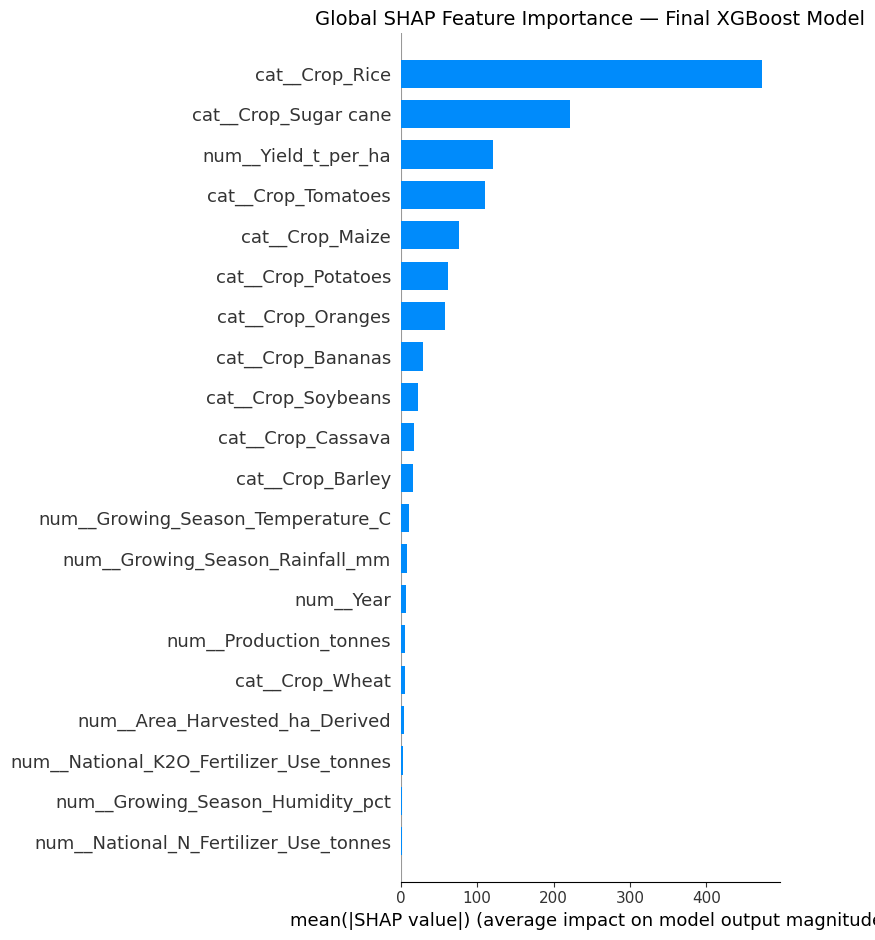

In [90]:
# ============================================
# CELL 86 — SHAP GLOBAL BAR PLOT
# ============================================

plt.figure(figsize=(10, 8))

shap.summary_plot(
    shap_values,
    X_test_transformed,
    feature_names=feature_names,
    plot_type="bar",
    max_display=20,
    show=False
)

plt.title(
    "Global SHAP Feature Importance — Final XGBoost Model",
    fontsize=14
)

plt.tight_layout()
plt.show()

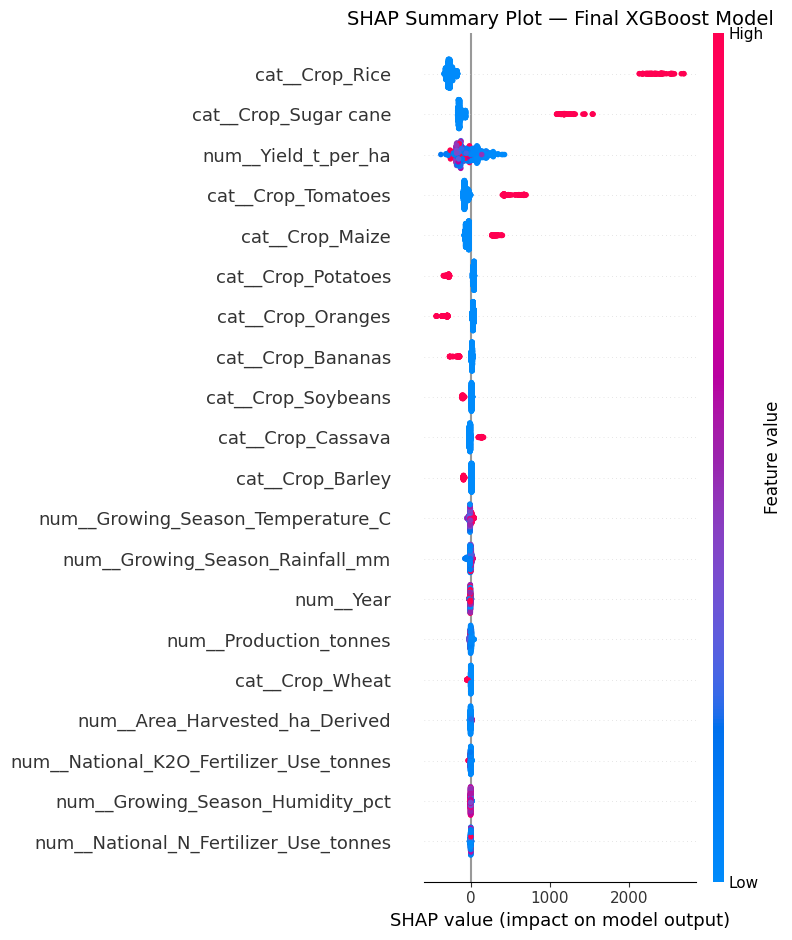

In [91]:
# ============================================
# CELL 87 — SHAP SUMMARY / BEESWARM
# ============================================

plt.figure(figsize=(10, 8))

shap.summary_plot(
    shap_values,
    X_test_transformed,
    feature_names=feature_names,
    max_display=20,
    show=False
)

plt.title(
    "SHAP Summary Plot — Final XGBoost Model",
    fontsize=14
)

plt.tight_layout()
plt.show()

In [92]:
# ============================================
# CELL 88 — SAVE GLOBAL SHAP RESULTS
# ============================================

shap_importance.to_csv(
    "global_shap_feature_importance.csv",
    index=False
)

print("Saved:")
print("global_shap_feature_importance.csv")

Saved:
global_shap_feature_importance.csv


In [93]:
# ============================================
# CELL 89 — GROUPED SHAP FEATURE IMPORTANCE
# ============================================

grouped_shap = {}

for feature, shap_value in zip(feature_names, mean_abs_shap):

    # Remove preprocessing prefix
    clean_feature = feature.replace("num__", "").replace("cat__", "")

    # Group all Crop one-hot variables
    if clean_feature.startswith("Crop_"):
        group = "Crop"

    # Group all Country one-hot variables
    elif clean_feature.startswith("Country_"):
        group = "Country"

    else:
        group = clean_feature

    grouped_shap[group] = grouped_shap.get(group, 0) + shap_value


grouped_shap_df = pd.DataFrame(
    list(grouped_shap.items()),
    columns=["Feature_Group", "Mean_Absolute_SHAP"]
)

grouped_shap_df = (
    grouped_shap_df
    .sort_values("Mean_Absolute_SHAP", ascending=False)
    .reset_index(drop=True)
)

print("=" * 80)
print("GROUPED SHAP FEATURE IMPORTANCE")
print("=" * 80)

display(grouped_shap_df.round(4))

GROUPED SHAP FEATURE IMPORTANCE


,Feature_Group,Mean_Absolute_SHAP
0,Crop,1091.383179
1,Yield_t_per_ha,121.328499
2,Growing_Season_Temperature_C,11.354100
3,Country,8.205000
4,Growing_Season_Rainfall_mm,7.586100
5,Year,6.808500
6,Production_tonnes,5.808700
7,Area_Harvested_ha_Derived,3.694200
8,National_K2O_Fertilizer_Use_tonnes,2.906000
9,Growing_Season_Humidity_pct,2.192700


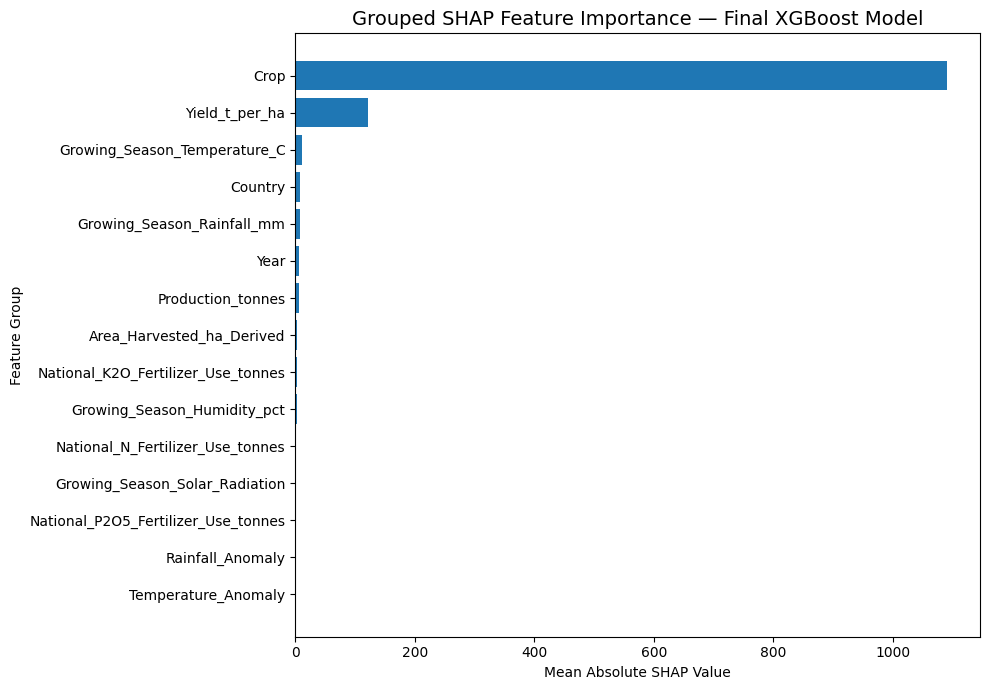

In [94]:
# ============================================
# CELL 90 — GROUPED SHAP BAR PLOT
# ============================================

plt.figure(figsize=(10, 7))

plt.barh(
    grouped_shap_df["Feature_Group"].iloc[::-1],
    grouped_shap_df["Mean_Absolute_SHAP"].iloc[::-1]
)

plt.xlabel("Mean Absolute SHAP Value")
plt.ylabel("Feature Group")
plt.title(
    "Grouped SHAP Feature Importance — Final XGBoost Model",
    fontsize=14
)

plt.tight_layout()
plt.show()

In [95]:
# ============================================
# CELL 91 — SAVE GROUPED SHAP RESULTS
# ============================================

grouped_shap_df.to_csv(
    "grouped_shap_feature_importance.csv",
    index=False
)

print("Saved:")
print("grouped_shap_feature_importance.csv")

Saved:
grouped_shap_feature_importance.csv


In [96]:
# ============================================
# CELL 92 — CROP-SPECIFIC SHAP ANALYSIS
# ============================================

crop_shap_results = []

# Original crop names
crops = sorted(X_test_final["Crop"].dropna().unique())

print("=" * 80)
print("CROP-SPECIFIC SHAP ANALYSIS")
print("=" * 80)

for crop in crops:

    # Select test observations for this crop
    crop_mask = X_test_final["Crop"] == crop

    X_crop = X_test_final.loc[crop_mask].copy()

    if len(X_crop) == 0:
        continue

    # Transform using the SAME fitted preprocessing pipeline
    X_crop_transformed = final_preprocessor.transform(X_crop)

    # SHAP values for this crop
    crop_shap_values = explainer.shap_values(
        X_crop_transformed
    )

    # Mean absolute SHAP
    crop_mean_abs_shap = np.abs(
        crop_shap_values
    ).mean(axis=0)

    # Store results
    for feature, importance in zip(
        feature_names,
        crop_mean_abs_shap
    ):

        crop_shap_results.append({
            "Crop": crop,
            "Feature": feature,
            "Mean_Absolute_SHAP": importance
        })

crop_shap_df = pd.DataFrame(crop_shap_results)

print("\nNumber of crops analyzed:", crop_shap_df["Crop"].nunique())
print("Number of crop-feature combinations:", len(crop_shap_df))

display(crop_shap_df.head(20).round(4))

CROP-SPECIFIC SHAP ANALYSIS

Number of crops analyzed: 11
Number of crop-feature combinations: 594


,Crop,Feature,Mean_Absolute_SHAP
0,Bananas,num__Year,5.008800
1,Bananas,num__Area_Harvested_ha_Derived,3.297500
2,Bananas,num__Production_tonnes,3.521200
3,Bananas,num__Yield_t_per_ha,149.210602
4,Bananas,num__National_N_Fertilizer_Use_tonnes,1.130300
5,Bananas,num__National_P2O5_Fertilizer_Use_tonnes,1.032400
6,Bananas,num__National_K2O_Fertilizer_Use_tonnes,2.430000
7,Bananas,num__Growing_Season_Temperature_C,6.841200
8,Bananas,num__Growing_Season_Rainfall_mm,2.015100
9,Bananas,num__Growing_Season_Humidity_pct,1.047200


In [97]:
# ============================================
# CELL 93 — GROUPED CROP-SPECIFIC SHAP
# ============================================

crop_grouped_shap_results = []

for crop in crops:

    crop_subset = crop_shap_df[
        crop_shap_df["Crop"] == crop
    ].copy()

    grouped = {}

    for _, row in crop_subset.iterrows():

        feature = row["Feature"]
        importance = row["Mean_Absolute_SHAP"]

        clean_feature = (
            feature
            .replace("num__", "")
            .replace("cat__", "")
        )

        # Exclude crop identity for within-crop analysis
        if clean_feature.startswith("Crop_"):
            continue

        # Group all country categories
        if clean_feature.startswith("Country_"):
            group = "Country"
        else:
            group = clean_feature

        grouped[group] = (
            grouped.get(group, 0) + importance
        )

    for feature_group, importance in grouped.items():

        crop_grouped_shap_results.append({
            "Crop": crop,
            "Feature_Group": feature_group,
            "Mean_Absolute_SHAP": importance
        })


crop_grouped_shap_df = pd.DataFrame(
    crop_grouped_shap_results
)

crop_grouped_shap_df = crop_grouped_shap_df.sort_values(
    ["Crop", "Mean_Absolute_SHAP"],
    ascending=[True, False]
).reset_index(drop=True)

print("=" * 80)
print("GROUPED CROP-SPECIFIC SHAP IMPORTANCE")
print("=" * 80)

display(
    crop_grouped_shap_df.head(50).round(4)
)

GROUPED CROP-SPECIFIC SHAP IMPORTANCE


,Crop,Feature_Group,Mean_Absolute_SHAP
0,Bananas,Yield_t_per_ha,149.2106
1,Bananas,Growing_Season_Temperature_C,6.8412
2,Bananas,Year,5.0088
3,Bananas,Country,4.6283
4,Bananas,Production_tonnes,3.5212
5,Bananas,Area_Harvested_ha_Derived,3.2975
6,Bananas,National_K2O_Fertilizer_Use_tonnes,2.4300
7,Bananas,Growing_Season_Rainfall_mm,2.0151
8,Bananas,National_N_Fertilizer_Use_tonnes,1.1303
9,Bananas,Growing_Season_Solar_Radiation,1.1242


In [98]:
# ============================================
# CELL 94 — TOP 5 SHAP DRIVERS BY CROP
# ============================================

top5_crop_shap = (
    crop_grouped_shap_df
    .groupby("Crop", group_keys=False)
    .head(5)
    .copy()
)

print("=" * 80)
print("TOP 5 PREDICTIVE DRIVERS BY CROP")
print("=" * 80)

display(
    top5_crop_shap.round(4)
)

TOP 5 PREDICTIVE DRIVERS BY CROP


,Crop,Feature_Group,Mean_Absolute_SHAP
0,Bananas,Yield_t_per_ha,149.2106
1,Bananas,Growing_Season_Temperature_C,6.8412
2,Bananas,Year,5.0088
3,Bananas,Country,4.6283
4,Bananas,Production_tonnes,3.5212
14,Barley,Yield_t_per_ha,102.8058
15,Barley,Growing_Season_Rainfall_mm,8.7958
16,Barley,Growing_Season_Temperature_C,8.2705
17,Barley,Country,6.8929
18,Barley,Year,4.5881


In [99]:
# ============================================
# CELL 95 — CROP × FEATURE SHAP MATRIX
# ============================================

crop_shap_matrix = crop_grouped_shap_df.pivot(
    index="Crop",
    columns="Feature_Group",
    values="Mean_Absolute_SHAP"
)

crop_shap_matrix = crop_shap_matrix.fillna(0)

print("=" * 80)
print("CROP × FEATURE SHAP IMPORTANCE MATRIX")
print("=" * 80)

display(
    crop_shap_matrix.round(4)
)

CROP × FEATURE SHAP IMPORTANCE MATRIX


Feature_Group,Area_Harvested_ha_Derived,Country,Growing_Season_Humidity_pct,Growing_Season_Rainfall_mm,Growing_Season_Solar_Radiation,Growing_Season_Temperature_C,National_K2O_Fertilizer_Use_tonnes,National_N_Fertilizer_Use_tonnes,National_P2O5_Fertilizer_Use_tonnes,Production_tonnes,Rainfall_Anomaly,Temperature_Anomaly,Year,Yield_t_per_ha
Crop,,,,,,,,,,,,,,
Bananas,3.2975,4.6283,1.0472,2.0151,1.1242,6.8412,2.4300,1.1303,1.0324,3.5212,0.8923,0.3439,5.0088,149.2106
Barley,3.0557,6.8929,1.9374,8.7958,1.2119,8.2705,2.1618,1.3357,1.2157,4.0336,0.5632,0.4715,4.5881,102.8058
Cassava,1.9026,5.7501,1.5268,2.5914,0.9854,8.6901,4.1723,1.5891,2.4319,4.9725,0.7931,0.2810,6.2607,106.1649
Maize,4.7611,6.5448,1.6963,5.3374,2.3747,14.8361,2.8711,2.4424,2.0546,4.2929,0.5520,0.4612,8.9883,84.8795
Oranges,2.6634,4.8428,0.9812,3.6450,0.8777,6.4426,1.7185,1.9056,2.1542,4.2419,0.5631,0.3901,5.7195,107.4230
Potatoes,2.5485,5.2784,2.4101,12.0806,0.7410,6.1600,1.7793,1.5311,1.0215,3.1076,0.4993,0.4088,4.5086,143.0703
Rice,3.0394,17.0048,4.2565,6.9061,4.8346,25.4999,2.1129,3.0460,2.8832,9.9295,1.8546,0.7785,15.2515,150.6361
Soybeans,3.5609,5.7934,1.2812,3.2940,0.8511,7.6968,1.8787,1.6342,1.3516,6.1750,0.6072,0.4060,4.6973,153.6550
Sugar cane,7.0558,17.1535,4.4636,16.9143,5.7249,7.4601,4.3761,3.7434,1.8606,12.7461,1.1726,0.7957,4.5766,67.4489


In [100]:
# ============================================
# CELL 96 — SAVE CROP-SPECIFIC SHAP RESULTS
# ============================================

crop_shap_df.to_csv(
    "crop_specific_shap_all_features.csv",
    index=False
)

crop_grouped_shap_df.to_csv(
    "crop_specific_grouped_shap.csv",
    index=False
)

top5_crop_shap.to_csv(
    "top5_shap_drivers_by_crop.csv",
    index=False
)

crop_shap_matrix.to_csv(
    "crop_feature_shap_matrix.csv"
)

print("Saved:")
print("1. crop_specific_shap_all_features.csv")
print("2. crop_specific_grouped_shap.csv")
print("3. top5_shap_drivers_by_crop.csv")
print("4. crop_feature_shap_matrix.csv")

Saved:
1. crop_specific_shap_all_features.csv
2. crop_specific_grouped_shap.csv
3. top5_shap_drivers_by_crop.csv
4. crop_feature_shap_matrix.csv


In [101]:
# ============================================
# CELL 97 — CROP-WISE TEST PERFORMANCE
# ============================================

crop_performance = []

test_results_df = X_test_final.copy()

test_results_df["Actual"] = y_test_final.values
test_results_df["Predicted"] = final_test_pred
test_results_df["Residual"] = (
    test_results_df["Actual"]
    - test_results_df["Predicted"]
)

for crop in sorted(test_results_df["Crop"].unique()):

    crop_data = test_results_df[
        test_results_df["Crop"] == crop
    ]

    y_true_crop = crop_data["Actual"]
    y_pred_crop = crop_data["Predicted"]

    crop_mae = mean_absolute_error(
        y_true_crop,
        y_pred_crop
    )

    crop_rmse = np.sqrt(
        mean_squared_error(
            y_true_crop,
            y_pred_crop
        )
    )

    crop_r2 = r2_score(
        y_true_crop,
        y_pred_crop
    )

    crop_performance.append({
        "Crop": crop,
        "N_Test": len(crop_data),
        "MAE": crop_mae,
        "RMSE": crop_rmse,
        "R2": crop_r2
    })


crop_performance_df = pd.DataFrame(
    crop_performance
)

crop_performance_df = crop_performance_df.sort_values(
    "MAE"
).reset_index(drop=True)

print("=" * 90)
print("CROP-WISE TEST PERFORMANCE — 2021–2023")
print("=" * 90)

display(
    crop_performance_df.round(4)
)

CROP-WISE TEST PERFORMANCE — 2021–2023


,Crop,N_Test,MAE,RMSE,R2
0,Potatoes,90,4.8718,6.2714,0.9385
1,Soybeans,90,6.3140,9.5814,0.9876
2,Barley,72,6.5362,8.7974,0.9898
3,Bananas,72,8.4602,12.1689,0.9561
4,Wheat,78,10.5187,14.0244,0.9792
5,Maize,90,12.9179,18.2852,0.9874
6,Tomatoes,81,13.2360,19.5026,0.9947
7,Oranges,78,14.4712,40.1417,-0.1192
8,Cassava,42,14.5183,20.3456,0.9602
9,Sugar cane,69,22.4034,31.2090,0.9796


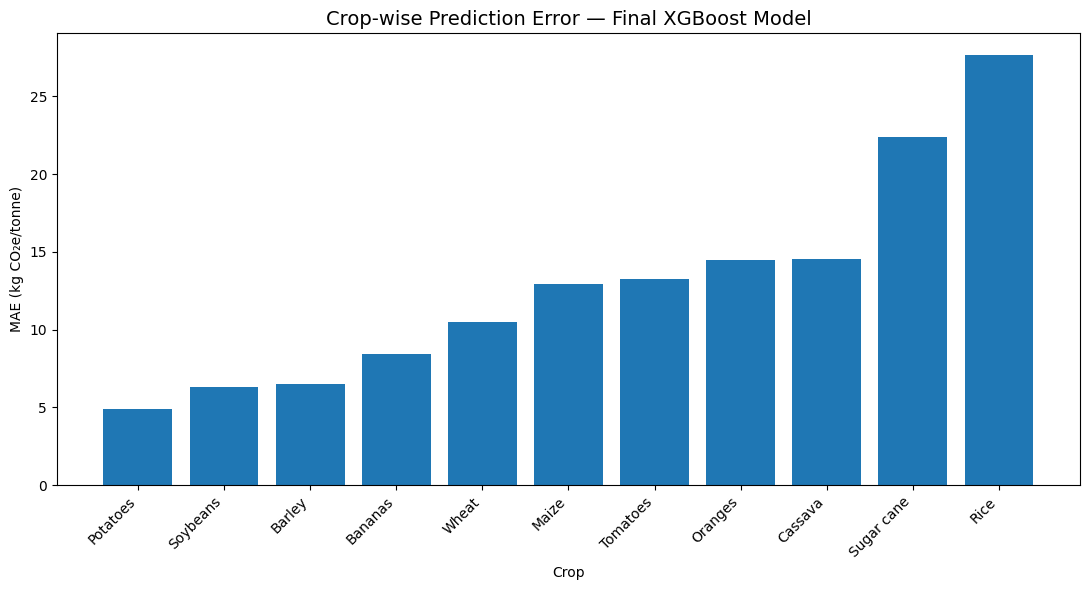

In [102]:
# ============================================
# CELL 98 — CROP-WISE MAE
# ============================================

plt.figure(figsize=(11, 6))

plt.bar(
    crop_performance_df["Crop"],
    crop_performance_df["MAE"]
)

plt.xlabel("Crop")
plt.ylabel("MAE (kg CO₂e/tonne)")
plt.title(
    "Crop-wise Prediction Error — Final XGBoost Model",
    fontsize=14
)

plt.xticks(rotation=45, ha="right")

plt.tight_layout()
plt.show()

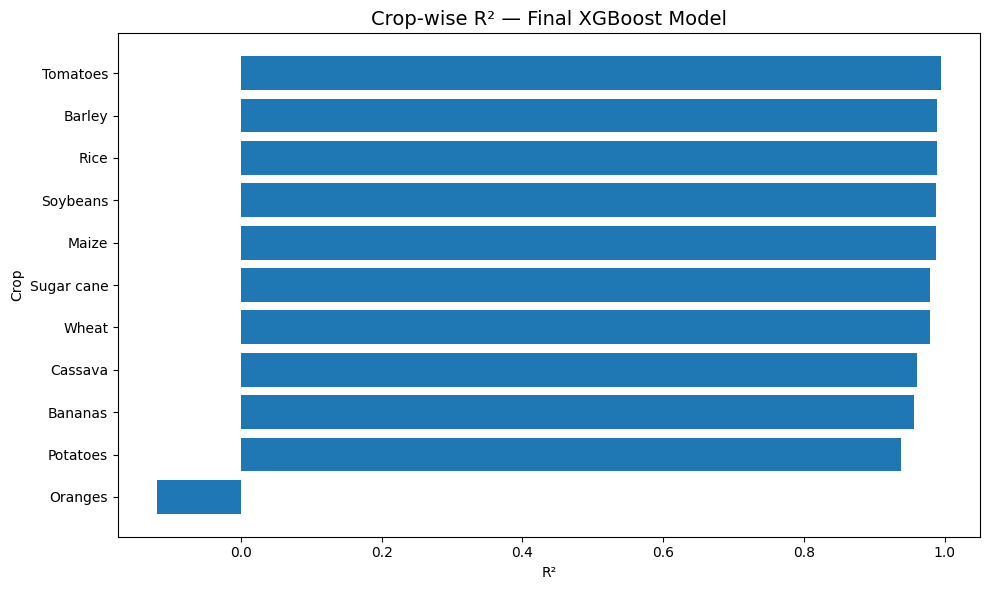

In [103]:
# ============================================
# CELL 99 — CROP-WISE R²
# ============================================

plot_df = crop_performance_df.sort_values(
    "R2",
    ascending=True
)

plt.figure(figsize=(10, 6))

plt.barh(
    plot_df["Crop"],
    plot_df["R2"]
)

plt.xlabel("R²")
plt.ylabel("Crop")
plt.title(
    "Crop-wise R² — Final XGBoost Model",
    fontsize=14
)

plt.tight_layout()
plt.show()

In [104]:
# ============================================
# CELL 100 — SAVE CROP PERFORMANCE
# ============================================

crop_performance_df.to_csv(
    "crop_wise_test_performance.csv",
    index=False
)

test_results_df.to_csv(
    "final_test_predictions_with_residuals.csv",
    index=False
)

print("Saved:")
print("1. crop_wise_test_performance.csv")
print("2. final_test_predictions_with_residuals.csv")

Saved:
1. crop_wise_test_performance.csv
2. final_test_predictions_with_residuals.csv


In [105]:
# ============================================================
# CELL 101 — Detailed Diagnostic for Oranges
# ============================================================

orange_test = test_results_df[
    test_results_df["Crop"] == "Oranges"
].copy()

orange_test["Absolute_Error"] = (
    orange_test["Actual"] - orange_test["Predicted"]
).abs()

orange_test["Squared_Error"] = (
    orange_test["Actual"] - orange_test["Predicted"]
) ** 2

print("=" * 90)
print("ORANGES — DETAILED TEST DIAGNOSTIC (2021–2023)")
print("=" * 90)

print(f"Test samples: {len(orange_test)}")
print(f"MAE:  {mean_absolute_error(orange_test['Actual'], orange_test['Predicted']):.4f}")
print(f"RMSE: {np.sqrt(mean_squared_error(orange_test['Actual'], orange_test['Predicted'])):.4f}")
print(f"R²:   {r2_score(orange_test['Actual'], orange_test['Predicted']):.4f}")

print("\nActual target:")
print(orange_test["Actual"].describe().round(4))

print("\nPredicted target:")
print(orange_test["Predicted"].describe().round(4))

print("\nLargest absolute errors:")
display(
    orange_test[
        [
            "Country",
            "Year",
            "Actual",
            "Predicted",
            "Residual",
            "Absolute_Error"
        ]
    ]
    .sort_values("Absolute_Error", ascending=False)
    .head(15)
    .round(4)
)

ORANGES — DETAILED TEST DIAGNOSTIC (2021–2023)
Test samples: 78
MAE:  14.4712
RMSE: 40.1417
R²:   -0.1192

Actual target:
count     78.0000
mean     217.1657
std       38.1900
min      160.8210
25%      193.8522
50%      206.1330
75%      241.3675
max      289.6270
Name: Actual, dtype: float64

Predicted target:
count     78.0000
mean     225.0500
std       43.9799
min      140.6406
25%      197.0409
50%      211.2651
75%      250.5949
max      358.6182
Name: Predicted, dtype: float64

Largest absolute errors:


,Country,Year,Actual,Predicted,Residual,Absolute_Error
9289,South Africa,2022,161.614,358.618195,-197.0042,197.0042
9288,South Africa,2021,161.735,355.873810,-194.1388,194.1388
9454,Turkey,2023,163.831,322.058502,-158.2275,158.2275
9290,South Africa,2023,160.821,298.413086,-137.5921,137.5921
8822,Brazil,2023,175.550,140.640594,34.9094,34.9094
9057,Iran,2023,168.723,192.329407,-23.6065,23.6065
9023,Indonesia,2023,168.297,186.110199,-17.8132,17.8132
8786,Bangladesh,2021,288.428,271.024506,17.4035,17.4035
9089,Italy,2021,197.414,214.666794,-17.2528,17.2528
9255,Russia,2022,285.966,303.025085,-17.0591,17.0591


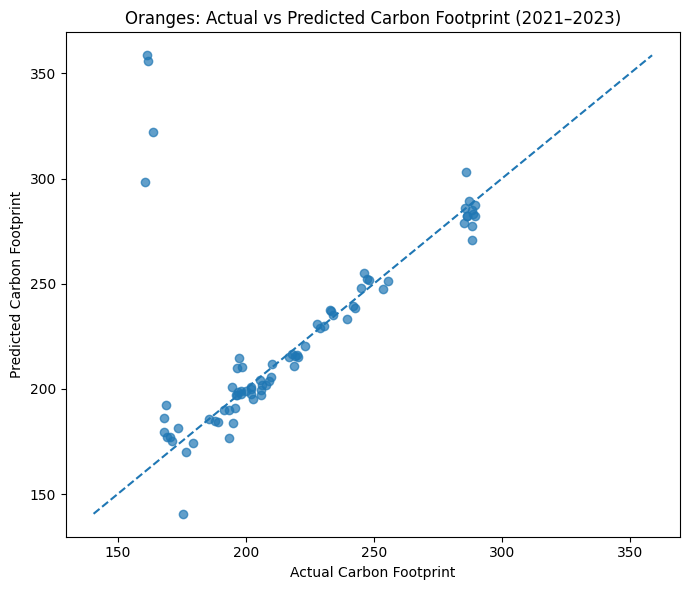

In [106]:
# ============================================================
# CELL 102 — Oranges: Actual vs Predicted
# ============================================================

plt.figure(figsize=(7, 6))

plt.scatter(
    orange_test["Actual"],
    orange_test["Predicted"],
    alpha=0.7
)

min_val = min(
    orange_test["Actual"].min(),
    orange_test["Predicted"].min()
)

max_val = max(
    orange_test["Actual"].max(),
    orange_test["Predicted"].max()
)

plt.plot(
    [min_val, max_val],
    [min_val, max_val],
    linestyle="--"
)

plt.xlabel("Actual Carbon Footprint")
plt.ylabel("Predicted Carbon Footprint")
plt.title("Oranges: Actual vs Predicted Carbon Footprint (2021–2023)")
plt.tight_layout()
plt.show()

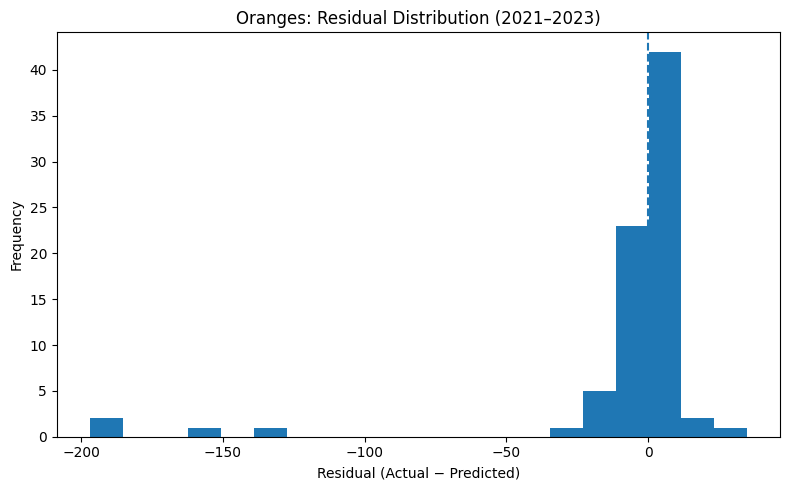

In [107]:
# ============================================================
# CELL 103 — Oranges Residual Analysis
# ============================================================

plt.figure(figsize=(8, 5))

plt.hist(
    orange_test["Residual"],
    bins=20
)

plt.axvline(
    0,
    linestyle="--"
)

plt.xlabel("Residual (Actual − Predicted)")
plt.ylabel("Frequency")
plt.title("Oranges: Residual Distribution (2021–2023)")
plt.tight_layout()
plt.show()

In [108]:
# ============================================================
# CELL 104 — Investigate Large Orange Errors
# ============================================================

large_error_oranges = orange_test[
    orange_test["Absolute_Error"] >= 50
].copy()

print("=" * 100)
print("ORANGES — LARGE ERROR OBSERVATIONS")
print("=" * 100)

print(f"Number of observations with |error| >= 50: {len(large_error_oranges)}")

diagnostic_cols = [
    "Country",
    "Year",
    "Crop",
    "Area_Harvested_ha_Derived",
    "Production_tonnes",
    "Yield_t_per_ha",
    "National_N_Fertilizer_Use_tonnes",
    "National_P2O5_Fertilizer_Use_tonnes",
    "National_K2O_Fertilizer_Use_tonnes",
    "Growing_Season_Temperature_C",
    "Growing_Season_Rainfall_mm",
    "Growing_Season_Humidity_pct",
    "Growing_Season_Solar_Radiation",
    "Temperature_Anomaly",
    "Rainfall_Anomaly",
    "Actual",
    "Predicted",
    "Residual",
    "Absolute_Error"
]

display(
    large_error_oranges[
        [c for c in diagnostic_cols if c in large_error_oranges.columns]
    ]
    .sort_values("Absolute_Error", ascending=False)
    .round(4)
)

ORANGES — LARGE ERROR OBSERVATIONS
Number of observations with |error| >= 50: 4


,Country,Year,Crop,Area_Harvested_ha_Derived,Production_tonnes,Yield_t_per_ha,National_N_Fertilizer_Use_tonnes,National_P2O5_Fertilizer_Use_tonnes,National_K2O_Fertilizer_Use_tonnes,Growing_Season_Temperature_C,Growing_Season_Rainfall_mm,Growing_Season_Humidity_pct,Growing_Season_Solar_Radiation,Temperature_Anomaly,Rainfall_Anomaly,Actual,Predicted,Residual,Absolute_Error
9289,South Africa,2022,Oranges,39173.62,1747778.0,44.62,541671,321449,234477.0,19.97,572.4,57.54,19.88,-0.161,129.87,161.614,358.618195,-197.0042,197.0042
9288,South Africa,2021,Oranges,36236.28,1612170.0,44.49,618738,348758,288170.0,19.96,513.0,52.09,19.88,-0.171,70.47,161.735,355.873810,-194.1388,194.1388
9454,Turkey,2023,Oranges,49482.02,2311335.0,46.71,1948185,735854,145768.0,12.24,305.1,66.12,16.43,1.665,2.79,163.831,322.058502,-158.2275,158.2275
9290,South Africa,2023,Oranges,35649.90,1611657.2,45.21,420638,298891,206710.0,20.77,386.1,50.56,20.55,0.639,-56.43,160.821,298.413086,-137.5921,137.5921


In [109]:
# ============================================================
# CELL 105 — South Africa Orange Diagnostic
# ============================================================

south_africa_orange = test_results_df[
    (test_results_df["Crop"] == "Oranges") &
    (test_results_df["Country"] == "South Africa")
].copy()

print("=" * 90)
print("SOUTH AFRICA — ORANGES TEST OBSERVATIONS")
print("=" * 90)

display(
    south_africa_orange[
        [
            "Country",
            "Year",
            "Actual",
            "Predicted",
            "Residual"
        ]
    ]
    .sort_values("Year")
    .round(4)
)

SOUTH AFRICA — ORANGES TEST OBSERVATIONS


,Country,Year,Actual,Predicted,Residual
9288,South Africa,2021,161.735,355.873810,-194.1388
9289,South Africa,2022,161.614,358.618195,-197.0042
9290,South Africa,2023,160.821,298.413086,-137.5921


In [110]:
# ============================================================
# CELL 106 — Country-wise Orange Performance
# ============================================================

orange_country_performance = []

for country in sorted(orange_test["Country"].unique()):

    country_data = orange_test[
        orange_test["Country"] == country
    ]

    y_true = country_data["Actual"]
    y_pred = country_data["Predicted"]

    orange_country_performance.append({
        "Country": country,
        "N_Test": len(country_data),
        "MAE": mean_absolute_error(y_true, y_pred),
        "RMSE": np.sqrt(mean_squared_error(y_true, y_pred)),
        "R2": r2_score(y_true, y_pred) if len(country_data) >= 2 else np.nan
    })

orange_country_df = (
    pd.DataFrame(orange_country_performance)
    .sort_values("MAE", ascending=False)
    .reset_index(drop=True)
)

display(orange_country_df.round(4))

,Country,N_Test,MAE,RMSE,R2
0,South Africa,3,176.2450,178.3556,-193588.2026
1,Turkey,3,54.0965,91.3816,-100.9067
2,Brazil,3,15.4296,20.6959,-173.8716
3,Italy,3,14.1558,14.3381,-281.2894
4,Iran,3,12.6692,14.8460,-51.0503
5,Indonesia,3,12.4426,13.0710,-758.3280
6,Bangladesh,3,10.5536,11.9999,-72553.4737
7,Argentina,3,10.3892,11.6794,-261.2705
8,Russia,3,7.7743,10.2112,-462.4166
9,Spain,3,7.0440,7.2301,0.0386


In [111]:
# ============================================================
# CELL 107 — Overall Test Residual Analysis
# ============================================================

residual_summary = pd.DataFrame({
    "Metric": [
        "Mean Residual",
        "Median Residual",
        "Mean Absolute Error",
        "RMSE",
        "Residual Std",
        "Minimum Residual",
        "Maximum Residual"
    ],
    "Value": [
        test_results_df["Residual"].mean(),
        test_results_df["Residual"].median(),
        test_results_df["Residual"].abs().mean(),
        np.sqrt(np.mean(test_results_df["Residual"] ** 2)),
        test_results_df["Residual"].std(),
        test_results_df["Residual"].min(),
        test_results_df["Residual"].max()
    ]
})

print("=" * 80)
print("OVERALL TEST RESIDUAL SUMMARY — 2021–2023")
print("=" * 80)

display(residual_summary.round(4))

OVERALL TEST RESIDUAL SUMMARY — 2021–2023


,Metric,Value
0,Mean Residual,-0.3847
1,Median Residual,0.1951
2,Mean Absolute Error,12.7590
3,RMSE,22.5990
4,Residual Std,22.6090
5,Minimum Residual,-197.0042
6,Maximum Residual,138.2753


In [112]:
# ============================================================
# CELL 108 — Largest Overall Test Errors
# ============================================================

test_results_df["Absolute_Error"] = (
    test_results_df["Residual"].abs()
)

largest_errors = (
    test_results_df[
        [
            "Country",
            "Crop",
            "Year",
            "Actual",
            "Predicted",
            "Residual",
            "Absolute_Error"
        ]
    ]
    .sort_values("Absolute_Error", ascending=False)
    .head(20)
)

print("=" * 100)
print("TOP 20 LARGEST TEST-SET ABSOLUTE ERRORS")
print("=" * 100)

display(largest_errors.round(4))

TOP 20 LARGEST TEST-SET ABSOLUTE ERRORS


,Country,Crop,Year,Actual,Predicted,Residual,Absolute_Error
9289,South Africa,Oranges,2022,161.614,358.618195,-197.0042,197.0042
9288,South Africa,Oranges,2021,161.735,355.873810,-194.1388,194.1388
9454,Turkey,Oranges,2023,163.831,322.058502,-158.2275,158.2275
6184,Argentina,Sugar cane,2023,2769.538,2631.262695,138.2753,138.2753
9290,South Africa,Oranges,2023,160.821,298.413086,-137.5921,137.5921
424,Kenya,Rice,2023,3250.630,3368.470459,-117.8405,117.8405
592,Pakistan,Rice,2021,3713.369,3608.533691,104.8353,104.8353
422,Kenya,Rice,2021,3261.492,3364.405273,-102.9133,102.9133
8013,Egypt,Tomatoes,2023,1221.889,1301.457031,-79.5680,79.5680
593,Pakistan,Rice,2022,3771.623,3697.890381,73.7326,73.7326


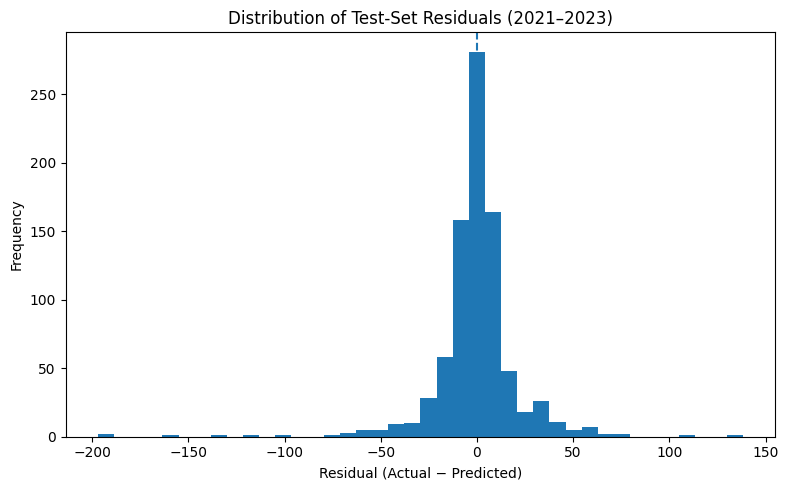

In [113]:
# ============================================================
# CELL 109 — Overall Residual Distribution
# ============================================================

plt.figure(figsize=(8, 5))

plt.hist(
    test_results_df["Residual"],
    bins=40
)

plt.axvline(
    0,
    linestyle="--"
)

plt.xlabel("Residual (Actual − Predicted)")
plt.ylabel("Frequency")
plt.title("Distribution of Test-Set Residuals (2021–2023)")
plt.tight_layout()
plt.show()

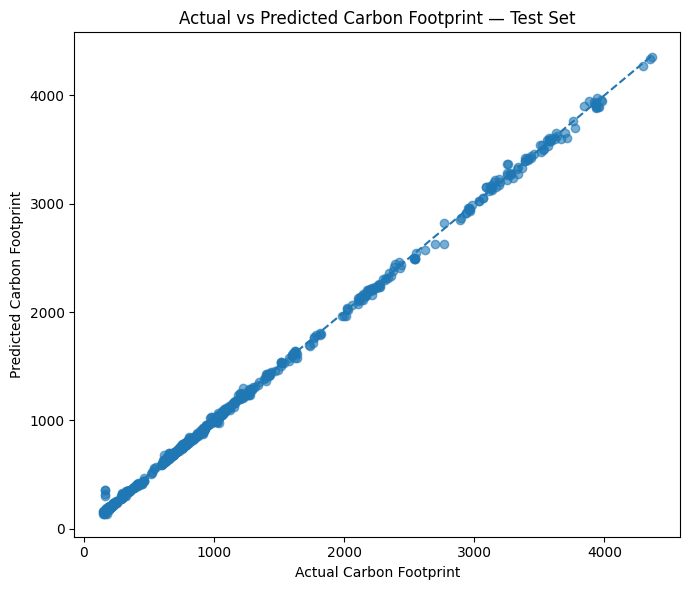

In [114]:
# ============================================================
# CELL 110 — Overall Actual vs Predicted
# ============================================================

plt.figure(figsize=(7, 6))

plt.scatter(
    test_results_df["Actual"],
    test_results_df["Predicted"],
    alpha=0.6
)

min_val = min(
    test_results_df["Actual"].min(),
    test_results_df["Predicted"].min()
)

max_val = max(
    test_results_df["Actual"].max(),
    test_results_df["Predicted"].max()
)

plt.plot(
    [min_val, max_val],
    [min_val, max_val],
    linestyle="--"
)

plt.xlabel("Actual Carbon Footprint")
plt.ylabel("Predicted Carbon Footprint")
plt.title("Actual vs Predicted Carbon Footprint — Test Set")
plt.tight_layout()
plt.show()

In [115]:
# ============================================================
# CELL 111 — Relative Error Analysis
# ============================================================

test_results_df["Absolute_Percentage_Error"] = (
    test_results_df["Absolute_Error"] /
    test_results_df["Actual"].abs()
) * 100

relative_error_by_crop = (
    test_results_df
    .groupby("Crop")
    .agg(
        N_Test=("Actual", "size"),
        Mean_Absolute_Percentage_Error=(
            "Absolute_Percentage_Error", "mean"
        ),
        Median_Absolute_Percentage_Error=(
            "Absolute_Percentage_Error", "median"
        )
    )
    .reset_index()
    .sort_values(
        "Mean_Absolute_Percentage_Error",
        ascending=True
    )
)

display(relative_error_by_crop.round(4))

,Crop,N_Test,Mean_Absolute_Percentage_Error,Median_Absolute_Percentage_Error
6,Rice,87,0.8047,0.5520
7,Soybeans,90,0.8774,0.6619
8,Sugar cane,69,0.9518,0.7592
1,Barley,72,0.9545,0.6750
9,Tomatoes,81,0.9800,0.7521
3,Maize,90,1.1564,0.8360
10,Wheat,78,1.4101,0.9085
2,Cassava,42,1.6582,1.0621
0,Bananas,72,2.2986,1.4322
5,Potatoes,90,2.7356,2.1242


In [116]:
# ============================================================
# CELL 112 — Country-Held-Out Robustness Validation
# ============================================================

from sklearn.model_selection import GroupKFold

country_cv_df = model_df_k2o.copy()

country_features = [
    "Country",
    "Crop",
    "Year",
    "Area_Harvested_ha_Derived",
    "Production_tonnes",
    "Yield_t_per_ha",
    "National_N_Fertilizer_Use_tonnes",
    "National_P2O5_Fertilizer_Use_tonnes",
    "National_K2O_Fertilizer_Use_tonnes",
    "Growing_Season_Temperature_C",
    "Growing_Season_Rainfall_mm",
    "Growing_Season_Humidity_pct",
    "Growing_Season_Solar_Radiation",
    "Temperature_Anomaly",
    "Rainfall_Anomaly"
]

X_country = country_cv_df[country_features].copy()
y_country = country_cv_df["Carbon_Footprint_kgCO2e_per_tonne"].copy()

categorical_country = ["Country", "Crop"]

numeric_country = [
    c for c in country_features
    if c not in categorical_country
]

country_preprocessor = ColumnTransformer(
    transformers=[
        (
            "num",
            Pipeline([
                ("imputer", SimpleImputer(strategy="median")),
                ("scaler", StandardScaler())
            ]),
            numeric_country
        ),
        (
            "cat",
            Pipeline([
                ("imputer", SimpleImputer(strategy="most_frequent")),
                ("onehot", OneHotEncoder(
                    handle_unknown="ignore",
                    sparse_output=False
                ))
            ]),
            categorical_country
        )
    ]
)

country_model = XGBRegressor(
    n_estimators=500,
    learning_rate=0.05,
    max_depth=6,
    min_child_weight=3,
    subsample=0.8,
    colsample_bytree=0.8,
    reg_alpha=0.0,
    reg_lambda=1.0,
    objective="reg:squarederror",
    random_state=42,
    n_jobs=-1
)

country_pipeline = Pipeline([
    ("preprocessor", country_preprocessor),
    ("model", country_model)
])

group_kfold = GroupKFold(n_splits=5)

country_results = []

for fold, (train_idx, test_idx) in enumerate(
    group_kfold.split(
        X_country,
        y_country,
        groups=country_cv_df["Country"]
    ),
    start=1
):

    X_train_country = X_country.iloc[train_idx]
    X_test_country = X_country.iloc[test_idx]

    y_train_country = y_country.iloc[train_idx]
    y_test_country = y_country.iloc[test_idx]

    country_pipeline.fit(
        X_train_country,
        y_train_country
    )

    pred_country = country_pipeline.predict(
        X_test_country
    )

    fold_mae = mean_absolute_error(
        y_test_country,
        pred_country
    )

    fold_rmse = np.sqrt(
        mean_squared_error(
            y_test_country,
            pred_country
        )
    )

    fold_r2 = r2_score(
        y_test_country,
        pred_country
    )

    test_countries = sorted(
        country_cv_df.iloc[test_idx]["Country"].unique()
    )

    country_results.append({
        "Fold": fold,
        "N_Test": len(test_idx),
        "N_Countries": len(test_countries),
        "Countries": ", ".join(test_countries),
        "MAE": fold_mae,
        "RMSE": fold_rmse,
        "R2": fold_r2
    })

country_cv_results_df = pd.DataFrame(country_results)

print("=" * 100)
print("COUNTRY-HELD-OUT ROBUSTNESS VALIDATION")
print("=" * 100)

display(
    country_cv_results_df.round(4)
)

COUNTRY-HELD-OUT ROBUSTNESS VALIDATION


,Fold,N_Test,N_Countries,Countries,MAE,RMSE,R2
0,1,1897,6,"Mexico, Myanmar, Philippines, Spain, Sri Lanka...",22.4826,35.2042,0.9989
1,2,1901,6,"Argentina, Bangladesh, Brazil, France, Russia,...",31.6846,50.8339,0.9973
2,3,1883,6,"Australia, China, Nigeria, Tanzania, Ukraine, ...",31.8629,48.2567,0.9979
3,4,1813,6,"Ethiopia, India, Iran, Nepal, Pakistan, United...",32.0985,53.5361,0.9974
4,5,1864,6,"Canada, Egypt, Indonesia, Italy, Kenya, South ...",23.6639,43.6067,0.9979


In [117]:
# ============================================================
# CELL 113 — Country-Held-Out Overall Summary
# ============================================================

country_summary = pd.DataFrame({
    "Metric": [
        "MAE",
        "RMSE",
        "R2"
    ],
    "Mean": [
        country_cv_results_df["MAE"].mean(),
        country_cv_results_df["RMSE"].mean(),
        country_cv_results_df["R2"].mean()
    ],
    "Std": [
        country_cv_results_df["MAE"].std(),
        country_cv_results_df["RMSE"].std(),
        country_cv_results_df["R2"].std()
    ],
    "Minimum": [
        country_cv_results_df["MAE"].min(),
        country_cv_results_df["RMSE"].min(),
        country_cv_results_df["R2"].min()
    ],
    "Maximum": [
        country_cv_results_df["MAE"].max(),
        country_cv_results_df["RMSE"].max(),
        country_cv_results_df["R2"].max()
    ]
})

print("=" * 90)
print("COUNTRY-HELD-OUT ROBUSTNESS — SUMMARY")
print("=" * 90)

display(country_summary.round(4))

COUNTRY-HELD-OUT ROBUSTNESS — SUMMARY


,Metric,Mean,Std,Minimum,Maximum
0,MAE,28.3585,4.8450,22.4826,32.0985
1,RMSE,46.2875,7.1958,35.2042,53.5361
2,R2,0.9978,0.0006,0.9973,0.9989


In [118]:
# ============================================================
# CELL 114 — Conformal Prediction Calibration Setup
# ============================================================

# Development period:
# Training:    1990–2016
# Calibration: 2017–2020
# Final Test:  2021–2023

conformal_train = model_df_k2o[
    model_df_k2o["Year"] <= 2016
].copy()

conformal_calibration = model_df_k2o[
    (model_df_k2o["Year"] >= 2017) &
    (model_df_k2o["Year"] <= 2020)
].copy()

conformal_test = model_df_k2o[
    model_df_k2o["Year"] >= 2021
].copy()

print("=" * 90)
print("CONFORMAL PREDICTION DATA SPLIT")
print("=" * 90)

print(f"Training:    {conformal_train['Year'].min()}–{conformal_train['Year'].max()} | "
      f"N = {len(conformal_train)}")

print(f"Calibration: {conformal_calibration['Year'].min()}–{conformal_calibration['Year'].max()} | "
      f"N = {len(conformal_calibration)}")

print(f"Test:        {conformal_test['Year'].min()}–{conformal_test['Year'].max()} | "
      f"N = {len(conformal_test)}")

CONFORMAL PREDICTION DATA SPLIT
Training:    1990–2016 | N = 7376
Calibration: 2017–2020 | N = 1133
Test:        2021–2023 | N = 849


In [119]:
# ============================================================
# CELL 115 — Train Model for Conformal Calibration
# SELF-CONTAINED VERSION
# ============================================================

# Target
target_col = "Carbon_Footprint_kgCO2e_per_tonne"

# Features used in the final XGBoost model
conformal_features = [
    "Country",
    "Crop",
    "Year",
    "Area_Harvested_ha_Derived",
    "Production_tonnes",
    "Yield_t_per_ha",
    "National_N_Fertilizer_Use_tonnes",
    "National_P2O5_Fertilizer_Use_tonnes",
    "National_K2O_Fertilizer_Use_tonnes",
    "Growing_Season_Temperature_C",
    "Growing_Season_Rainfall_mm",
    "Growing_Season_Humidity_pct",
    "Growing_Season_Solar_Radiation",
    "Temperature_Anomaly",
    "Rainfall_Anomaly"
]

# ------------------------------------------------------------
# Prepare X and y
# ------------------------------------------------------------

X_conf_train = conformal_train[conformal_features].copy()
y_conf_train = conformal_train[target_col].copy()

X_conf_cal = conformal_calibration[conformal_features].copy()
y_conf_cal = conformal_calibration[target_col].copy()

X_conf_test = conformal_test[conformal_features].copy()
y_conf_test = conformal_test[target_col].copy()


# ------------------------------------------------------------
# Define preprocessing
# ------------------------------------------------------------

categorical_conf = [
    "Country",
    "Crop"
]

numeric_conf = [
    col for col in conformal_features
    if col not in categorical_conf
]

conformal_preprocessor = ColumnTransformer(
    transformers=[
        (
            "num",
            Pipeline([
                ("imputer", SimpleImputer(strategy="median")),
                ("scaler", StandardScaler())
            ]),
            numeric_conf
        ),
        (
            "cat",
            Pipeline([
                ("imputer", SimpleImputer(strategy="most_frequent")),
                ("onehot", OneHotEncoder(
                    handle_unknown="ignore",
                    sparse_output=False
                ))
            ]),
            categorical_conf
        )
    ]
)


# ------------------------------------------------------------
# Define final/frozen XGBoost model
# ------------------------------------------------------------

conformal_xgb = XGBRegressor(
    n_estimators=500,
    learning_rate=0.05,
    max_depth=6,
    min_child_weight=3,
    subsample=0.8,
    colsample_bytree=0.8,
    reg_alpha=0.0,
    reg_lambda=1.0,
    objective="reg:squarederror",
    random_state=42,
    n_jobs=-1
)


# ------------------------------------------------------------
# Complete pipeline
# ------------------------------------------------------------

conformal_model = Pipeline(
    steps=[
        ("preprocessor", conformal_preprocessor),
        ("model", conformal_xgb)
    ]
)


# ------------------------------------------------------------
# Fit only on 1990–2016
# ------------------------------------------------------------

conformal_model.fit(
    X_conf_train,
    y_conf_train
)


# ------------------------------------------------------------
# Predictions
# ------------------------------------------------------------

calibration_pred = conformal_model.predict(
    X_conf_cal
)

test_conf_pred = conformal_model.predict(
    X_conf_test
)


# ------------------------------------------------------------
# Basic verification
# ------------------------------------------------------------

print("=" * 90)
print("CONFORMAL MODEL TRAINING COMPLETE")
print("=" * 90)

print(f"Training observations:    {len(X_conf_train)}")
print(f"Calibration observations: {len(X_conf_cal)}")
print(f"Test observations:        {len(X_conf_test)}")

print(f"\nCalibration predictions: {len(calibration_pred)}")
print(f"Test predictions:        {len(test_conf_pred)}")

CONFORMAL MODEL TRAINING COMPLETE
Training observations:    7376
Calibration observations: 1133
Test observations:        849

Calibration predictions: 1133
Test predictions:        849


In [120]:
# ============================================================
# CELL 116 — Conformal Nonconformity Scores
# ============================================================

calibration_scores = np.abs(
    y_conf_cal.values - calibration_pred
)

print("=" * 80)
print("CONFORMAL CALIBRATION SCORES")
print("=" * 80)

print(f"Number of calibration observations: {len(calibration_scores)}")
print(f"Mean absolute calibration error: {calibration_scores.mean():.4f}")
print(f"Median absolute calibration error: {np.median(calibration_scores):.4f}")
print(f"90th percentile: {np.quantile(calibration_scores, 0.90):.4f}")
print(f"95th percentile: {np.quantile(calibration_scores, 0.95):.4f}")
print(f"99th percentile: {np.quantile(calibration_scores, 0.99):.4f}")

CONFORMAL CALIBRATION SCORES
Number of calibration observations: 1133
Mean absolute calibration error: 11.5293
Median absolute calibration error: 6.0729
90th percentile: 26.4093
95th percentile: 41.0887
99th percentile: 80.1713


In [121]:
# ============================================================
# CELL 117 — Conformal Prediction Intervals
# ============================================================

n_cal = len(calibration_scores)

def conformal_quantile(scores, alpha):
    """
    Finite-sample conformal quantile.
    """
    q_level = np.ceil((n_cal + 1) * (1 - alpha)) / n_cal
    q_level = min(q_level, 1.0)
    return np.quantile(scores, q_level, method="higher")


q90 = conformal_quantile(
    calibration_scores,
    alpha=0.10
)

q95 = conformal_quantile(
    calibration_scores,
    alpha=0.05
)

print("=" * 80)
print("CONFORMAL INTERVAL WIDTHS")
print("=" * 80)

print(f"90% conformal error radius: ± {q90:.4f}")
print(f"95% conformal error radius: ± {q95:.4f}")

# 90% interval
lower_90 = test_conf_pred - q90
upper_90 = test_conf_pred + q90

# 95% interval
lower_95 = test_conf_pred - q95
upper_95 = test_conf_pred + q95

CONFORMAL INTERVAL WIDTHS
90% conformal error radius: ± 26.9648
95% conformal error radius: ± 42.3874


In [122]:
# ============================================================
# CELL 118 — Empirical Coverage on Final Test Set
# ============================================================

y_test_conf = y_conf_test.values

coverage_90 = np.mean(
    (y_test_conf >= lower_90) &
    (y_test_conf <= upper_90)
)

coverage_95 = np.mean(
    (y_test_conf >= lower_95) &
    (y_test_conf <= upper_95)
)

width_90 = upper_90 - lower_90
width_95 = upper_95 - lower_95

conformal_results = pd.DataFrame({
    "Interval": ["90%", "95%"],
    "Nominal_Coverage": [0.90, 0.95],
    "Observed_Coverage": [
        coverage_90,
        coverage_95
    ],
    "Mean_Interval_Width": [
        width_90.mean(),
        width_95.mean()
    ],
    "Median_Interval_Width": [
        np.median(width_90),
        np.median(width_95)
    ]
})

print("=" * 90)
print("CONFORMAL PREDICTION — FINAL TEST SET")
print("=" * 90)

display(
    conformal_results.round(4)
)

CONFORMAL PREDICTION — FINAL TEST SET


,Interval,Nominal_Coverage,Observed_Coverage,Mean_Interval_Width,Median_Interval_Width
0,90%,0.90,0.8751,53.9296,53.9296
1,95%,0.95,0.9435,84.7748,84.7748


In [123]:
# ============================================================
# CELL 119 — Crop-wise Conformal Coverage
# ============================================================

conformal_test_results = conformal_test[
    ["Country", "Crop", "Year"]
].copy()

conformal_test_results["Actual"] = y_test_conf
conformal_test_results["Predicted"] = test_conf_pred

conformal_test_results["Lower_90"] = lower_90
conformal_test_results["Upper_90"] = upper_90

conformal_test_results["Lower_95"] = lower_95
conformal_test_results["Upper_95"] = upper_95

crop_conformal = []

for crop in sorted(conformal_test_results["Crop"].unique()):

    crop_data = conformal_test_results[
        conformal_test_results["Crop"] == crop
    ]

    coverage90 = np.mean(
        (crop_data["Actual"] >= crop_data["Lower_90"]) &
        (crop_data["Actual"] <= crop_data["Upper_90"])
    )

    coverage95 = np.mean(
        (crop_data["Actual"] >= crop_data["Lower_95"]) &
        (crop_data["Actual"] <= crop_data["Upper_95"])
    )

    crop_conformal.append({
        "Crop": crop,
        "N_Test": len(crop_data),
        "Coverage_90": coverage90,
        "Coverage_95": coverage95,
        "Mean_Width_90": (
            crop_data["Upper_90"] -
            crop_data["Lower_90"]
        ).mean(),
        "Mean_Width_95": (
            crop_data["Upper_95"] -
            crop_data["Lower_95"]
        ).mean()
    })

crop_conformal_df = (
    pd.DataFrame(crop_conformal)
    .sort_values("Coverage_90")
    .reset_index(drop=True)
)

display(
    crop_conformal_df.round(4)
)

,Crop,N_Test,Coverage_90,Coverage_95,Mean_Width_90,Mean_Width_95
0,Rice,87,0.5632,0.8046,53.9296,84.7748
1,Sugar cane,69,0.7101,0.8116,53.9296,84.7748
2,Cassava,42,0.7857,0.9762,53.9296,84.7748
3,Tomatoes,81,0.8519,0.9630,53.9296,84.7748
4,Maize,90,0.8667,0.9222,53.9296,84.7748
5,Bananas,72,0.9306,1.0000,53.9296,84.7748
6,Oranges,78,0.9359,0.9487,53.9296,84.7748
7,Wheat,78,0.9487,0.9744,53.9296,84.7748
8,Soybeans,90,0.9889,0.9889,53.9296,84.7748
9,Barley,72,1.0000,1.0000,53.9296,84.7748


In [124]:
# ============================================================
# CELL 120 — CROP-WISE CONFORMAL CALIBRATION SCORES
# ============================================================

calibration_results = conformal_calibration[
    ["Country", "Crop", "Year"]
].copy()

calibration_results["Actual"] = y_conf_cal.values
calibration_results["Predicted"] = calibration_pred

calibration_results["Abs_Error"] = np.abs(
    calibration_results["Actual"] -
    calibration_results["Predicted"]
)

print("=" * 90)
print("CROP-WISE CONFORMAL CALIBRATION ERROR")
print("=" * 90)

crop_calibration_summary = (
    calibration_results
    .groupby("Crop")
    .agg(
        N_Calibration=("Abs_Error", "size"),
        Mean_Abs_Error=("Abs_Error", "mean"),
        Median_Abs_Error=("Abs_Error", "median"),
        Q90_Error=("Abs_Error", lambda x: np.quantile(x, 0.90)),
        Q95_Error=("Abs_Error", lambda x: np.quantile(x, 0.95)),
        Max_Abs_Error=("Abs_Error", "max")
    )
    .reset_index()
    .sort_values("Mean_Abs_Error", ascending=False)
)

display(crop_calibration_summary.round(4))

CROP-WISE CONFORMAL CALIBRATION ERROR


,Crop,N_Calibration,Mean_Abs_Error,Median_Abs_Error,Q90_Error,Q95_Error,Max_Abs_Error
6,Rice,116,24.8771,15.0596,57.8360,64.8676,126.5332
8,Sugar cane,93,20.8870,12.7094,50.8420,62.2963,133.9148
9,Tomatoes,108,12.8817,9.0849,25.6429,43.3350,82.2083
3,Maize,120,12.7815,11.0741,23.6729,30.7266,58.0913
2,Cassava,56,10.9328,5.8817,19.7813,51.5390,85.6276
4,Oranges,104,10.2510,3.0779,12.7530,22.9588,190.0443
5,Potatoes,120,8.1642,3.2599,12.4418,17.9583,208.3146
0,Bananas,96,7.5890,4.8541,15.5485,29.8203,47.1500
10,Wheat,104,7.0267,5.4815,12.5748,17.4469,31.1482
1,Barley,96,5.5531,4.8924,13.0383,14.8640,23.6433


In [125]:
# ============================================================
# CELL 121 — CROP-CONDITIONAL CONFORMAL RADII
# ============================================================

def conformal_crop_quantile(scores, alpha):
    """
    Finite-sample split-conformal quantile.
    """
    n = len(scores)

    q_level = np.ceil((n + 1) * (1 - alpha)) / n
    q_level = min(q_level, 1.0)

    return np.quantile(
        scores,
        q_level,
        method="higher"
    )


crop_radii = []

for crop in sorted(calibration_results["Crop"].unique()):

    crop_scores = calibration_results.loc[
        calibration_results["Crop"] == crop,
        "Abs_Error"
    ].values

    q90_crop = conformal_crop_quantile(
        crop_scores,
        alpha=0.10
    )

    q95_crop = conformal_crop_quantile(
        crop_scores,
        alpha=0.05
    )

    crop_radii.append({
        "Crop": crop,
        "N_Calibration": len(crop_scores),
        "Radius_90": q90_crop,
        "Radius_95": q95_crop
    })

crop_radii_df = (
    pd.DataFrame(crop_radii)
    .sort_values("Radius_90", ascending=False)
    .reset_index(drop=True)
)

print("=" * 90)
print("CROP-CONDITIONAL CONFORMAL RADII")
print("=" * 90)

display(crop_radii_df.round(4))

CROP-CONDITIONAL CONFORMAL RADII


,Crop,N_Calibration,Radius_90,Radius_95
0,Rice,116,62.4307,72.8409
1,Sugar cane,93,56.1472,71.1650
2,Cassava,56,48.2258,85.6276
3,Tomatoes,108,39.9390,64.3166
4,Maize,120,25.6750,37.6110
5,Bananas,96,23.7325,32.2458
6,Oranges,104,16.4272,116.6625
7,Wheat,104,14.1930,21.2342
8,Barley,96,13.6247,17.1126
9,Potatoes,120,13.5099,20.5616


In [126]:
# ============================================================
# CELL 122 — APPLY CROP-CONDITIONAL INTERVALS TO TEST SET
# ============================================================

test_crop_conformal = conformal_test[
    ["Country", "Crop", "Year"]
].copy()

test_crop_conformal["Actual"] = y_conf_test.values
test_crop_conformal["Predicted"] = test_conf_pred

# Map crop-specific radii
radius_90_map = dict(
    zip(
        crop_radii_df["Crop"],
        crop_radii_df["Radius_90"]
    )
)

radius_95_map = dict(
    zip(
        crop_radii_df["Crop"],
        crop_radii_df["Radius_95"]
    )
)

test_crop_conformal["Radius_90"] = (
    test_crop_conformal["Crop"]
    .map(radius_90_map)
)

test_crop_conformal["Radius_95"] = (
    test_crop_conformal["Crop"]
    .map(radius_95_map)
)

# Prediction intervals
test_crop_conformal["Lower_90"] = (
    test_crop_conformal["Predicted"] -
    test_crop_conformal["Radius_90"]
)

test_crop_conformal["Upper_90"] = (
    test_crop_conformal["Predicted"] +
    test_crop_conformal["Radius_90"]
)

test_crop_conformal["Lower_95"] = (
    test_crop_conformal["Predicted"] -
    test_crop_conformal["Radius_95"]
)

test_crop_conformal["Upper_95"] = (
    test_crop_conformal["Predicted"] +
    test_crop_conformal["Radius_95"]
)

# Coverage indicators
test_crop_conformal["Covered_90"] = (
    (test_crop_conformal["Actual"] >= test_crop_conformal["Lower_90"]) &
    (test_crop_conformal["Actual"] <= test_crop_conformal["Upper_90"])
)

test_crop_conformal["Covered_95"] = (
    (test_crop_conformal["Actual"] >= test_crop_conformal["Lower_95"]) &
    (test_crop_conformal["Actual"] <= test_crop_conformal["Upper_95"])
)

print("=" * 90)
print("CROP-CONDITIONAL INTERVALS CREATED")
print("=" * 90)

display(
    test_crop_conformal.head(10).round(4)
)

CROP-CONDITIONAL INTERVALS CREATED


,Country,Crop,Year,Actual,Predicted,Radius_90,Radius_95,Lower_90,Upper_90,Lower_95,Upper_95,Covered_90,Covered_95
31,Argentina,Rice,2021,3067.690,3050.757568,62.4307,72.8409,2988.3269,3113.1882,2977.9166,3123.5985,True,True
32,Argentina,Rice,2022,3167.782,3155.418701,62.4307,72.8409,3092.9880,3217.8494,3082.5778,3228.2596,True,True
33,Argentina,Rice,2023,3151.671,3195.278564,62.4307,72.8409,3132.8479,3257.7092,3122.4376,3268.1195,True,True
65,Australia,Rice,2021,2898.951,2864.078857,62.4307,72.8409,2801.6482,2926.5095,2791.2379,2936.9198,True,True
66,Australia,Rice,2022,2768.031,2824.124756,62.4307,72.8409,2761.6941,2886.5554,2751.2838,2896.9657,True,True
67,Australia,Rice,2023,2886.538,2849.251465,62.4307,72.8409,2786.8208,2911.6821,2776.4105,2922.0924,True,True
99,Bangladesh,Rice,2021,3456.192,3457.676514,62.4307,72.8409,3395.2458,3520.1072,3384.8356,3530.5174,True,True
100,Bangladesh,Rice,2022,3433.732,3441.966797,62.4307,72.8409,3379.5361,3504.3975,3369.1259,3514.8077,True,True
101,Bangladesh,Rice,2023,3391.950,3420.260498,62.4307,72.8409,3357.8298,3482.6912,3347.4196,3493.1014,True,True
133,Brazil,Rice,2021,3086.088,3155.927979,62.4307,72.8409,3093.4973,3218.3587,3083.0870,3228.7689,False,True


In [127]:
# ============================================================
# CELL 123 — OVERALL CROP-CONDITIONAL COVERAGE
# ============================================================

conditional_coverage_90 = (
    test_crop_conformal["Covered_90"].mean()
)

conditional_coverage_95 = (
    test_crop_conformal["Covered_95"].mean()
)

conditional_width_90 = (
    test_crop_conformal["Upper_90"] -
    test_crop_conformal["Lower_90"]
)

conditional_width_95 = (
    test_crop_conformal["Upper_95"] -
    test_crop_conformal["Lower_95"]
)

conditional_results = pd.DataFrame({
    "Interval": ["90%", "95%"],
    "Nominal_Coverage": [0.90, 0.95],
    "Observed_Coverage": [
        conditional_coverage_90,
        conditional_coverage_95
    ],
    "Mean_Interval_Width": [
        conditional_width_90.mean(),
        conditional_width_95.mean()
    ],
    "Median_Interval_Width": [
        conditional_width_90.median(),
        conditional_width_95.median()
    ]
})

print("=" * 90)
print("CROP-CONDITIONAL CONFORMAL PREDICTION")
print("=" * 90)

display(
    conditional_results.round(4)
)

CROP-CONDITIONAL CONFORMAL PREDICTION


,Interval,Nominal_Coverage,Observed_Coverage,Mean_Interval_Width,Median_Interval_Width
0,90%,0.90,0.8975,57.1068,47.4651
1,95%,0.95,0.9564,96.3358,75.2220


In [128]:
# ============================================================
# CELL 124 — GLOBAL VS CROP-CONDITIONAL COVERAGE
# ============================================================

comparison_rows = []

for crop in sorted(test_crop_conformal["Crop"].unique()):

    crop_data = test_crop_conformal[
        test_crop_conformal["Crop"] == crop
    ].copy()

    # Global interval coverage from earlier conformal analysis
    global_lower_90 = lower_90[
        conformal_test["Crop"].values == crop
    ]

    global_upper_90 = upper_90[
        conformal_test["Crop"].values == crop
    ]

    global_lower_95 = lower_95[
        conformal_test["Crop"].values == crop
    ]

    global_upper_95 = upper_95[
        conformal_test["Crop"].values == crop
    ]

    actual_values = crop_data["Actual"].values

    global_cov_90 = np.mean(
        (actual_values >= global_lower_90) &
        (actual_values <= global_upper_90)
    )

    global_cov_95 = np.mean(
        (actual_values >= global_lower_95) &
        (actual_values <= global_upper_95)
    )

    conditional_cov_90 = crop_data["Covered_90"].mean()
    conditional_cov_95 = crop_data["Covered_95"].mean()

    comparison_rows.append({
        "Crop": crop,
        "N_Test": len(crop_data),

        "Global_Coverage_90": global_cov_90,
        "Conditional_Coverage_90": conditional_cov_90,

        "Global_Coverage_95": global_cov_95,
        "Conditional_Coverage_95": conditional_cov_95,

        "Global_Width_90": (
            global_upper_90 - global_lower_90
        ).mean(),

        "Conditional_Width_90": (
            crop_data["Upper_90"] -
            crop_data["Lower_90"]
        ).mean(),

        "Global_Width_95": (
            global_upper_95 - global_lower_95
        ).mean(),

        "Conditional_Width_95": (
            crop_data["Upper_95"] -
            crop_data["Lower_95"]
        ).mean()
    })

coverage_comparison_df = (
    pd.DataFrame(comparison_rows)
    .sort_values("Global_Coverage_90")
    .reset_index(drop=True)
)

print("=" * 120)
print("GLOBAL VS CROP-CONDITIONAL CONFORMAL COVERAGE")
print("=" * 120)

display(
    coverage_comparison_df.round(4)
)

GLOBAL VS CROP-CONDITIONAL CONFORMAL COVERAGE


,Crop,N_Test,Global_Coverage_90,Conditional_Coverage_90,Global_Coverage_95,Conditional_Coverage_95,Global_Width_90,Conditional_Width_90,Global_Width_95,Conditional_Width_95
0,Rice,87,0.5632,0.9080,0.8046,0.9540,53.9296,124.8614,84.7748,145.6819
1,Sugar cane,69,0.7101,0.9710,0.8116,0.9710,53.9296,112.2944,84.7748,142.3299
2,Cassava,42,0.7857,0.9762,0.9762,1.0000,53.9296,96.4517,84.7748,171.2551
3,Tomatoes,81,0.8519,0.9506,0.9630,0.9877,53.9296,79.8780,84.7748,128.6332
4,Maize,90,0.8667,0.8667,0.9222,0.9222,53.9296,51.3500,84.7748,75.2220
5,Bananas,72,0.9306,0.9028,1.0000,0.9722,53.9296,47.4651,84.7748,64.4915
6,Oranges,78,0.9359,0.8590,0.9487,0.9487,53.9296,32.8545,84.7748,233.3250
7,Wheat,78,0.9487,0.7436,0.9744,0.8974,53.9296,28.3859,84.7748,42.4684
8,Soybeans,90,0.9889,0.8889,0.9889,0.9778,53.9296,23.7984,84.7748,28.7940
9,Barley,72,1.0000,0.8750,1.0000,0.9167,53.9296,27.2495,84.7748,34.2251


In [129]:
# ============================================================
# CELL 125 — COVERAGE IMPROVEMENT ANALYSIS
# ============================================================

coverage_comparison_df["Coverage_Improvement_90"] = (
    coverage_comparison_df["Conditional_Coverage_90"] -
    coverage_comparison_df["Global_Coverage_90"]
)

coverage_comparison_df["Coverage_Improvement_95"] = (
    coverage_comparison_df["Conditional_Coverage_95"] -
    coverage_comparison_df["Global_Coverage_95"]
)

coverage_comparison_df["Absolute_Error_From_Nominal_90_Global"] = (
    np.abs(
        coverage_comparison_df["Global_Coverage_90"] - 0.90
    )
)

coverage_comparison_df["Absolute_Error_From_Nominal_90_Conditional"] = (
    np.abs(
        coverage_comparison_df["Conditional_Coverage_90"] - 0.90
    )
)

print("=" * 120)
print("COVERAGE IMPROVEMENT ANALYSIS")
print("=" * 120)

display(
    coverage_comparison_df[
        [
            "Crop",
            "N_Test",
            "Global_Coverage_90",
            "Conditional_Coverage_90",
            "Coverage_Improvement_90",
            "Global_Coverage_95",
            "Conditional_Coverage_95",
            "Coverage_Improvement_95"
        ]
    ].round(4)
)

COVERAGE IMPROVEMENT ANALYSIS


,Crop,N_Test,Global_Coverage_90,Conditional_Coverage_90,Coverage_Improvement_90,Global_Coverage_95,Conditional_Coverage_95,Coverage_Improvement_95
0,Rice,87,0.5632,0.9080,0.3448,0.8046,0.9540,0.1494
1,Sugar cane,69,0.7101,0.9710,0.2609,0.8116,0.9710,0.1594
2,Cassava,42,0.7857,0.9762,0.1905,0.9762,1.0000,0.0238
3,Tomatoes,81,0.8519,0.9506,0.0988,0.9630,0.9877,0.0247
4,Maize,90,0.8667,0.8667,0.0000,0.9222,0.9222,0.0000
5,Bananas,72,0.9306,0.9028,-0.0278,1.0000,0.9722,-0.0278
6,Oranges,78,0.9359,0.8590,-0.0769,0.9487,0.9487,0.0000
7,Wheat,78,0.9487,0.7436,-0.2051,0.9744,0.8974,-0.0769
8,Soybeans,90,0.9889,0.8889,-0.1000,0.9889,0.9778,-0.0111
9,Barley,72,1.0000,0.8750,-0.1250,1.0000,0.9167,-0.0833


In [130]:
# ============================================================
# CELL 126 — SAVE CONFORMAL RESULTS
# ============================================================

conformal_results.to_csv(
    "global_conformal_results.csv",
    index=False
)

crop_conformal_df.to_csv(
    "global_conformal_crop_coverage.csv",
    index=False
)

crop_radii_df.to_csv(
    "crop_conditional_conformal_radii.csv",
    index=False
)

conditional_results.to_csv(
    "crop_conditional_conformal_results.csv",
    index=False
)

coverage_comparison_df.to_csv(
    "global_vs_crop_conditional_conformal.csv",
    index=False
)

test_crop_conformal.to_csv(
    "crop_conditional_test_predictions_intervals.csv",
    index=False
)

print("All conformal prediction results saved successfully.")

All conformal prediction results saved successfully.


In [131]:
# ============================================================
# CELL 127 — CALIBRATION VS TEST ABSOLUTE ERRORS
# ============================================================

# Calibration residuals
calibration_error_df = conformal_calibration[
    ["Country", "Crop", "Year"]
].copy()

calibration_error_df["Actual"] = y_conf_cal.values
calibration_error_df["Predicted"] = calibration_pred

calibration_error_df["Residual"] = (
    calibration_error_df["Actual"] -
    calibration_error_df["Predicted"]
)

calibration_error_df["Abs_Error"] = (
    np.abs(calibration_error_df["Residual"])
)

# Final test residuals
test_error_df = conformal_test[
    ["Country", "Crop", "Year"]
].copy()

test_error_df["Actual"] = y_conf_test.values
test_error_df["Predicted"] = test_conf_pred

test_error_df["Residual"] = (
    test_error_df["Actual"] -
    test_error_df["Predicted"]
)

test_error_df["Abs_Error"] = (
    np.abs(test_error_df["Residual"])
)

print("=" * 90)
print("CALIBRATION VS FINAL TEST ERROR DATA")
print("=" * 90)

print(f"Calibration observations: {len(calibration_error_df)}")
print(f"Test observations:        {len(test_error_df)}")

print("\nCalibration years:",
      calibration_error_df["Year"].min(),
      "to",
      calibration_error_df["Year"].max())

print("Test years:",
      test_error_df["Year"].min(),
      "to",
      test_error_df["Year"].max())

CALIBRATION VS FINAL TEST ERROR DATA
Calibration observations: 1133
Test observations:        849

Calibration years: 2017 to 2020
Test years: 2021 to 2023


In [132]:
# ============================================================
# CELL 128 — CROP-WISE ERROR DRIFT
# ============================================================

error_drift_rows = []

for crop in sorted(
    calibration_error_df["Crop"].unique()
):

    cal_crop = calibration_error_df[
        calibration_error_df["Crop"] == crop
    ]["Abs_Error"].values

    test_crop = test_error_df[
        test_error_df["Crop"] == crop
    ]["Abs_Error"].values

    error_drift_rows.append({
        "Crop": crop,

        "N_Calibration": len(cal_crop),
        "N_Test": len(test_crop),

        "Calibration_MAE": np.mean(cal_crop),
        "Test_MAE": np.mean(test_crop),

        "Calibration_Median_AE": np.median(cal_crop),
        "Test_Median_AE": np.median(test_crop),

        "Calibration_Q90_AE": np.quantile(cal_crop, 0.90),
        "Test_Q90_AE": np.quantile(test_crop, 0.90),

        "Calibration_Q95_AE": np.quantile(cal_crop, 0.95),
        "Test_Q95_AE": np.quantile(test_crop, 0.95),

        "Calibration_Max_AE": np.max(cal_crop),
        "Test_Max_AE": np.max(test_crop)
    })

error_drift_df = (
    pd.DataFrame(error_drift_rows)
    .sort_values("Test_MAE", ascending=False)
    .reset_index(drop=True)
)

print("=" * 120)
print("CROP-WISE CALIBRATION VS TEST ERROR")
print("=" * 120)

display(
    error_drift_df.round(4)
)

CROP-WISE CALIBRATION VS TEST ERROR


,Crop,N_Calibration,N_Test,Calibration_MAE,Test_MAE,Calibration_Median_AE,Test_Median_AE,Calibration_Q90_AE,Test_Q90_AE,Calibration_Q95_AE,Test_Q95_AE,Calibration_Max_AE,Test_Max_AE
0,Rice,116,87,24.8771,27.6599,15.0596,19.4778,57.8360,59.7091,64.8676,68.7990,126.5332,117.8405
1,Sugar cane,93,69,20.8870,22.4034,12.7094,18.5448,50.8420,47.1573,62.2963,52.8430,133.9148,138.2753
2,Cassava,56,42,10.9328,14.5183,5.8817,8.6778,19.7813,36.3585,51.5390,40.0267,85.6276,60.5452
3,Oranges,104,78,10.2510,14.4712,3.0779,4.4861,12.7530,17.2980,22.9588,50.3118,190.0443,197.0042
4,Tomatoes,108,81,12.8817,13.2360,9.0849,9.5600,25.6429,32.1268,43.3350,38.8896,82.2083,79.5680
5,Maize,120,90,12.7815,12.9179,11.0741,8.6434,23.6729,29.2200,30.7266,46.8082,58.0913,59.0431
6,Wheat,104,78,7.0267,10.5187,5.4815,7.1361,12.5748,20.6711,17.4469,25.2167,31.1482,45.5207
7,Bananas,96,72,7.5890,8.4602,4.8541,5.1640,15.5485,22.2777,29.8203,28.9668,47.1500,36.7997
8,Barley,96,72,5.5531,6.5362,4.8924,4.5177,13.0383,14.7389,14.8640,18.4266,23.6433,26.3076
9,Soybeans,120,90,5.4914,6.3140,4.6556,5.0873,11.3092,11.9924,12.5840,13.1042,23.7757,63.1986


In [133]:
# ============================================================
# CELL 129 — QUANTIFY TEMPORAL ERROR DRIFT
# ============================================================

error_drift_df["MAE_Change"] = (
    error_drift_df["Test_MAE"] -
    error_drift_df["Calibration_MAE"]
)

error_drift_df["MAE_Change_Percent"] = (
    100 *
    error_drift_df["MAE_Change"] /
    error_drift_df["Calibration_MAE"]
)

error_drift_df["Q90_Change"] = (
    error_drift_df["Test_Q90_AE"] -
    error_drift_df["Calibration_Q90_AE"]
)

error_drift_df["Q90_Change_Percent"] = (
    100 *
    error_drift_df["Q90_Change"] /
    error_drift_df["Calibration_Q90_AE"]
)

error_drift_df["Q95_Change"] = (
    error_drift_df["Test_Q95_AE"] -
    error_drift_df["Calibration_Q95_AE"]
)

error_drift_df["Q95_Change_Percent"] = (
    100 *
    error_drift_df["Q95_Change"] /
    error_drift_df["Calibration_Q95_AE"]
)

error_drift_df["Test_to_Calibration_MAE_Ratio"] = (
    error_drift_df["Test_MAE"] /
    error_drift_df["Calibration_MAE"]
)

print("=" * 120)
print("TEMPORAL ERROR DRIFT")
print("=" * 120)

display(
    error_drift_df[
        [
            "Crop",
            "Calibration_MAE",
            "Test_MAE",
            "MAE_Change",
            "MAE_Change_Percent",
            "Calibration_Q90_AE",
            "Test_Q90_AE",
            "Q90_Change_Percent",
            "Test_to_Calibration_MAE_Ratio"
        ]
    ].round(4)
)

TEMPORAL ERROR DRIFT


,Crop,Calibration_MAE,Test_MAE,MAE_Change,MAE_Change_Percent,Calibration_Q90_AE,Test_Q90_AE,Q90_Change_Percent,Test_to_Calibration_MAE_Ratio
0,Rice,24.8771,27.6599,2.7828,11.1862,57.8360,59.7091,3.2385,1.1119
1,Sugar cane,20.8870,22.4034,1.5164,7.2600,50.8420,47.1573,-7.2473,1.0726
2,Cassava,10.9328,14.5183,3.5855,32.7956,19.7813,36.3585,83.8019,1.3280
3,Oranges,10.2510,14.4712,4.2202,41.1681,12.7530,17.2980,35.6393,1.4117
4,Tomatoes,12.8817,13.2360,0.3543,2.7506,25.6429,32.1268,25.2855,1.0275
5,Maize,12.7815,12.9179,0.1364,1.0670,23.6729,29.2200,23.4319,1.0107
6,Wheat,7.0267,10.5187,3.4920,49.6954,12.5748,20.6711,64.3848,1.4970
7,Bananas,7.5890,8.4602,0.8712,11.4795,15.5485,22.2777,43.2783,1.1148
8,Barley,5.5531,6.5362,0.9831,17.7031,13.0383,14.7389,13.0431,1.1770
9,Soybeans,5.4914,6.3140,0.8226,14.9800,11.3092,11.9924,6.0413,1.1498


In [134]:
# ============================================================
# CELL 130 — ERROR DRIFT CLASSIFICATION
# ============================================================

def classify_drift(change):
    if change > 0:
        return "Increased"
    elif change < 0:
        return "Decreased"
    else:
        return "Unchanged"

error_drift_df["MAE_Drift"] = (
    error_drift_df["MAE_Change"]
    .apply(classify_drift)
)

print("=" * 90)
print("ERROR DRIFT SUMMARY")
print("=" * 90)

print(
    error_drift_df["MAE_Drift"]
    .value_counts()
)

display(
    error_drift_df[
        [
            "Crop",
            "Calibration_MAE",
            "Test_MAE",
            "MAE_Change",
            "MAE_Change_Percent",
            "MAE_Drift"
        ]
    ].round(4)
)

ERROR DRIFT SUMMARY
MAE_Drift
Increased    10
Decreased     1
Name: count, dtype: int64


,Crop,Calibration_MAE,Test_MAE,MAE_Change,MAE_Change_Percent,MAE_Drift
0,Rice,24.8771,27.6599,2.7828,11.1862,Increased
1,Sugar cane,20.8870,22.4034,1.5164,7.2600,Increased
2,Cassava,10.9328,14.5183,3.5855,32.7956,Increased
3,Oranges,10.2510,14.4712,4.2202,41.1681,Increased
4,Tomatoes,12.8817,13.2360,0.3543,2.7506,Increased
5,Maize,12.7815,12.9179,0.1364,1.0670,Increased
6,Wheat,7.0267,10.5187,3.4920,49.6954,Increased
7,Bananas,7.5890,8.4602,0.8712,11.4795,Increased
8,Barley,5.5531,6.5362,0.9831,17.7031,Increased
9,Soybeans,5.4914,6.3140,0.8226,14.9800,Increased


In [135]:
# ============================================================
# CELL 131 — COVERAGE VS ERROR DRIFT
# ============================================================

coverage_drift_analysis = (
    coverage_comparison_df[
        [
            "Crop",
            "N_Test",
            "Global_Coverage_90",
            "Conditional_Coverage_90",
            "Global_Coverage_95",
            "Conditional_Coverage_95"
        ]
    ]
    .merge(
        error_drift_df[
            [
                "Crop",
                "Calibration_MAE",
                "Test_MAE",
                "MAE_Change",
                "MAE_Change_Percent",
                "Calibration_Q90_AE",
                "Test_Q90_AE",
                "Q90_Change",
                "Q90_Change_Percent",
                "Test_to_Calibration_MAE_Ratio"
            ]
        ],
        on="Crop",
        how="left"
    )
)

coverage_drift_analysis["Conditional_90_Nominal_Deviation"] = (
    coverage_drift_analysis["Conditional_Coverage_90"] - 0.90
)

coverage_drift_analysis["Conditional_95_Nominal_Deviation"] = (
    coverage_drift_analysis["Conditional_Coverage_95"] - 0.95
)

print("=" * 130)
print("COVERAGE VS TEMPORAL ERROR DRIFT")
print("=" * 130)

display(
    coverage_drift_analysis.round(4)
)

COVERAGE VS TEMPORAL ERROR DRIFT


,Crop,N_Test,Global_Coverage_90,Conditional_Coverage_90,Global_Coverage_95,Conditional_Coverage_95,Calibration_MAE,Test_MAE,MAE_Change,MAE_Change_Percent,Calibration_Q90_AE,Test_Q90_AE,Q90_Change,Q90_Change_Percent,Test_to_Calibration_MAE_Ratio,Conditional_90_Nominal_Deviation,Conditional_95_Nominal_Deviation
0,Rice,87,0.5632,0.9080,0.8046,0.9540,24.8771,27.6599,2.7828,11.1862,57.8360,59.7091,1.8730,3.2385,1.1119,0.0080,0.0040
1,Sugar cane,69,0.7101,0.9710,0.8116,0.9710,20.8870,22.4034,1.5164,7.2600,50.8420,47.1573,-3.6847,-7.2473,1.0726,0.0710,0.0210
2,Cassava,42,0.7857,0.9762,0.9762,1.0000,10.9328,14.5183,3.5855,32.7956,19.7813,36.3585,16.5771,83.8019,1.3280,0.0762,0.0500
3,Tomatoes,81,0.8519,0.9506,0.9630,0.9877,12.8817,13.2360,0.3543,2.7506,25.6429,32.1268,6.4839,25.2855,1.0275,0.0506,0.0377
4,Maize,90,0.8667,0.8667,0.9222,0.9222,12.7815,12.9179,0.1364,1.0670,23.6729,29.2200,5.5470,23.4319,1.0107,-0.0333,-0.0278
5,Bananas,72,0.9306,0.9028,1.0000,0.9722,7.5890,8.4602,0.8712,11.4795,15.5485,22.2777,6.7291,43.2783,1.1148,0.0028,0.0222
6,Oranges,78,0.9359,0.8590,0.9487,0.9487,10.2510,14.4712,4.2202,41.1681,12.7530,17.2980,4.5451,35.6393,1.4117,-0.0410,-0.0013
7,Wheat,78,0.9487,0.7436,0.9744,0.8974,7.0267,10.5187,3.4920,49.6954,12.5748,20.6711,8.0963,64.3848,1.4970,-0.1564,-0.0526
8,Soybeans,90,0.9889,0.8889,0.9889,0.9778,5.4914,6.3140,0.8226,14.9800,11.3092,11.9924,0.6832,6.0413,1.1498,-0.0111,0.0278
9,Barley,72,1.0000,0.8750,1.0000,0.9167,5.5531,6.5362,0.9831,17.7031,13.0383,14.7389,1.7006,13.0431,1.1770,-0.0250,-0.0333


In [136]:
# ============================================================
# CELL 132 — OVERALL ERROR DRIFT
# ============================================================

overall_cal_mae = calibration_error_df["Abs_Error"].mean()
overall_test_mae = test_error_df["Abs_Error"].mean()

overall_cal_q90 = calibration_error_df["Abs_Error"].quantile(0.90)
overall_test_q90 = test_error_df["Abs_Error"].quantile(0.90)

overall_cal_q95 = calibration_error_df["Abs_Error"].quantile(0.95)
overall_test_q95 = test_error_df["Abs_Error"].quantile(0.95)

overall_error_drift = pd.DataFrame({
    "Metric": [
        "MAE",
        "90th Percentile Absolute Error",
        "95th Percentile Absolute Error"
    ],
    "Calibration_2017_2020": [
        overall_cal_mae,
        overall_cal_q90,
        overall_cal_q95
    ],
    "Test_2021_2023": [
        overall_test_mae,
        overall_test_q90,
        overall_test_q95
    ]
})

overall_error_drift["Change"] = (
    overall_error_drift["Test_2021_2023"] -
    overall_error_drift["Calibration_2017_2020"]
)

overall_error_drift["Change_Percent"] = (
    100 *
    overall_error_drift["Change"] /
    overall_error_drift["Calibration_2017_2020"]
)

print("=" * 100)
print("OVERALL CALIBRATION VS TEST ERROR DRIFT")
print("=" * 100)

display(
    overall_error_drift.round(4)
)

OVERALL CALIBRATION VS TEST ERROR DRIFT


,Metric,Calibration_2017_2020,Test_2021_2023,Change,Change_Percent
0,MAE,11.5293,12.759,1.2297,10.6663
1,90th Percentile Absolute Error,26.4093,30.398,3.9887,15.1034
2,95th Percentile Absolute Error,41.0887,44.578,3.4893,8.4922


In [137]:
# ============================================================
# CELL 133 — SAVE ERROR DRIFT RESULTS
# ============================================================

error_drift_df.to_csv(
    "conformal_calibration_vs_test_error_drift.csv",
    index=False
)

coverage_drift_analysis.to_csv(
    "conformal_coverage_vs_error_drift.csv",
    index=False
)

overall_error_drift.to_csv(
    "conformal_overall_error_drift.csv",
    index=False
)

print("Conformal error-drift analysis saved successfully.")

Conformal error-drift analysis saved successfully.


Dataset composition
-------------------
Observations available: 9,516
Unique countries: 30
Unique crops: 11
Year range: 1990–2023
Duplicate country–crop–year rows: 0


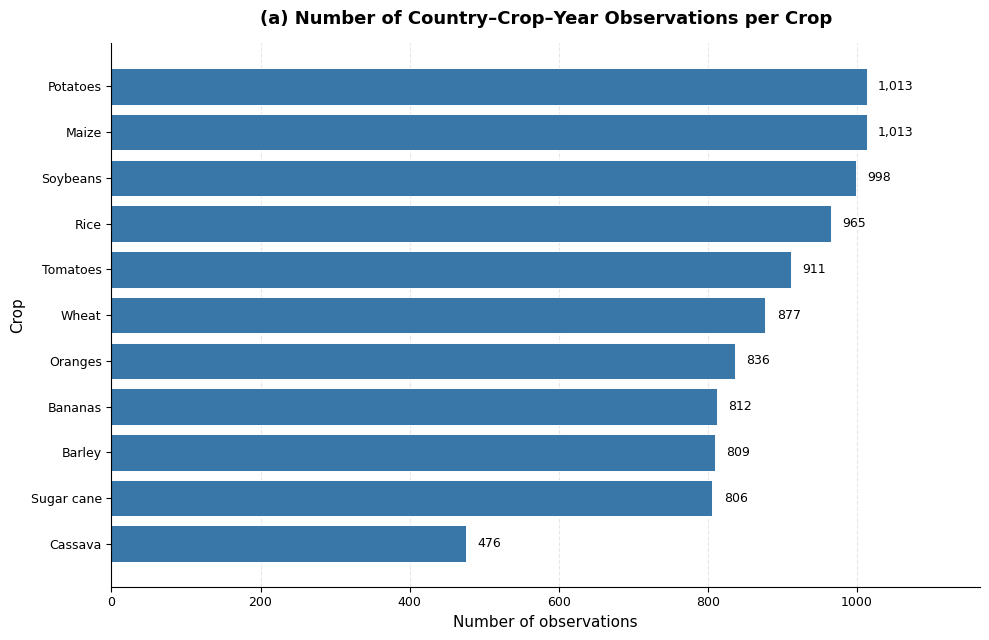

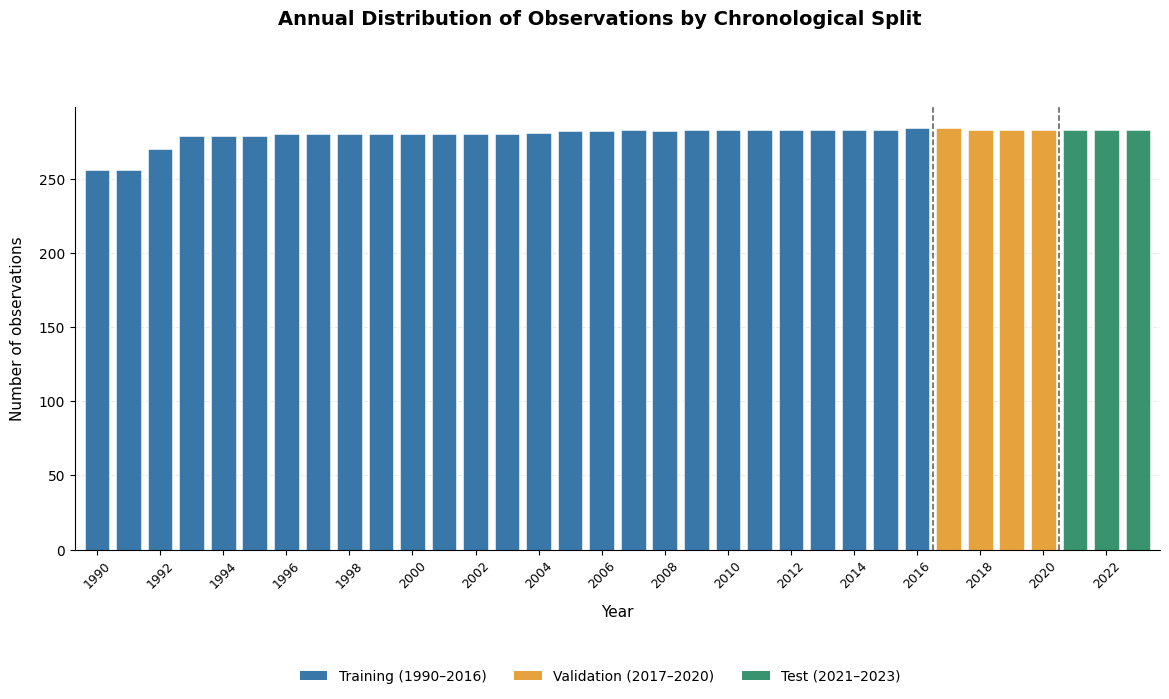


Figure (a): observations per crop


,Number_of_Observations
Crop,
Maize,1013
Potatoes,1013
Soybeans,998
Rice,965
Tomatoes,911
Wheat,877
Oranges,836
Bananas,812
Barley,809


Figure (b): Observations per chronological split


,Observations,First_Year,Last_Year
Chronological_Split,,,
Training (1990–2016),7534,1990,2016
Validation (2017–2020),1133,2017,2020
Test (2021–2023),849,2021,2023



Figures saved in: /content/thesis_figures
PNG files: 300 DPI; PDF files: publication-quality vector output.


In [147]:

# ============================================================
# CELL 134: DATASET COMPOSITION — TWO SEPARATE FIGURES
# Figure (a): Country–crop–year observations per crop
# Figure (b): Annual observations by chronological split
# ============================================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

# ------------------------------------------------------------
# 1. Select the existing dataframe from your previous cells
# ------------------------------------------------------------
if 'model_df_K2O' in globals():
    df_plot = model_df_K2O.copy()
elif 'model_df' in globals():
    df_plot = model_df.copy()
else:
    raise NameError(
        "Neither model_df_K2O nor model_df exists. "
        "Run your previous dataset-cleaning cells first."
    )

# Check required columns
required_columns = ['Country', 'Crop', 'Year']
missing_columns = [c for c in required_columns if c not in df_plot.columns]

if missing_columns:
    raise ValueError(f"Missing required columns: {missing_columns}")

# Clean plotting columns without modifying the original dataframe
df_plot['Year'] = pd.to_numeric(df_plot['Year'], errors='coerce')
df_plot = df_plot.dropna(subset=['Country', 'Crop', 'Year']).copy()
df_plot['Year'] = df_plot['Year'].astype(int)

# Confirm the dataset represents country–crop–year observations
duplicate_count = df_plot.duplicated(
    subset=['Country', 'Crop', 'Year']
).sum()

print("Dataset composition")
print("-------------------")
print(f"Observations available: {len(df_plot):,}")
print(f"Unique countries: {df_plot['Country'].nunique():,}")
print(f"Unique crops: {df_plot['Crop'].nunique():,}")
print(f"Year range: {df_plot['Year'].min()}–{df_plot['Year'].max()}")
print(f"Duplicate country–crop–year rows: {duplicate_count:,}")

if duplicate_count > 0:
    print(
        "Warning: duplicate country–crop–year combinations exist. "
        "Counts below represent rows, not unique combinations."
    )

# Output directory
output_dir = Path("thesis_figures")
output_dir.mkdir(exist_ok=True)


# ============================================================
# FIGURE (a): NUMBER OF OBSERVATIONS PER CROP
# ============================================================

crop_counts = (
    df_plot.groupby('Crop')
    .size()
    .sort_values(ascending=True)
)

fig, ax = plt.subplots(figsize=(10, 6.5))

bars = ax.barh(
    crop_counts.index,
    crop_counts.values,
    color='#3977A8',
    edgecolor='white',
    linewidth=0.7
)

# Put values just outside the bars
max_count = crop_counts.max()
ax.set_xlim(0, max_count * 1.15)

for bar, value in zip(bars, crop_counts.values):
    ax.text(
        bar.get_width() + max_count * 0.015,
        bar.get_y() + bar.get_height() / 2,
        f'{value:,}',
        va='center',
        ha='left',
        fontsize=9
    )

ax.set_title(
    '(a) Number of Country–Crop–Year Observations per Crop',
    fontsize=13,
    fontweight='bold',
    pad=14
)
ax.set_xlabel('Number of observations', fontsize=11)
ax.set_ylabel('Crop', fontsize=11)

ax.grid(axis='x', linestyle='--', alpha=0.3)
ax.set_axisbelow(True)
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)

fig.tight_layout()

fig.savefig(
    output_dir / 'Figure_134a_Observations_Per_Crop.png',
    dpi=300,
    bbox_inches='tight',
    facecolor='white'
)
fig.savefig(
    output_dir / 'Figure_134a_Observations_Per_Crop.pdf',
    bbox_inches='tight',
    facecolor='white'
)

plt.show()
plt.close(fig)



# ============================================================
# FIGURE 3.1(b): ANNUAL OBSERVATIONS BY CHRONOLOGICAL SPLIT
# Separate title, legend, and plot area to prevent overlap
# ============================================================

import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Patch
from pathlib import Path

# Use the existing df_plot and annual_counts from Cell 134
# If they are unavailable, recreate them from the selected dataframe.

if 'df_plot' not in globals():
    if 'model_df_K2O' in globals():
        df_plot = model_df_K2O.copy()
    elif 'model_df' in globals():
        df_plot = model_df.copy()
    else:
        raise NameError("Run the dataset-cleaning cells first.")

df_plot['Year'] = df_plot['Year'].astype(int)

annual_counts = (
    df_plot.groupby('Year')
    .size()
    .reindex(range(1990, 2024), fill_value=0)
)

def get_split(year):
    if 1990 <= year <= 2016:
        return 'Training (1990–2016)'
    elif 2017 <= year <= 2020:
        return 'Validation (2017–2020)'
    elif 2021 <= year <= 2023:
        return 'Test (2021–2023)'

split_colors = {
    'Training (1990–2016)': '#3977A8',
    'Validation (2017–2020)': '#E6A23C',
    'Test (2021–2023)': '#3A936F'
}

years = annual_counts.index.to_numpy()
values = annual_counts.to_numpy()
colors = [split_colors[get_split(y)] for y in years]

# Extra vertical space reserved for title and legend
fig, ax = plt.subplots(figsize=(14, 7.5))
fig.subplots_adjust(top=0.84, bottom=0.25)

# Bars
ax.bar(
    years,
    values,
    width=0.78,
    color=colors,
    edgecolor='white',
    linewidth=0.4
)

# Split boundaries
ax.axvline(2016.5, color='black', linestyle='--',
           linewidth=1.1, alpha=0.65)
ax.axvline(2020.5, color='black', linestyle='--',
           linewidth=1.1, alpha=0.65)

# Title positioned independently from the axes
fig.suptitle(
    'Annual Distribution of Observations by Chronological Split',
    fontsize=14,
    fontweight='bold',
    y=0.97
)

ax.set_xlabel('Year', fontsize=11, labelpad=10)
ax.set_ylabel('Number of observations', fontsize=11, labelpad=10)

ax.set_xticks(np.arange(1990, 2024, 2))
ax.tick_params(axis='x', labelrotation=45, labelsize=9)
ax.tick_params(axis='y', labelsize=10)

# Legend outside the plotting area, below the x-axis
legend_handles = [
    Patch(facecolor=split_colors[label], label=label)
    for label in [
        'Training (1990–2016)',
        'Validation (2017–2020)',
        'Test (2021–2023)'
    ]
]

fig.legend(
    handles=legend_handles,
    loc='lower center',
    bbox_to_anchor=(0.5, 0.055),
    ncol=3,
    frameon=False,
    fontsize=10
)

ax.grid(axis='y', linestyle='--', alpha=0.25)
ax.set_axisbelow(True)
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
ax.set_xlim(1989.3, 2023.7)

# Save with enough padding for all labels
output_dir = Path('thesis_figures')
output_dir.mkdir(exist_ok=True)

fig.savefig(
    output_dir / 'Figure_134b_Annual_Observations_By_Split.png',
    dpi=300,
    bbox_inches='tight',
    pad_inches=0.3,
    facecolor='white'
)

fig.savefig(
    output_dir / 'Figure_134b_Annual_Observations_By_Split.pdf',
    bbox_inches='tight',
    pad_inches=0.3,
    facecolor='white'
)

plt.show()
plt.close(fig)



# ============================================================
# SUMMARY TABLES FOR VERIFICATION
# ============================================================

print("\nFigure (a): observations per crop")
display(
    crop_counts.sort_values(ascending=False)
    .rename('Number_of_Observations')
    .to_frame()
)


# ============================================================
# FIX: FIGURE (b) CHRONOLOGICAL SPLIT SUMMARY
# ============================================================

# Ensure Year is numeric
df_plot['Year'] = pd.to_numeric(df_plot['Year'], errors='coerce')
df_plot = df_plot.dropna(subset=['Year']).copy()
df_plot['Year'] = df_plot['Year'].astype(int)

# Create the missing split column
def assign_split(year):
    if 1990 <= year <= 2016:
        return 'Training (1990–2016)'
    elif 2017 <= year <= 2020:
        return 'Validation (2017–2020)'
    elif 2021 <= year <= 2023:
        return 'Test (2021–2023)'
    else:
        return 'Outside defined split'

df_plot['Chronological_Split'] = df_plot['Year'].apply(assign_split)

# Generate summary table
split_summary = (
    df_plot.groupby('Chronological_Split')
    .agg(
        Observations=('Year', 'size'),
        First_Year=('Year', 'min'),
        Last_Year=('Year', 'max')
    )
)

# Display splits in the correct chronological order
split_order = [
    'Training (1990–2016)',
    'Validation (2017–2020)',
    'Test (2021–2023)',
    'Outside defined split'
]

split_summary = split_summary.reindex(
    [s for s in split_order if s in split_summary.index]
)

print("Figure (b): Observations per chronological split")
display(split_summary)


print(f"\nFigures saved in: {output_dir.resolve()}")
print("PNG files: 300 DPI; PDF files: publication-quality vector output.")


Crop order (lowest to highest median):


,Median_Carbon_Footprint_kgCO2e_per_tonne
Crop,
Potatoes,193.200
Oranges,214.500
Bananas,385.251
Barley,708.000
Soybeans,770.000
Wheat,816.400
Cassava,858.000
Maize,1207.000
Tomatoes,1358.500


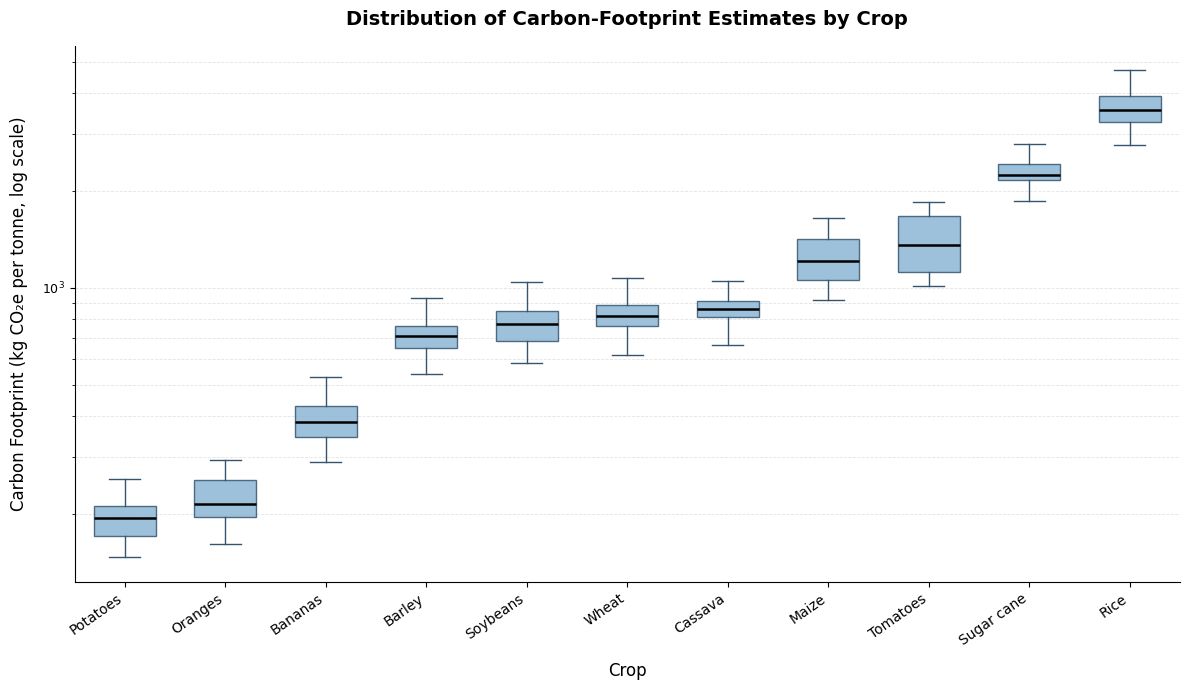


Figures saved in: /content/thesis_figures


In [150]:

# ============================================================
# CELL 135: DISTRIBUTION OF CARBON FOOTPRINT BY CROP
# Box plots ordered by median, logarithmic y-axis
# ============================================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

# ------------------------------------------------------------
# 1. Use the existing cleaned dataset
# ------------------------------------------------------------
if 'model_df_K2O' in globals():
    df_box = model_df_K2O.copy()
elif 'model_df' in globals():
    df_box = model_df.copy()
else:
    raise NameError(
        "Run the previous data-cleaning cells first. "
        "Expected model_df_K2O or model_df."
    )

target_col = 'Carbon_Footprint_kgCO2e_per_tonne'

if 'Crop' not in df_box.columns or target_col not in df_box.columns:
    raise ValueError(
        f"Required columns: Crop and {target_col}"
    )

df_box[target_col] = pd.to_numeric(
    df_box[target_col], errors='coerce'
)

# Log scale requires positive target values
df_box = df_box.dropna(subset=['Crop', target_col]).copy()
df_box = df_box[df_box[target_col] > 0].copy()

if df_box.empty:
    raise ValueError("No positive carbon-footprint target values found.")

# ------------------------------------------------------------
# 2. Order crops by ascending median carbon footprint
# ------------------------------------------------------------
crop_medians = (
    df_box.groupby('Crop')[target_col]
    .median()
    .sort_values(ascending=True)
)

crop_order = crop_medians.index.tolist()

box_data = [
    df_box.loc[df_box['Crop'] == crop, target_col].values
    for crop in crop_order
]

print("Crop order (lowest to highest median):")
display(
    crop_medians.rename(
        'Median_Carbon_Footprint_kgCO2e_per_tonne'
    ).to_frame()
)

# ------------------------------------------------------------
# 3. Create the box plot
# ------------------------------------------------------------
fig, ax = plt.subplots(figsize=(12, 7))

bp = ax.boxplot(
    box_data,
    patch_artist=True,
    showfliers=False,  # Avoid extreme points overcrowding the plot
    widths=0.62,
    medianprops=dict(color='black', linewidth=1.8),
    boxprops=dict(edgecolor='#35556F', linewidth=1.0),
    whiskerprops=dict(color='#35556F', linewidth=1.0),
    capprops=dict(color='#35556F', linewidth=1.0)
)

# Consistent box colour
for box in bp['boxes']:
    box.set_facecolor('#8DB7D5')
    box.set_alpha(0.85)

# Crop labels on the x-axis
ax.set_xticks(range(1, len(crop_order) + 1))
ax.set_xticklabels(
    crop_order,
    rotation=35,
    ha='right',
    fontsize=10
)

# Logarithmic target axis
ax.set_yscale('log')

ax.set_xlabel('Crop', fontsize=12, labelpad=10)
ax.set_ylabel(
    'Carbon Footprint (kg CO₂e per tonne, log scale)',
    fontsize=12,
    labelpad=10
)

ax.set_title(
    'Distribution of Carbon-Footprint Estimates by Crop',
    fontsize=14,
    fontweight='bold',
    pad=15
)

ax.grid(
    axis='y',
    which='both',
    linestyle='--',
    linewidth=0.6,
    alpha=0.35
)

ax.set_axisbelow(True)
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)

fig.tight_layout()

# ------------------------------------------------------------
# 4. Save publication-quality outputs
# ------------------------------------------------------------
output_dir = Path('thesis_figures')
output_dir.mkdir(exist_ok=True)

fig.savefig(
    output_dir / 'Figure_135_Carbon_Footprint_Distribution_By_Crop.png',
    dpi=300,
    bbox_inches='tight',
    facecolor='white'
)

fig.savefig(
    output_dir / 'Figure_135_Carbon_Footprint_Distribution_By_Crop.pdf',
    bbox_inches='tight',
    facecolor='white'
)

plt.show()
plt.close(fig)

print(f"\nFigures saved in: {output_dir.resolve()}")


Rows in selected cohort: 9,516
Rows with all selected variables available: 9,358

Spearman correlations with the carbon-footprint target:


,Spearman_rho
Growing_Season_Temperature_C,0.234417
Area_Harvested_ha_Derived,0.212251
Production_tonnes,0.177806
Growing_Season_Solar_Radiation,0.129369
Yield_t_per_ha,-0.112041
National_P2O5_Fertilizer_Use_tonnes,-0.102983
National_K2O_Fertilizer_Use_tonnes,-0.096832
National_N_Fertilizer_Use_tonnes,-0.095778
Growing_Season_Rainfall_mm,0.080421
Year,-0.056290


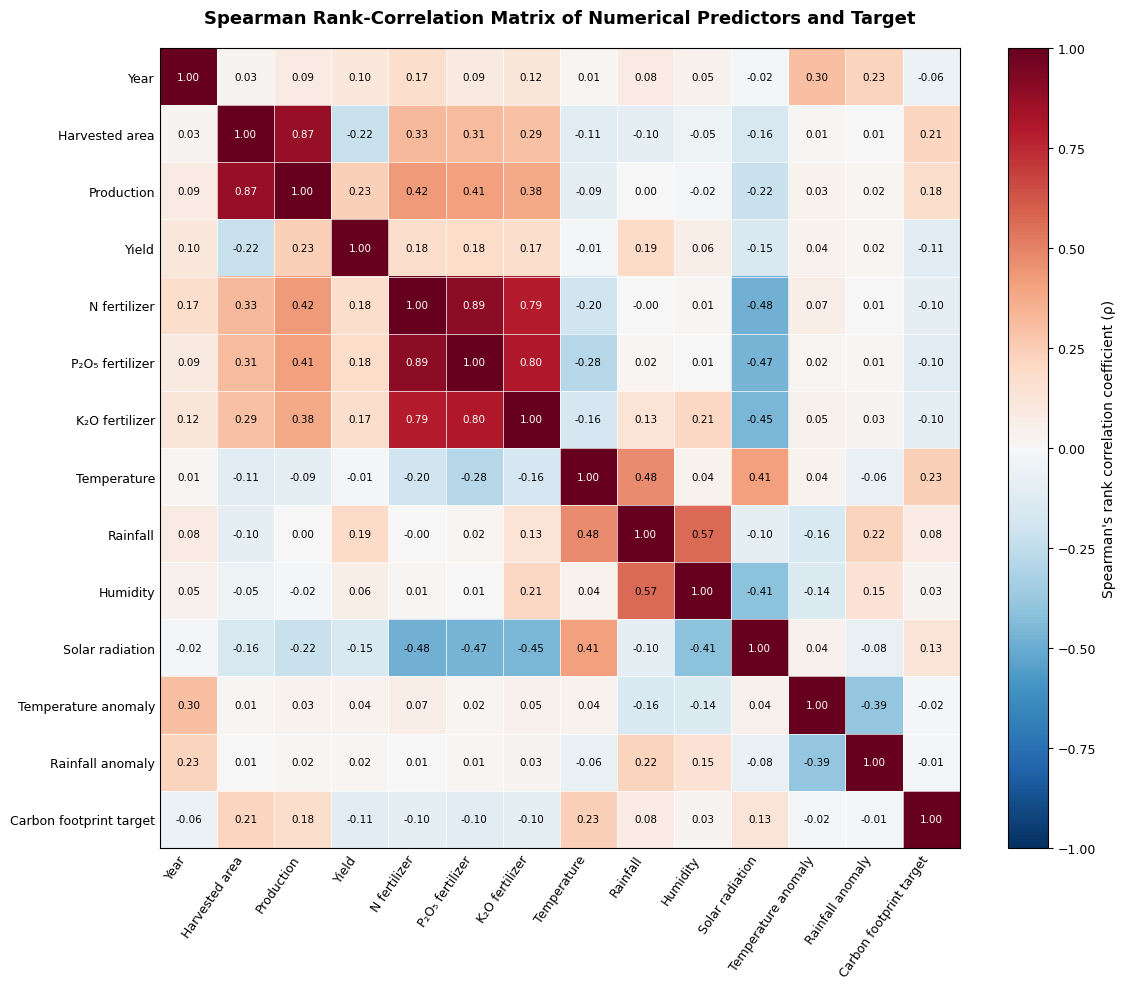


Outputs saved to: /content/thesis_figures
Method: Spearman rank correlation only.


In [151]:

# ============================================================
# CELL 136: SPEARMAN RANK-CORRELATION MATRIX
# 9,516-row cohort | Numerical predictors + target
# Spearman only — no Pearson correlation
# ============================================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

# ------------------------------------------------------------
# 1. Load the intended 9,516-row cohort
# ------------------------------------------------------------
if 'model_df' in globals() and len(model_df) == 9516:
    df_corr = model_df.copy()
elif 'df_plot' in globals() and len(df_plot) == 9516:
    df_corr = df_plot.copy()
else:
    raise ValueError(
        "Could not find the expected 9,516-row model_df cohort. "
        "Please run the earlier cleaning cells and check len(model_df). "
        "Do not substitute the 9,358-row complete-K2O cohort."
    )

target_col = 'Carbon_Footprint_kgCO2e_per_tonne'

# Numerical predictors used in the primary model
numeric_features = [
    'Year',
    'Area_Harvested_ha_Derived',
    'Production_tonnes',
    'Yield_t_per_ha',
    'National_N_Fertilizer_Use_tonnes',
    'National_P2O5_Fertilizer_Use_tonnes',
    'National_K2O_Fertilizer_Use_tonnes',
    'Growing_Season_Temperature_C',
    'Growing_Season_Rainfall_mm',
    'Growing_Season_Humidity_pct',
    'Growing_Season_Solar_Radiation',
    'Temperature_Anomaly',
    'Rainfall_Anomaly'
]

required_cols = numeric_features + [target_col]
missing_cols = [c for c in required_cols if c not in df_corr.columns]

if missing_cols:
    raise ValueError(f"Missing columns in dataframe: {missing_cols}")

# Convert selected variables to numeric without changing the source dataframe
corr_data = df_corr[required_cols].apply(
    pd.to_numeric, errors='coerce'
)

# Confirm the intended cohort size
print(f"Rows in selected cohort: {len(df_corr):,}")
print(f"Rows with all selected variables available: "
      f"{corr_data.dropna().shape[0]:,}")

# ------------------------------------------------------------
# 2. Calculate Spearman correlation ONLY
# ------------------------------------------------------------
spearman_corr = corr_data.corr(
    method='spearman',
    min_periods=2
)

# Check target correlations
print("\nSpearman correlations with the carbon-footprint target:")
display(
    spearman_corr[target_col]
    .drop(target_col)
    .sort_values(key=lambda s: s.abs(), ascending=False)
    .rename('Spearman_rho')
    .to_frame()
)

# ------------------------------------------------------------
# 3. Draw the correlation heatmap
# ------------------------------------------------------------
labels = {
    'Year': 'Year',
    'Area_Harvested_ha_Derived': 'Harvested area',
    'Production_tonnes': 'Production',
    'Yield_t_per_ha': 'Yield',
    'National_N_Fertilizer_Use_tonnes': 'N fertilizer',
    'National_P2O5_Fertilizer_Use_tonnes': 'P₂O₅ fertilizer',
    'National_K2O_Fertilizer_Use_tonnes': 'K₂O fertilizer',
    'Growing_Season_Temperature_C': 'Temperature',
    'Growing_Season_Rainfall_mm': 'Rainfall',
    'Growing_Season_Humidity_pct': 'Humidity',
    'Growing_Season_Solar_Radiation': 'Solar radiation',
    'Temperature_Anomaly': 'Temperature anomaly',
    'Rainfall_Anomaly': 'Rainfall anomaly',
    'Carbon_Footprint_kgCO2e_per_tonne': 'Carbon footprint target'
}

plot_corr = spearman_corr.rename(
    index=labels, columns=labels
)

n_vars = len(plot_corr)

fig, ax = plt.subplots(figsize=(13, 10))

im = ax.imshow(
    plot_corr.values,
    cmap='RdBu_r',
    vmin=-1,
    vmax=1,
    aspect='equal',
    interpolation='nearest'
)

# Axis labels
ax.set_xticks(np.arange(n_vars))
ax.set_yticks(np.arange(n_vars))

ax.set_xticklabels(
    plot_corr.columns,
    rotation=55,
    ha='right',
    fontsize=9
)
ax.set_yticklabels(
    plot_corr.index,
    fontsize=9
)

# Annotate correlation coefficients
for i in range(n_vars):
    for j in range(n_vars):
        value = plot_corr.iloc[i, j]

        if pd.notna(value):
            text_color = 'white' if abs(value) >= 0.65 else 'black'
            ax.text(
                j, i, f'{value:.2f}',
                ha='center',
                va='center',
                fontsize=7.5,
                color=text_color
            )

# Colour bar
cbar = fig.colorbar(im, ax=ax, fraction=0.035, pad=0.04)
cbar.set_label("Spearman's rank correlation coefficient (ρ)", fontsize=10)

ax.set_title(
    "Spearman Rank-Correlation Matrix of Numerical Predictors and Target",
    fontsize=13,
    fontweight='bold',
    pad=18
)

ax.tick_params(length=0)

# Thin grid separating matrix cells
ax.set_xticks(np.arange(-0.5, n_vars, 1), minor=True)
ax.set_yticks(np.arange(-0.5, n_vars, 1), minor=True)
ax.grid(which='minor', color='white', linestyle='-', linewidth=0.5)
ax.tick_params(which='minor', bottom=False, left=False)

fig.tight_layout()

# ------------------------------------------------------------
# 4. Save high-resolution thesis figures and matrix
# ------------------------------------------------------------
output_dir = Path('thesis_figures')
output_dir.mkdir(exist_ok=True)

fig.savefig(
    output_dir / 'Figure_136_Spearman_Correlation_Matrix.png',
    dpi=300,
    bbox_inches='tight',
    facecolor='white'
)

fig.savefig(
    output_dir / 'Figure_136_Spearman_Correlation_Matrix.pdf',
    bbox_inches='tight',
    facecolor='white'
)

# Save numerical matrix for reporting/reproducibility
spearman_corr.to_csv(
    output_dir / 'Table_136_Spearman_Correlation_Matrix.csv',
    index=True
)

plt.show()
plt.close(fig)

print(f"\nOutputs saved to: {output_dir.resolve()}")
print("Method: Spearman rank correlation only.")


Model comparison results:


,Model,Validation_MAE,Validation_RMSE,Validation_R2,Test_MAE,Test_RMSE,Test_R2
0,XGBoost,11.5293,21.6397,0.9995,12.7590,22.5990,0.9995
1,LightGBM,17.2571,28.7160,0.9991,18.0147,30.0372,0.9991
2,CatBoost,19.6678,32.7361,0.9989,20.3625,33.6723,0.9988
3,Gradient Boosting,23.2592,34.5371,0.9988,24.0474,36.7708,0.9986
4,Random Forest,42.9577,64.5645,0.9957,54.2084,78.2804,0.9936
5,Ridge,98.0828,134.7739,0.9811,98.1273,135.4838,0.9808


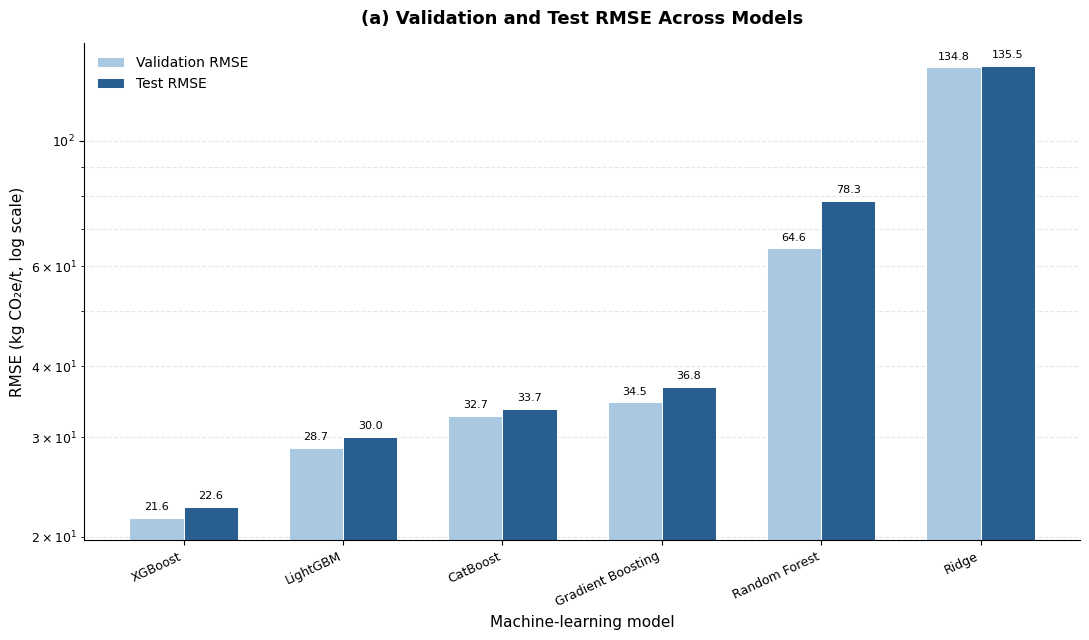

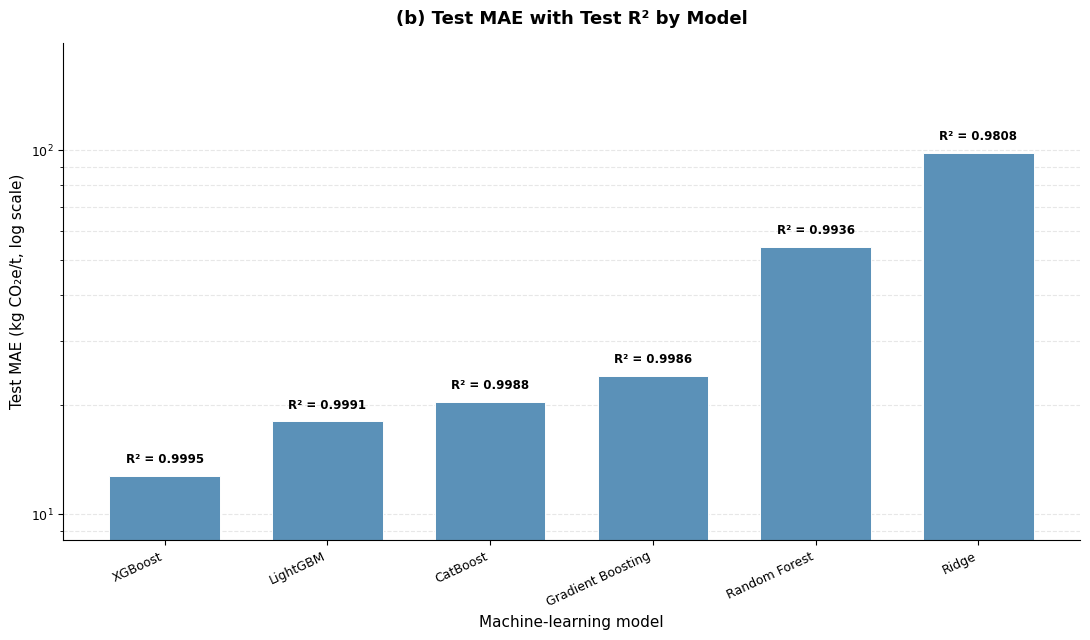


Both figures saved in: /content/thesis_figures
Formats: PNG (300 DPI) and PDF.


In [155]:

# ============================================================
# CELL 137: MODEL COMPARISON — TWO SEPARATE FIGURES
# (a) Validation vs Test RMSE (log scale)
# (b) Test MAE with R² annotations (log scale)
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

# ------------------------------------------------------------
# 1. Previously obtained model-comparison results
# ------------------------------------------------------------
results = pd.DataFrame({
    'Model': [
        'Ridge',
        'Random Forest',
        'Gradient Boosting',
        'XGBoost',
        'LightGBM',
        'CatBoost'
    ],
    'Validation_MAE': [
        98.0828, 42.9577, 23.2592,
        11.5293, 17.2571, 19.6678
    ],
    'Validation_RMSE': [
        134.7739, 64.5645, 34.5371,
        21.6397, 28.7160, 32.7361
    ],
    'Validation_R2': [
        0.9811, 0.9957, 0.9988,
        0.9995, 0.9991, 0.9989
    ],
    'Test_MAE': [
        98.1273, 54.2084, 24.0474,
        12.7590, 18.0147, 20.3625
    ],
    'Test_RMSE': [
        135.4838, 78.2804, 36.7708,
        22.5990, 30.0372, 33.6723
    ],
    'Test_R2': [
        0.9808, 0.9936, 0.9986,
        0.9995, 0.9991, 0.9988
    ]
})

# Sort models by test RMSE, best first
results = results.sort_values(
    'Test_RMSE', ascending=True
).reset_index(drop=True)

print("Model comparison results:")
display(results.round(4))

output_dir = Path('thesis_figures')
output_dir.mkdir(exist_ok=True)

# ------------------------------------------------------------
# FIGURE (a): VALIDATION AND TEST RMSE
# ------------------------------------------------------------
fig, ax = plt.subplots(figsize=(11, 6.5))

x = np.arange(len(results))
width = 0.34

# Light = validation; dark = test
bars_val = ax.bar(
    x - width / 2,
    results['Validation_RMSE'],
    width,
    label='Validation RMSE',
    color='#A9C8E2',
    edgecolor='white',
    linewidth=0.7
)

bars_test = ax.bar(
    x + width / 2,
    results['Test_RMSE'],
    width,
    label='Test RMSE',
    color='#285F8F',
    edgecolor='white',
    linewidth=0.7
)

ax.set_yscale('log')

ax.set_xticks(x)
ax.set_xticklabels(results['Model'], rotation=25, ha='right')

ax.set_xlabel('Machine-learning model', fontsize=11)
ax.set_ylabel('RMSE (kg CO₂e/t, log scale)', fontsize=11)
ax.set_title(
    '(a) Validation and Test RMSE Across Models',
    fontsize=13,
    fontweight='bold',
    pad=14
)

ax.legend(
    loc='upper left',
    frameon=False,
    fontsize=10
)

ax.grid(axis='y', which='both', linestyle='--', alpha=0.3)
ax.set_axisbelow(True)
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)

# Numeric labels above bars
for bars in [bars_val, bars_test]:
    for bar in bars:
        height = bar.get_height()
        ax.annotate(
            f'{height:.1f}',
            xy=(bar.get_x() + bar.get_width() / 2, height),
            xytext=(0, 4),
            textcoords='offset points',
            ha='center',
            va='bottom',
            fontsize=8
        )

fig.tight_layout()

fig.savefig(
    output_dir / 'Figure_137a_Validation_Test_RMSE.png',
    dpi=300,
    bbox_inches='tight',
    facecolor='white'
)
fig.savefig(
    output_dir / 'Figure_137a_Validation_Test_RMSE.pdf',
    bbox_inches='tight',
    facecolor='white'
)

plt.show()
plt.close(fig)


# ------------------------------------------------------------
# FIGURE (b): TEST MAE WITH TEST R² ANNOTATIONS
# ------------------------------------------------------------
fig, ax = plt.subplots(figsize=(11, 6.5))

bars = ax.bar(
    results['Model'],
    results['Test_MAE'],
    color='#5B91B8',
    edgecolor='white',
    linewidth=0.7,
    width=0.68
)

ax.set_yscale('log')

ax.set_xlabel('Machine-learning model', fontsize=11)
ax.set_ylabel('Test MAE (kg CO₂e/t, log scale)', fontsize=11)
ax.set_title(
    '(b) Test MAE with Test R² by Model',
    fontsize=13,
    fontweight='bold',
    pad=14
)

ax.tick_params(axis='x', rotation=25)
for label in ax.get_xticklabels():
    label.set_horizontalalignment('right')

# Annotate each bar with test R², positioned above each bar.
# Log scale means vertical offsets are specified multiplicatively.
for bar, r2 in zip(bars, results['Test_R2']):
    height = bar.get_height()
    ax.annotate(
        f'R² = {r2:.4f}',
        xy=(bar.get_x() + bar.get_width() / 2, height),
        xytext=(0, 7),
        textcoords='offset points',
        ha='center',
        va='bottom',
        fontsize=8.5,
        fontweight='bold'
    )

# Leave sufficient headroom for the annotations
ax.set_ylim(
    results['Test_MAE'].min() / 1.5,
    results['Test_MAE'].max() * 2.0
)

ax.grid(axis='y', which='both', linestyle='--', alpha=0.3)
ax.set_axisbelow(True)
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)

fig.tight_layout()

fig.savefig(
    output_dir / 'Figure_137b_Test_MAE_R2.png',
    dpi=300,
    bbox_inches='tight',
    facecolor='white'
)
fig.savefig(
    output_dir / 'Figure_137b_Test_MAE_R2.pdf',
    bbox_inches='tight',
    facecolor='white'
)

plt.show()
plt.close(fig)

print(f"\nBoth figures saved in: {output_dir.resolve()}")
print("Formats: PNG (300 DPI) and PDF.")


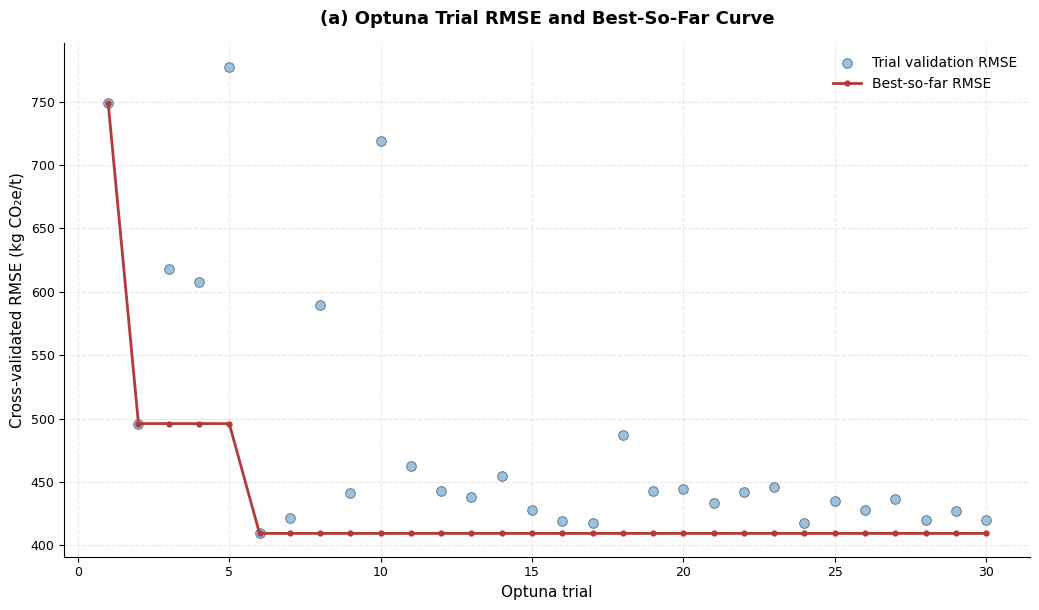

Optuna trials plotted: 30
Best objective value in recorded study: 409.4732


,Trial,RMSE,State,Best_So_Far
0,1,748.900876,TrialState.COMPLETE,748.900876
1,2,496.063490,TrialState.COMPLETE,496.063490
2,3,617.779582,TrialState.COMPLETE,496.063490
3,4,607.992088,TrialState.COMPLETE,496.063490
4,5,777.450144,TrialState.COMPLETE,496.063490
5,6,409.473182,TrialState.COMPLETE,409.473182
6,7,421.451488,TrialState.COMPLETE,409.473182
7,8,589.206508,TrialState.COMPLETE,409.473182
8,9,441.386544,TrialState.COMPLETE,409.473182
9,10,719.255113,TrialState.COMPLETE,409.473182


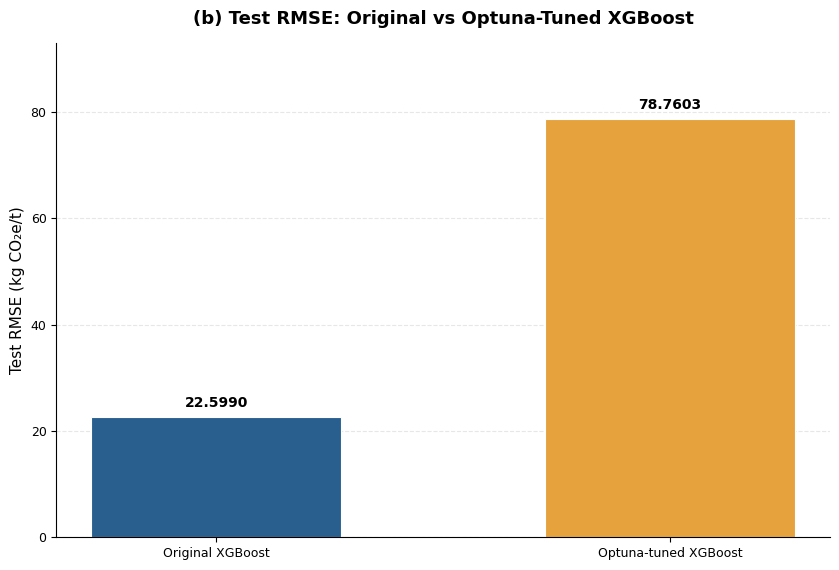


Test RMSE comparison:


,Model,Test_RMSE
0,Original XGBoost,22.5990
1,Optuna-tuned XGBoost,78.7603



Figures saved in: /content/thesis_figures


In [156]:

# ============================================================
# CELL 138: OPTUNA TRIALS AND MODEL COMPARISON
# (a) Trial RMSE and best-so-far curve
# (b) Original vs tuned model test RMSE
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

output_dir = Path("thesis_figures")
output_dir.mkdir(exist_ok=True)

# Previously reported results
ORIGINAL_TEST_RMSE = 22.5990
TUNED_TEST_RMSE = 78.7603

# ------------------------------------------------------------
# FIGURE (a): OPTUNA TRIAL RMSE AND BEST-SO-FAR CURVE
# ------------------------------------------------------------

# Search for an existing Optuna study in the notebook.
study_candidates = [
    name for name, obj in globals().items()
    if name.lower() in ['study', 'optuna_study', 'optimization_study']
    and hasattr(obj, 'trials')
]

study = globals()[study_candidates[0]] if study_candidates else None

if study is not None:
    trial_records = []

    for trial in study.trials:
        if trial.value is not None and np.isfinite(trial.value):
            trial_records.append({
                'Trial': trial.number + 1,
                'RMSE': float(trial.value),
                'State': str(trial.state)
            })

    trial_df = pd.DataFrame(trial_records)

    if trial_df.empty:
        raise ValueError(
            "The Optuna study exists, but no completed trials "
            "with valid objective values were found."
        )

    # Assumes the Optuna objective was RMSE, as in your tuning run.
    trial_df = trial_df.sort_values('Trial').reset_index(drop=True)
    trial_df['Best_So_Far'] = trial_df['RMSE'].cummin()

    fig, ax = plt.subplots(figsize=(10.5, 6.2))

    ax.scatter(
        trial_df['Trial'],
        trial_df['RMSE'],
        color='#8DB7D5',
        edgecolor='#35556F',
        linewidth=0.6,
        s=48,
        alpha=0.85,
        label='Trial validation RMSE',
        zorder=3
    )

    ax.plot(
        trial_df['Trial'],
        trial_df['Best_So_Far'],
        color='#B33A3A',
        linewidth=2.0,
        marker='o',
        markersize=3.5,
        label='Best-so-far RMSE',
        zorder=4
    )

    ax.set_xlabel('Optuna trial', fontsize=11)
    ax.set_ylabel('Cross-validated RMSE (kg CO₂e/t)', fontsize=11)
    ax.set_title(
        '(a) Optuna Trial RMSE and Best-So-Far Curve',
        fontsize=13,
        fontweight='bold',
        pad=14
    )

    ax.legend(frameon=False)
    ax.grid(axis='both', linestyle='--', alpha=0.3)
    ax.set_axisbelow(True)
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)

    fig.tight_layout()

    fig.savefig(
        output_dir / 'Figure_138a_Optuna_Trial_RMSE.png',
        dpi=300, bbox_inches='tight', facecolor='white'
    )
    fig.savefig(
        output_dir / 'Figure_138a_Optuna_Trial_RMSE.pdf',
        bbox_inches='tight', facecolor='white'
    )

    plt.show()
    plt.close(fig)

    print(f"Optuna trials plotted: {len(trial_df)}")
    print(f"Best objective value in recorded study: "
          f"{trial_df['RMSE'].min():.4f}")

    display(trial_df)

else:
    print(
        "No existing Optuna study object was found. "
        "Figure (a) was not generated because the actual per-trial "
        "RMSE values are needed. Do not fabricate trial values. "
        "If your study was saved, load it and rerun this cell."
    )


# ------------------------------------------------------------
# FIGURE (b): ORIGINAL VS TUNED MODEL TEST RMSE
# ------------------------------------------------------------

comparison = pd.DataFrame({
    'Model': [
        'Original XGBoost',
        'Optuna-tuned XGBoost'
    ],
    'Test_RMSE': [
        ORIGINAL_TEST_RMSE,
        TUNED_TEST_RMSE
    ]
})

fig, ax = plt.subplots(figsize=(8.5, 5.8))

bars = ax.bar(
    comparison['Model'],
    comparison['Test_RMSE'],
    color=['#285F8F', '#E6A23C'],
    edgecolor='white',
    linewidth=0.8,
    width=0.55
)

ax.set_ylabel('Test RMSE (kg CO₂e/t)', fontsize=11)
ax.set_title(
    '(b) Test RMSE: Original vs Optuna-Tuned XGBoost',
    fontsize=13,
    fontweight='bold',
    pad=14
)

# Linear scale makes the performance gap easy to interpret.
ax.set_ylim(0, TUNED_TEST_RMSE * 1.18)

for bar in bars:
    height = bar.get_height()
    ax.annotate(
        f'{height:.4f}',
        xy=(bar.get_x() + bar.get_width() / 2, height),
        xytext=(0, 5),
        textcoords='offset points',
        ha='center',
        va='bottom',
        fontsize=10,
        fontweight='bold'
    )

ax.grid(axis='y', linestyle='--', alpha=0.3)
ax.set_axisbelow(True)
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)

fig.tight_layout()

fig.savefig(
    output_dir / 'Figure_138b_Original_vs_Tuned_Test_RMSE.png',
    dpi=300, bbox_inches='tight', facecolor='white'
)
fig.savefig(
    output_dir / 'Figure_138b_Original_vs_Tuned_Test_RMSE.pdf',
    bbox_inches='tight', facecolor='white'
)

plt.show()
plt.close(fig)

print("\nTest RMSE comparison:")
display(comparison)

print(f"\nFigures saved in: {output_dir.resolve()}")


Ablation results:


,Experiment,Test_R2,Test_RMSE
0,M1: Production,0.1315,911.7252
1,M2: + Fertilizers,0.4295,738.9444
2,M3: + Climate,0.7605,478.8123
3,"M4: + Country, Crop, Year",0.9995,21.2300


Target-construction audit results:


,Experiment,Test_R2,Test_RMSE
0,Context only,0.9957,64.0231
1,Construction-linked only,0.6579,572.2127
2,Restricted features,0.9964,58.2960
3,Full feature set (M4),0.9995,21.2300


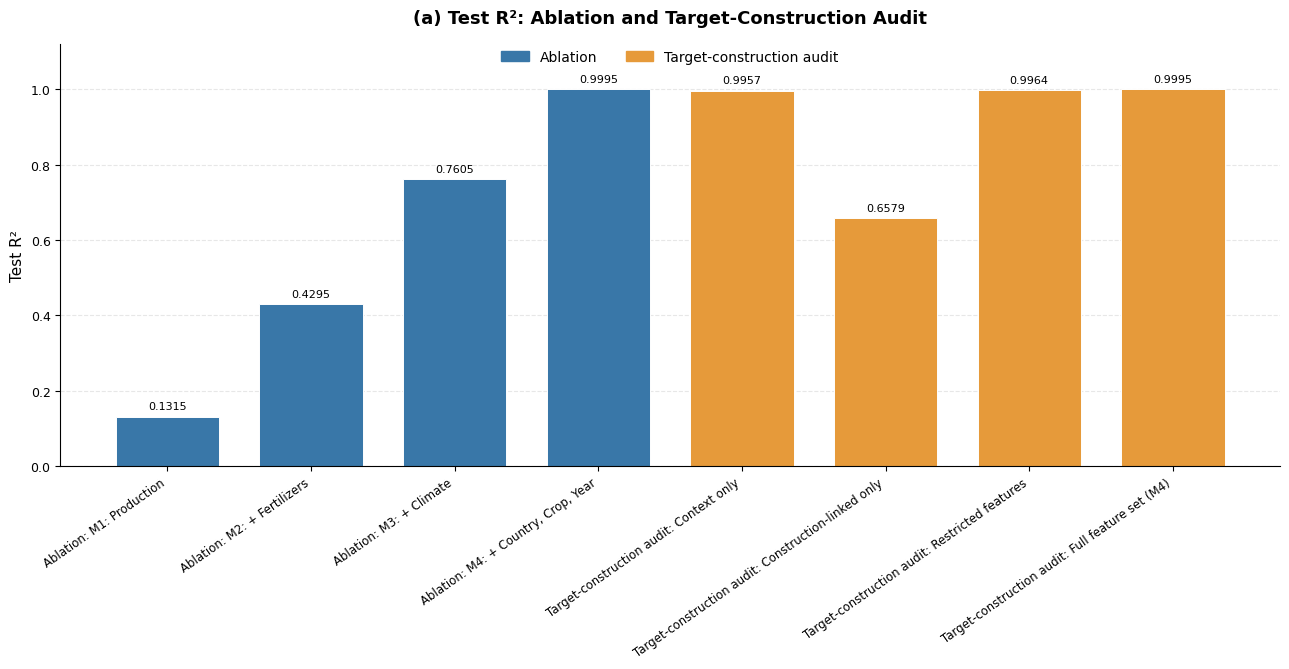

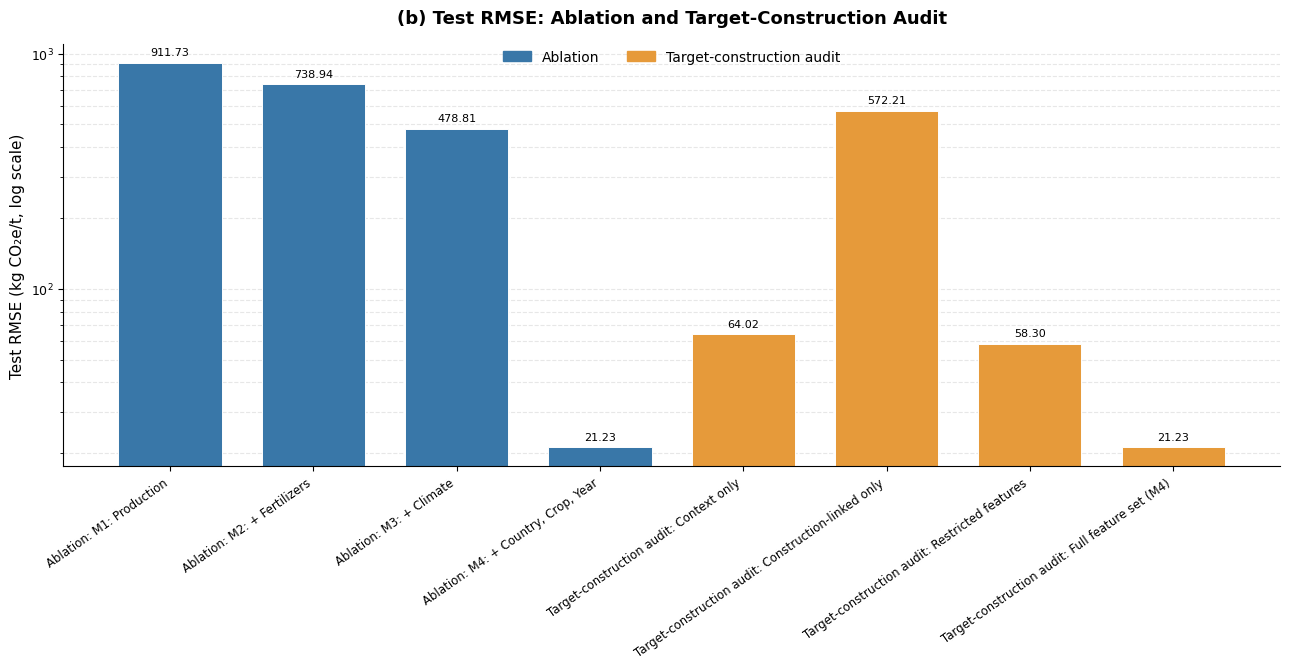


Both figures saved in: /content/thesis_figures
PNG: 300 DPI | PDF: publication-ready vector format


In [157]:

# ============================================================
# CELL 139: ABLATION AND TARGET-CONSTRUCTION AUDIT
# (a) Test R²
# (b) Test RMSE — logarithmic scale
# Blue = Ablation | Orange = Target-construction audit
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

output_dir = Path("thesis_figures")
output_dir.mkdir(exist_ok=True)

# ------------------------------------------------------------
# 1. Previously obtained test results
# ------------------------------------------------------------

# Ablation: progressively add predictor groups
ablation = pd.DataFrame({
    'Experiment': [
        'M1: Production',
        'M2: + Fertilizers',
        'M3: + Climate',
        'M4: + Country, Crop, Year'
    ],
    'Test_R2': [
        0.131468,
        0.429466,
        0.760454,
        0.999529
    ],
    'Test_RMSE': [
        911.7252,
        738.9444,
        478.8123,
        21.2300
    ]
})

# Target-construction audit: alternative feature groups
audit = pd.DataFrame({
    'Experiment': [
        'Context only',
        'Construction-linked only',
        'Restricted features',
        'Full feature set (M4)'
    ],
    'Test_R2': [
        0.995717,
        0.657884,
        0.996449,
        0.999529
    ],
    'Test_RMSE': [
        64.0231,
        572.2127,
        58.2960,
        21.2300
    ]
})

print("Ablation results:")
display(ablation.round(4))

print("Target-construction audit results:")
display(audit.round(4))

# ------------------------------------------------------------
# 2. Combine data for plotting
# ------------------------------------------------------------
plot_df = pd.concat([
    ablation.assign(Experiment_Type='Ablation'),
    audit.assign(Experiment_Type='Target-construction audit')
], ignore_index=True)

plot_df['Plot_Label'] = plot_df.apply(
    lambda row: (
        f"{row['Experiment_Type']}: {row['Experiment']}"
    ),
    axis=1
)

colors = {
    'Ablation': '#3977A8',                 # Blue
    'Target-construction audit': '#E69A3A' # Orange
}

bar_colors = plot_df['Experiment_Type'].map(colors).tolist()
x = np.arange(len(plot_df))
labels = plot_df['Plot_Label'].tolist()

# ------------------------------------------------------------
# FIGURE (a): TEST R²
# ------------------------------------------------------------
fig, ax = plt.subplots(figsize=(13, 6.8))

bars = ax.bar(
    x,
    plot_df['Test_R2'],
    color=bar_colors,
    edgecolor='white',
    linewidth=0.7,
    width=0.72
)

ax.set_xticks(x)
ax.set_xticklabels(
    labels,
    rotation=35,
    ha='right',
    fontsize=8.5
)

ax.set_ylabel('Test R²', fontsize=11)
ax.set_title(
    '(a) Test R²: Ablation and Target-Construction Audit',
    fontsize=13,
    fontweight='bold',
    pad=15
)

# All reported R² values fall within this range.
ax.set_ylim(0, 1.12)

# Label each bar without overlapping the plot
for bar, value in zip(bars, plot_df['Test_R2']):
    ax.annotate(
        f'{value:.4f}',
        xy=(bar.get_x() + bar.get_width() / 2, bar.get_height()),
        xytext=(0, 4),
        textcoords='offset points',
        ha='center',
        va='bottom',
        fontsize=8
    )

legend_handles = [
    plt.Rectangle((0, 0), 1, 1, color=colors['Ablation'],
                  label='Ablation'),
    plt.Rectangle((0, 0), 1, 1,
                  color=colors['Target-construction audit'],
                  label='Target-construction audit')
]

ax.legend(
    handles=legend_handles,
    loc='upper center',
    bbox_to_anchor=(0.5, 1.015),
    ncol=2,
    frameon=False
)

ax.grid(axis='y', linestyle='--', alpha=0.3)
ax.set_axisbelow(True)
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)

fig.tight_layout()

fig.savefig(
    output_dir / 'Figure_139a_Ablation_Audit_Test_R2.png',
    dpi=300, bbox_inches='tight', facecolor='white'
)
fig.savefig(
    output_dir / 'Figure_139a_Ablation_Audit_Test_R2.pdf',
    bbox_inches='tight', facecolor='white'
)

plt.show()
plt.close(fig)

# ------------------------------------------------------------
# FIGURE (b): TEST RMSE — LOGARITHMIC SCALE
# ------------------------------------------------------------
fig, ax = plt.subplots(figsize=(13, 6.8))

bars = ax.bar(
    x,
    plot_df['Test_RMSE'],
    color=bar_colors,
    edgecolor='white',
    linewidth=0.7,
    width=0.72
)

ax.set_yscale('log')

ax.set_xticks(x)
ax.set_xticklabels(
    labels,
    rotation=35,
    ha='right',
    fontsize=8.5
)

ax.set_ylabel('Test RMSE (kg CO₂e/t, log scale)', fontsize=11)
ax.set_title(
    '(b) Test RMSE: Ablation and Target-Construction Audit',
    fontsize=13,
    fontweight='bold',
    pad=15
)

# Annotate bars with RMSE values
for bar, value in zip(bars, plot_df['Test_RMSE']):
    ax.annotate(
        f'{value:.2f}',
        xy=(bar.get_x() + bar.get_width() / 2, value),
        xytext=(0, 4),
        textcoords='offset points',
        ha='center',
        va='bottom',
        fontsize=8
    )

ax.legend(
    handles=legend_handles,
    loc='upper center',
    bbox_to_anchor=(0.5, 1.015),
    ncol=2,
    frameon=False
)

ax.grid(axis='y', which='both', linestyle='--', alpha=0.3)
ax.set_axisbelow(True)
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)

fig.tight_layout()

fig.savefig(
    output_dir / 'Figure_139b_Ablation_Audit_Test_RMSE.png',
    dpi=300, bbox_inches='tight', facecolor='white'
)
fig.savefig(
    output_dir / 'Figure_139b_Ablation_Audit_Test_RMSE.pdf',
    bbox_inches='tight',
    facecolor='white'
)

plt.show()
plt.close(fig)

print(f"\nBoth figures saved in: {output_dir.resolve()}")
print("PNG: 300 DPI | PDF: publication-ready vector format")


In [162]:

# ------------------------------------------------------------
# FIX: Automatically retrieve crop reference intensities
# ------------------------------------------------------------

REFERENCE_INTENSITY = None
reference_column = 'Carbon_Reference_Intensity_kgCO2e_per_kg'

# Search existing dataframes in the notebook
for var_name, obj in list(globals().items()):
    if not isinstance(obj, pd.DataFrame):
        continue

    if (
        'Crop' in obj.columns
        and reference_column in obj.columns
    ):
        temp = obj[['Crop', reference_column]].copy()
        temp[reference_column] = pd.to_numeric(
            temp[reference_column], errors='coerce'
        )
        temp = temp.dropna(
            subset=['Crop', reference_column]
        )
        temp = temp[temp[reference_column] > 0]

        if not temp.empty:
            # Check whether each crop has a consistent reference value
            unique_counts = temp.groupby('Crop')[
                reference_column
            ].nunique()

            inconsistent = unique_counts[unique_counts > 1]

            if not inconsistent.empty:
                print(
                    f"Warning: inconsistent reference intensities "
                    f"in dataframe '{var_name}' for:",
                    inconsistent.index.tolist()
                )
                continue

            REFERENCE_INTENSITY = (
                temp.groupby('Crop')[reference_column]
                .first()
                .to_dict()
            )

            print(f"Reference intensities found in: {var_name}")
            break

if REFERENCE_INTENSITY is None:
    print("Available dataframes containing reference-intensity columns:")
    for var_name, obj in list(globals().items()):
        if isinstance(obj, pd.DataFrame):
            if reference_column in obj.columns:
                print(var_name, obj.shape, list(obj.columns))

    raise NameError(
        "Could not retrieve crop reference intensities. "
        "Check the original master dataset or target-construction cell."
    )

print("\nCrop reference intensities:")
display(
    pd.DataFrame(
        list(REFERENCE_INTENSITY.items()),
        columns=['Crop', 'Reference_Intensity_kgCO2e_per_kg']
    ).sort_values('Reference_Intensity_kgCO2e_per_kg')
)

print("\nCrop order: lowest to highest reference intensity")
print(
    sorted(
        REFERENCE_INTENSITY,
        key=lambda crop: REFERENCE_INTENSITY[crop]
    )
)


Reference intensities found in: df

Crop reference intensities:


,Crop,Reference_Intensity_kgCO2e_per_kg
4,Oranges,0.39
5,Potatoes,0.46
0,Bananas,0.86
7,Soybeans,1.10
1,Barley,1.18
2,Cassava,1.32
10,Wheat,1.57
3,Maize,1.70
9,Tomatoes,2.09
8,Sugar cane,3.20



Crop order: lowest to highest reference intensity
['Oranges', 'Potatoes', 'Bananas', 'Soybeans', 'Barley', 'Cassava', 'Wheat', 'Maize', 'Tomatoes', 'Sugar cane', 'Rice']


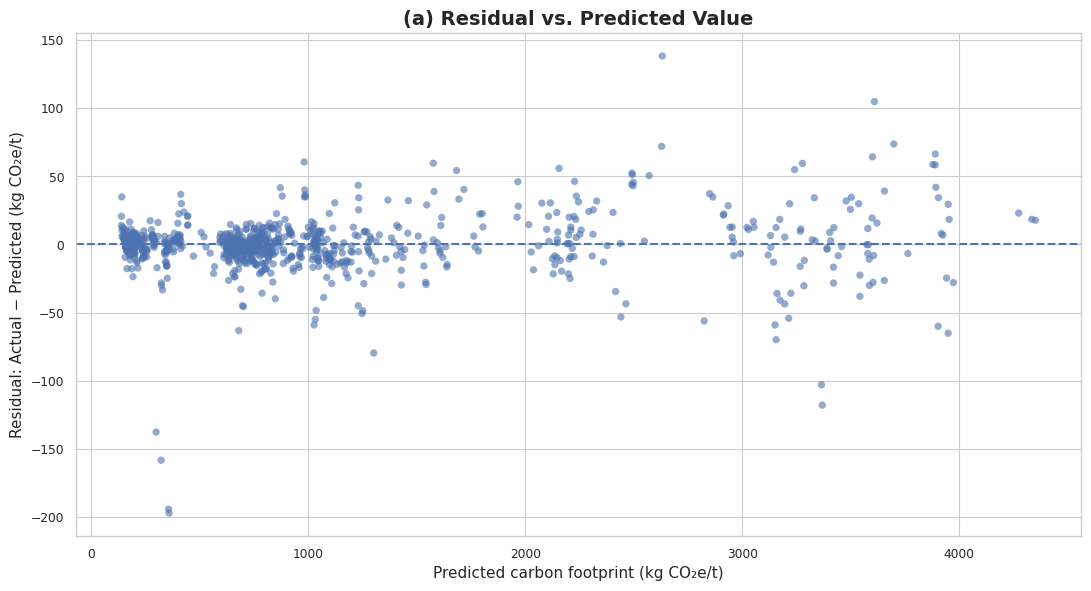

Figure (a) saved: /content/residual_diagnostic_figures/Figure_a_Residual_vs_Predicted.png


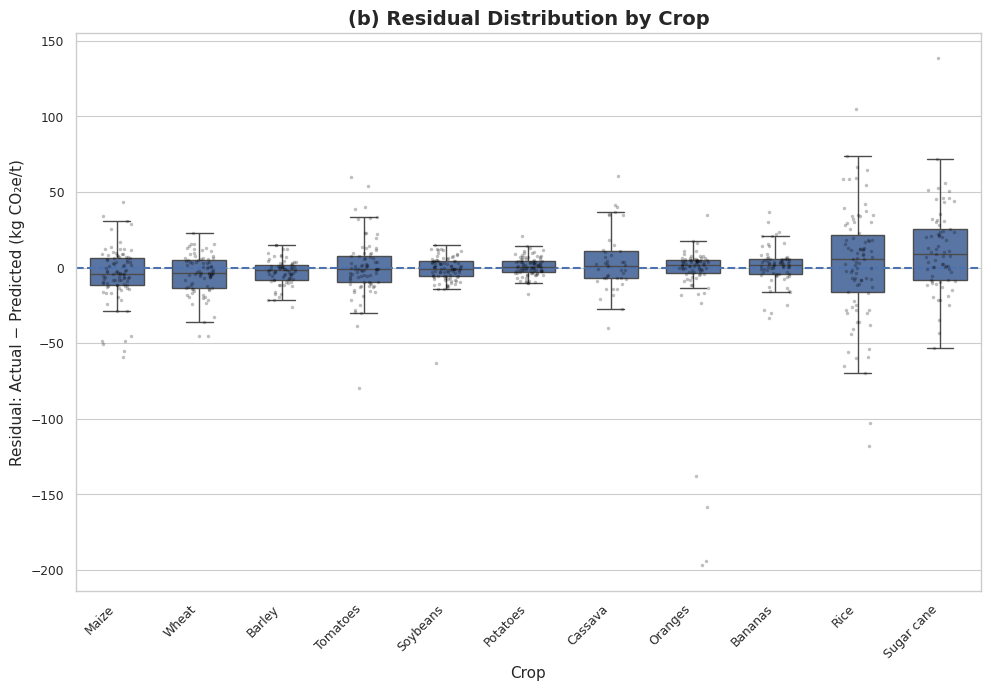

Figure (b) saved: /content/residual_diagnostic_figures/Figure_b_Residual_by_Crop.png


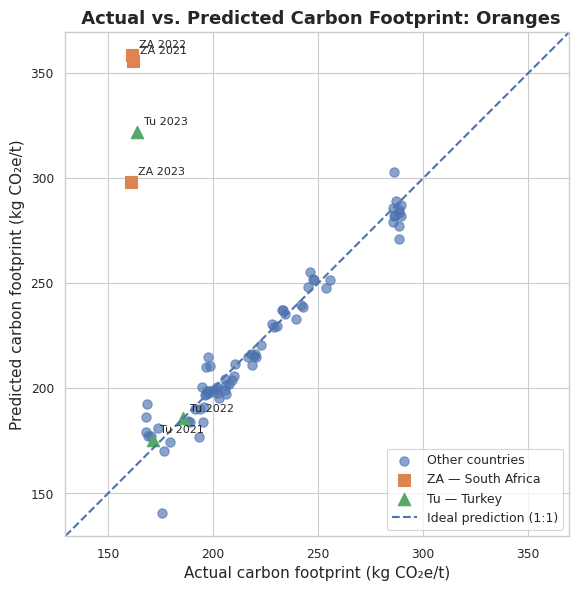

Figure (c) saved: /content/residual_diagnostic_figures/Figure_c_Orange_Actual_vs_Predicted.png

All three separate figures saved successfully:
/content/residual_diagnostic_figures/Figure_a_Residual_vs_Predicted.png
/content/residual_diagnostic_figures/Figure_b_Residual_by_Crop.png
/content/residual_diagnostic_figures/Figure_c_Orange_Actual_vs_Predicted.png


In [170]:

# ============================================================
# THREE SEPARATE RESIDUAL DIAGNOSTIC FIGURES
# (a) Residual vs Predicted
# (b) Residual by Crop
# (c) Actual vs Predicted for Oranges
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import os

# Output directory
output_dir = '/content/residual_diagnostic_figures'
os.makedirs(output_dir, exist_ok=True)

sns.set_theme(style='whitegrid', context='paper')

# Check the previous cell's output
if 'residual_df' not in globals():
    raise NameError(
        "residual_df not found. Run the previous residual diagnostics "
        "data-preparation code first."
    )

required = {'Actual', 'Predicted', 'Residual', 'Crop'}
missing = required - set(residual_df.columns)

if missing:
    raise KeyError(f"Missing columns in residual_df: {missing}")

# ------------------------------------------------------------
# FIGURE 1: RESIDUAL VS PREDICTED
# ------------------------------------------------------------

fig, ax = plt.subplots(figsize=(11, 6))

ax.scatter(
    residual_df['Predicted'],
    residual_df['Residual'],
    alpha=0.60,
    s=28,
    edgecolors='none'
)

ax.axhline(
    y=0,
    linestyle='--',
    linewidth=1.5
)

ax.set_title(
    '(a) Residual vs. Predicted Value',
    fontsize=14,
    fontweight='bold'
)

ax.set_xlabel(
    'Predicted carbon footprint (kg CO₂e/t)',
    fontsize=11
)
ax.set_ylabel(
    'Residual: Actual − Predicted (kg CO₂e/t)',
    fontsize=11
)

plt.tight_layout()

fig1_path = os.path.join(
    output_dir, 'Figure_a_Residual_vs_Predicted.png'
)

fig.savefig(fig1_path, dpi=300, bbox_inches='tight')
plt.show()
plt.close(fig)

print('Figure (a) saved:', fig1_path)


# ------------------------------------------------------------
# FIGURE 2: RESIDUAL DISTRIBUTION BY CROP
# ------------------------------------------------------------

crop_order = (
    residual_df.groupby('Crop')['Residual']
    .median()
    .sort_values()
    .index.tolist()
)

fig, ax = plt.subplots(figsize=(10, 7))

sns.boxplot(
    data=residual_df,
    x='Crop',
    y='Residual',
    order=crop_order,
    showfliers=False,
    width=0.65,
    ax=ax
)

sns.stripplot(
    data=residual_df,
    x='Crop',
    y='Residual',
    order=crop_order,
    color='black',
    alpha=0.25,
    size=2.5,
    jitter=0.18,
    ax=ax
)

ax.axhline(
    y=0,
    linestyle='--',
    linewidth=1.5
)

ax.set_title(
    '(b) Residual Distribution by Crop',
    fontsize=14,
    fontweight='bold'
)

ax.set_xlabel('Crop', fontsize=11)
ax.set_ylabel(
    'Residual: Actual − Predicted (kg CO₂e/t)',
    fontsize=11
)

plt.xticks(rotation=45, ha='right')
plt.tight_layout()

fig2_path = os.path.join(
    output_dir, 'Figure_b_Residual_by_Crop.png'
)

fig.savefig(fig2_path, dpi=300, bbox_inches='tight')
plt.show()
plt.close(fig)

print('Figure (b) saved:', fig2_path)


# ------------------------------------------------------------
# FIGURE 3: ACTUAL VS PREDICTED FOR ORANGES
# Highlight ZA = South Africa, Tu = Turkey
# ------------------------------------------------------------

orange_df = residual_df[
    residual_df['Crop'].astype(str).str.strip().str.casefold()
    == 'oranges'
].copy()

if orange_df.empty:
    raise ValueError("No Orange observations found in residual_df.")

# Identify country labels using country code or country name
if 'Country_Code' in orange_df.columns:
    codes = orange_df['Country_Code'].astype(str).str.upper()
else:
    codes = pd.Series('', index=orange_df.index)

if 'Country' in orange_df.columns:
    countries = orange_df['Country'].astype(str).str.strip().str.casefold()
else:
    countries = pd.Series('', index=orange_df.index)

is_za = (
    codes.isin(['ZA', 'ZAF'])
    | countries.isin(['south africa', 'south africa (republic of)'])
)

is_tu = (
    codes.isin(['TU', 'TUR', 'TR'])
    | countries.isin(['turkey', 'türkiye', 'turkiye', 'republic of türkiye'])
)

orange_df['Highlight'] = 'Other countries'
orange_df.loc[is_za, 'Highlight'] = 'ZA — South Africa'
orange_df.loc[is_tu, 'Highlight'] = 'Tu — Turkey'

fig, ax = plt.subplots(figsize=(13, 6))

other = orange_df[orange_df['Highlight'] == 'Other countries']
za = orange_df[orange_df['Highlight'] == 'ZA — South Africa']
tu = orange_df[orange_df['Highlight'] == 'Tu — Turkey']

if not other.empty:
    ax.scatter(
        other['Actual'], other['Predicted'],
        s=45, alpha=0.65,
        label='Other countries'
    )

if not za.empty:
    ax.scatter(
        za['Actual'], za['Predicted'],
        s=75, marker='s',
        label='ZA — South Africa'
    )

if not tu.empty:
    ax.scatter(
        tu['Actual'], tu['Predicted'],
        s=80, marker='^',
        label='Tu — Turkey'
    )

# Add labels for South Africa and Turkey observations
for _, row in pd.concat([za, tu]).iterrows():
    label = 'ZA' if row['Highlight'] == 'ZA — South Africa' else 'Tu'

    if 'Year' in orange_df.columns:
        label += f" {row['Year']}"

    ax.annotate(
        label,
        (row['Actual'], row['Predicted']),
        xytext=(5, 5),
        textcoords='offset points',
        fontsize=8
    )

# Ideal 1:1 line
lower = min(
    orange_df['Actual'].min(),
    orange_df['Predicted'].min()
)
upper = max(
    orange_df['Actual'].max(),
    orange_df['Predicted'].max()
)

padding = max((upper - lower) * 0.05, 1.0)

ax.plot(
    [lower - padding, upper + padding],
    [lower - padding, upper + padding],
    linestyle='--',
    linewidth=1.5,
    label='Ideal prediction (1:1)'
)

ax.set_xlim(lower - padding, upper + padding)
ax.set_ylim(lower - padding, upper + padding)

ax.set_title(
    ' Actual vs. Predicted Carbon Footprint: Oranges',
    fontsize=13,
    fontweight='bold'
)

ax.set_xlabel('Actual carbon footprint (kg CO₂e/t)', fontsize=11)
ax.set_ylabel('Predicted carbon footprint (kg CO₂e/t)', fontsize=11)
ax.legend(fontsize=9)
ax.set_aspect('equal', adjustable='box')

plt.tight_layout()

fig3_path = os.path.join(
    output_dir, 'Figure_c_Orange_Actual_vs_Predicted.png'
)

fig.savefig(fig3_path, dpi=300, bbox_inches='tight')
plt.show()
plt.close(fig)

print('Figure (c) saved:', fig3_path)


# ------------------------------------------------------------
# SUMMARY
# ------------------------------------------------------------

print('\nAll three separate figures saved successfully:')
print(fig1_path)
print(fig2_path)
print(fig3_path)
